## Network dynamics analysis of networks trained on fixed probability offset task

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"  # Uses the second GPU (index 1)
# os.environ["JAX_PLATFORM_NAME"] = "cpu"
import sys
module_path = os.path.abspath(os.path.join('../..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from pathlib import Path
import jax
import jax.numpy as jnp
from flax.training import checkpoints
from flax import serialization
from agents.a2c_rnn_flax import A2CRNNFlax, init_network_and_params
from environments.components.train_state import create_train_state
from environments.treadmill_env_jax import treadmill_session_default_params
import matplotlib.pyplot as plt
from nb_analysis_tools import load_trajectory_data, parse_behavioral_data
from aux_funcs import format_plot, format_pc_plot
import numpy as np
from sklearn.decomposition import PCA
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d.art3d import Line3DCollection
import seaborn as sns
from copy import copy
from nb_dynamics_plotting import *

plt.rcParams['font.family'] = 'Helvetica Light'

In [2]:
REWARD_RATE_THRESHOLD = 0.065

FIXED_EXP_GRU_INITIAL_PROB_OFFSET_NETWORKS = [
    '../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl',
    '../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl',
    '../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl',
    '../../../results/fixed_exp_gru_initial_prob_offset_v4_net3/trajectories_20260529_160251.pkl',
    '../../../results/fixed_exp_gru_initial_prob_offset_v4_net4/trajectories_20260529_163734.pkl',]

FIXED_EXP_GRU_INITIAL_PROB_OFFSET_CHECKPOINTS = [
    '../../../checkpoints/fixed_exp_gru_initial_prob_offset_v4_net0/checkpoint_0',
    '../../../checkpoints/fixed_exp_gru_initial_prob_offset_v4_net1/checkpoint_0',
    '../../../checkpoints/fixed_exp_gru_initial_prob_offset_v4_net2/checkpoint_0',
    '../../../checkpoints/fixed_exp_gru_initial_prob_offset_v4_net3/checkpoint_0',
    '../../../checkpoints/fixed_exp_gru_initial_prob_offset_v4_net4/checkpoint_0',
    ]

In [3]:
HIDDEN_SIZE = 64
ACTION_SIZE = 2
OBS_SIZE = 4
RNN_TYPE = "GRU"
UNIT_NOISE_STD = 1e-2
LEARNING_RATE = 0
SEED = 0
NUM_ENVS = 1

# Configuration
CONFIG = {
    'hidden_size': 64,
    'action_size': 2,
    'obs_size': 4,
    'rnn_type': 'GRU',  # or 'VANILLA'
    'unit_noise_std': 0.0,
}

# Define input context
# Input format: [obs(4), prev_action_onehot(2), prev_reward(1)]
input_dim = CONFIG['obs_size'] + CONFIG['action_size'] + 1

In [4]:
# --- INITIALIZE NETWORK + TRAIN STATE ---
rng_key = jax.random.key(SEED)
net_init_key, rng_key = jax.random.split(rng_key)

network, params = init_network_and_params(
    hidden_size=HIDDEN_SIZE,
    action_size=ACTION_SIZE,
    obs_size=OBS_SIZE,
    rnn_type=RNN_TYPE,
    unit_noise_std=UNIT_NOISE_STD,
    rng_key=net_init_key,
)

train_state = create_train_state(
    rng_key=rng_key,
    obs_size=OBS_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_envs=NUM_ENVS,
    learning_rate=LEARNING_RATE,
    params=params,
)

In [5]:
reward_rates = []

for net_idx, dir_path in enumerate(FIXED_EXP_GRU_INITIAL_PROB_OFFSET_NETWORKS):
    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]
    session_means = traj_data['reward'].reshape(15, -1).mean(axis=1)
    reward_rates.append(session_means)

means = np.array([s.mean() for s in reward_rates])
stds  = np.array([s.std()  for s in reward_rates])

passing_indices     = [i for i, m in enumerate(means) if m >= REWARD_RATE_THRESHOLD]
PASSING_NETWORKS    = [FIXED_EXP_GRU_INITIAL_PROB_OFFSET_NETWORKS[i]    for i in passing_indices]
PASSING_CHECKPOINTS = [FIXED_EXP_GRU_INITIAL_PROB_OFFSET_CHECKPOINTS[i] for i in passing_indices]
print(f'Networks passing threshold {REWARD_RATE_THRESHOLD}: {passing_indices}')
print(f'Mean reward rates: {means}')

x = np.arange(len(means))
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(x, means, yerr=stds, color='steelblue', edgecolor='none',
       error_kw=dict(lw=1, capsize=3, capthick=1))
ax.axhline(REWARD_RATE_THRESHOLD, color='red', linewidth=1, linestyle='--', label='threshold')
ax.set_xticks(x)
ax.set_xticklabels([f'{i}' for i in x])
ax.set_ylabel('Mean reward rate')
ax.set_xlabel('Network index')
ax.set_title('Reward rate by network (mean ± std over sessions)')
format_plot(ax)
plt.tight_layout()
plt.show()


FileNotFoundError: Trajectory file not found: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl

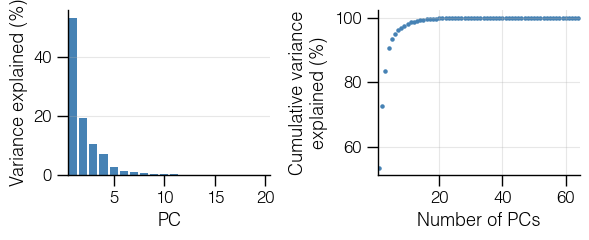

PCs to reach 90%: 4
PCs to reach 95%: 7


In [16]:
dir_path = PASSING_NETWORKS[0]

traj_data = {}

for env_idx in range(15):
    traj_data_raw = load_trajectory_data(dir_path)
    traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
    for key in traj_data_env.keys():
        if key in traj_data:
            traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
        else:
            traj_data[key] = traj_data_env[key]
    
pca = PCA()
pca.fit(traj_data['actor_hidden'])
pc_activities = pca.transform(traj_data['actor_hidden'])

fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))

evr  = pca.explained_variance_ratio_
cumr = np.cumsum(evr)
pcs  = np.arange(1, len(evr) + 1)

axes[0].bar(pcs, evr * 100, color='steelblue', width=0.8)
axes[0].set_xlabel('PC')
axes[0].set_ylabel('Variance explained (%)')
axes[0].set_xlim(0.5, min(20, len(evr)) + 0.5)
axes[0].grid(True, axis='y', alpha=0.3)

axes[1].scatter(pcs, cumr * 100, marker='o', s=5, color='steelblue')
axes[1].set_xlabel('Number of PCs')
axes[1].set_ylabel('Cumulative variance\nexplained (%)')
axes[1].set_xlim(0.5, len(evr) + 0.5)
axes[1].grid(True, alpha=0.3)

format_plot(axes)

plt.tight_layout()
plt.show()

print(f'PCs to reach 90%: {np.searchsorted(cumr, 0.90) + 1}')
print(f'PCs to reach 95%: {np.searchsorted(cumr, 0.95) + 1}')

### Plot single patch dynamics for each patch type
Hidden state trajectories are cylindrical spirals when projected into 3D. These trajectories rapidly circularly oscillate, but also follow a slower time course along a third dimension.

In [17]:
for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx}: {dir_path} ===')

    if net_idx != 1:
        continue

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])
    pc_activities = pca.transform(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===
=== Network 1: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl ===
Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3667, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_2321013/2381507914.py", line 10, in <module>
    traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
                    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/david.bell/work/favorably_connected_2/code/nb_analysis_tools.py", line None, in parse_behavioral_data
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 2176, in showtraceback
    stb = self.InteractiveTB.structured_traceback(
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/david.bell/anaconda3/envs/favorably_connected/lib/python3

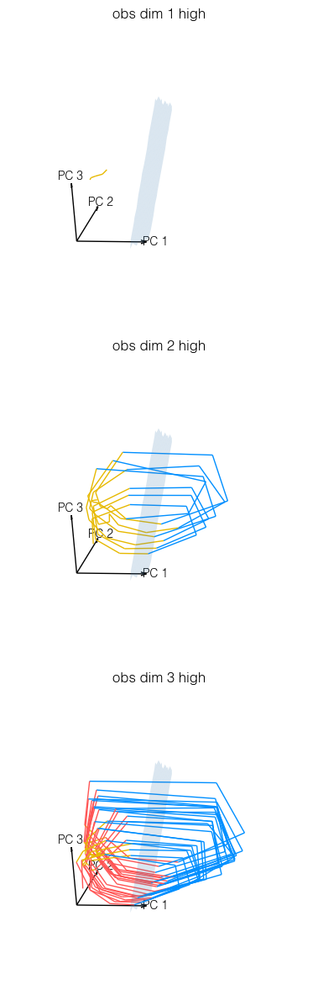

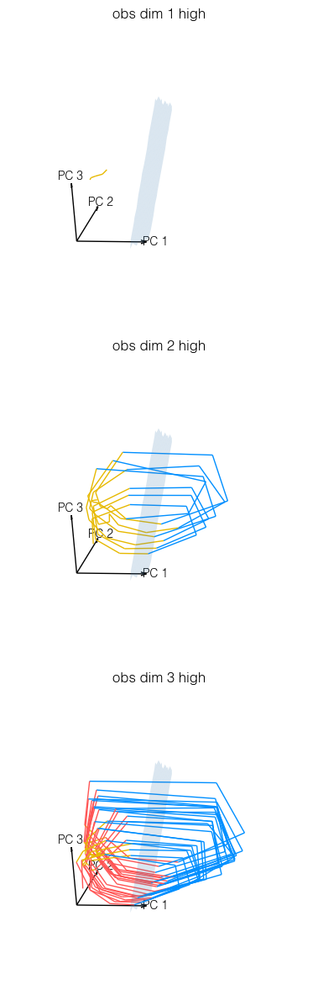

In [ ]:
plot_patch_trajectories_3d(
    traj_data,
    max_trajectories=1,
    params=net_params,
    pca=pca,
    rz=80, rx=20, ry=0,
    input_color_map=[
        (np.array([1, 0, 0, 1, 0, 1, 0]), '#ff5555'),
        (np.array([1, 0, 0, 1, 1, 0, 0]), '#008fff'),
        (np.array([1, 0, 0, 1, 1, 0, 1]), '#008fff'),
        (np.array([1, 0, 0, 0, 0, 1, 0]), '#e7b900'),
    ]
)

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===


/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Light.
  fig.canvas.print_figure(bytes_io, **kw)


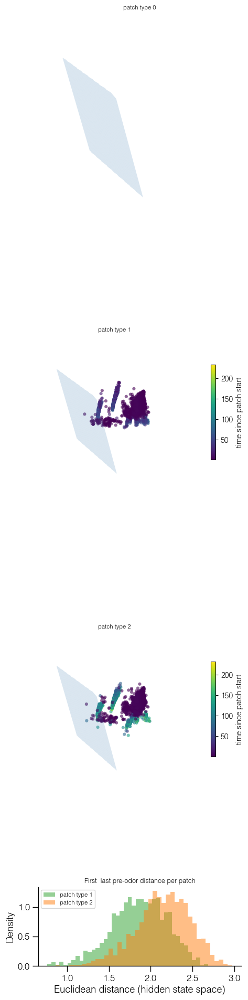

=== Network 1: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl ===


/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Light.
  fig.canvas.print_figure(bytes_io, **kw)


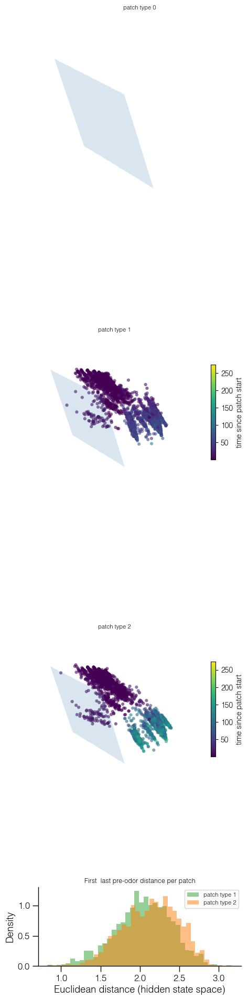

=== Network 2: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl ===


/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Light.
  fig.canvas.print_figure(bytes_io, **kw)


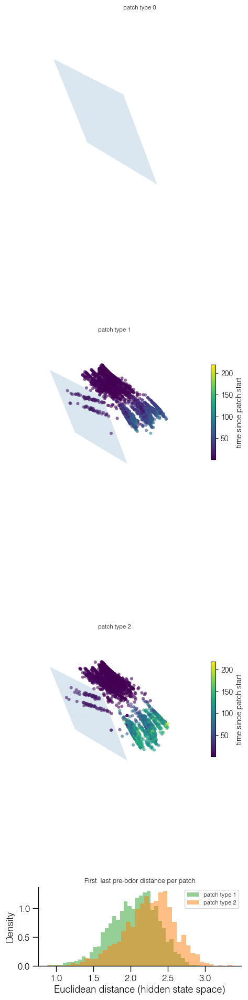

In [ ]:
for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx}: {dir_path} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    fig = plot_patch_endpoints_3d(traj_data, pca, params=net_params, azim=60, plot_starts=True, plot_ends=True)
    plt.show()

### Fixed points of trained networks
Trained networks show a few common features:
1. A single fixed point or cluster of fixed points when the visual cue is off.
1. The emergence of a line of marginally stable fixed points when the visual cue is turned on and the agent is running.


Network 0


Trial 0, patch 3  (global steps 447–564, length 118)  → 70 segments with ≥2 steps


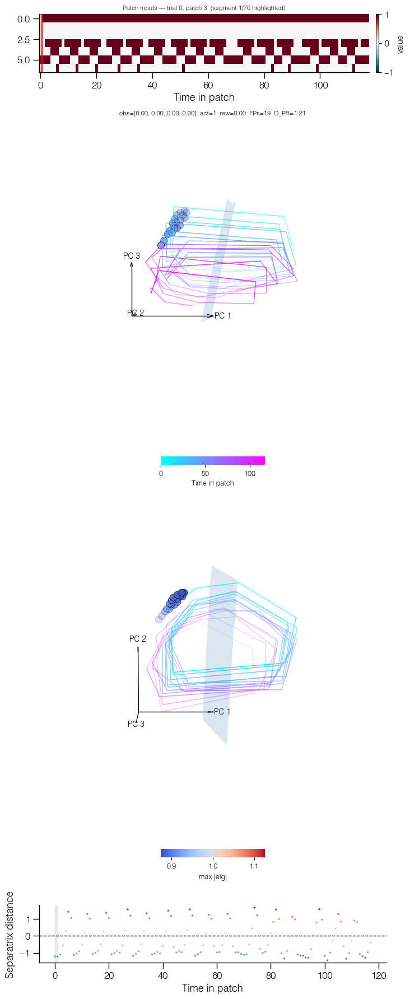

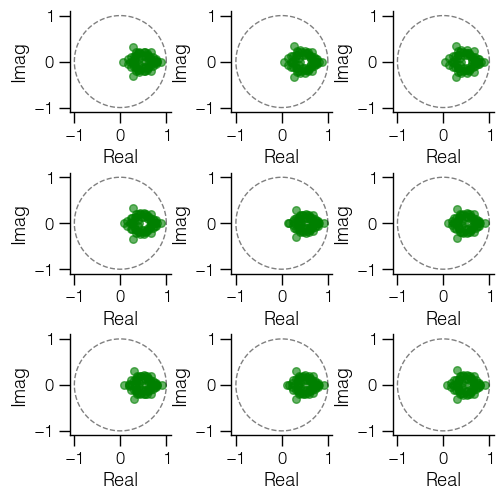

<Figure size 640x480 with 0 Axes>

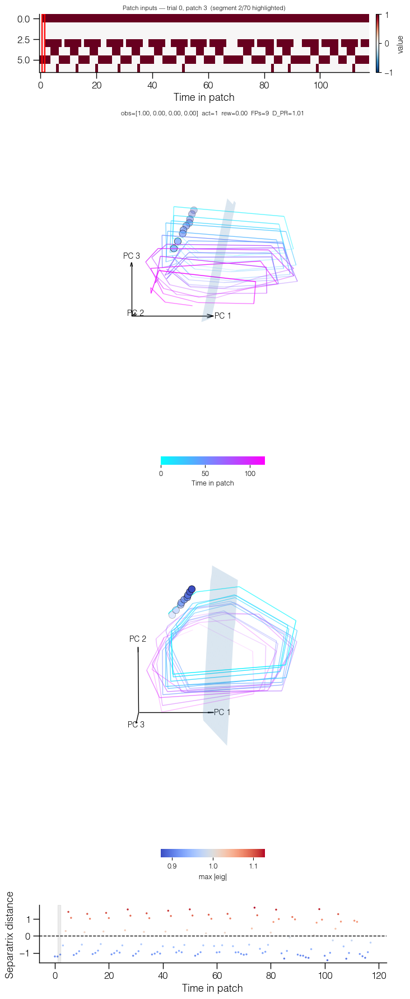

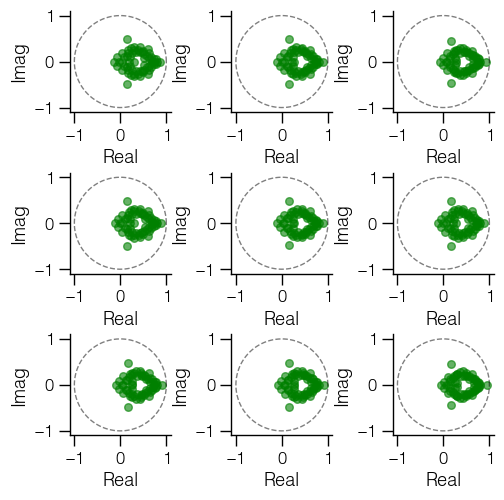

<Figure size 640x480 with 0 Axes>

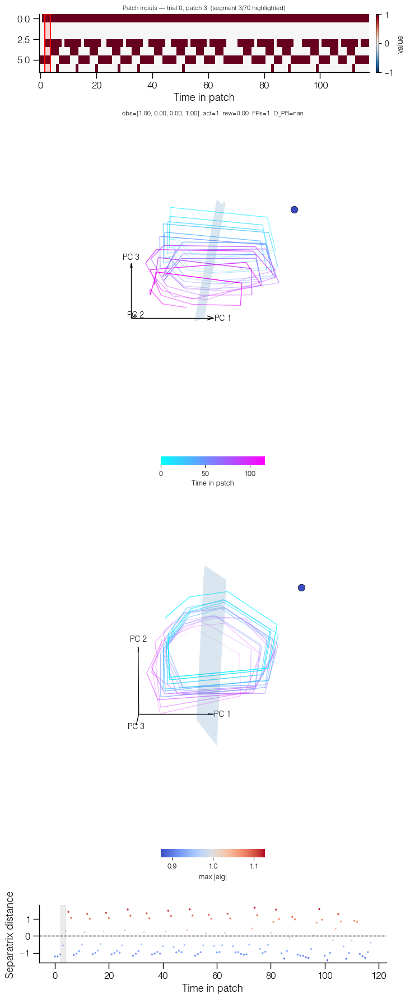

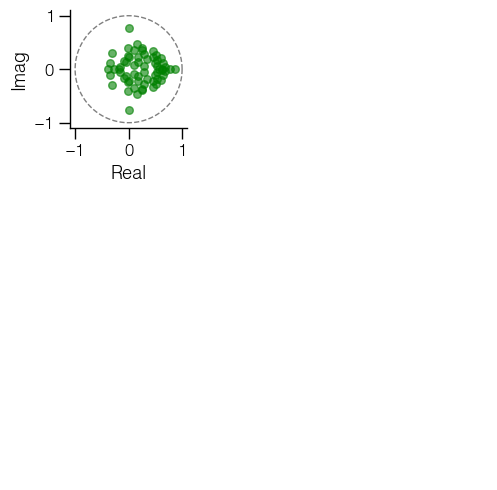

<Figure size 640x480 with 0 Axes>

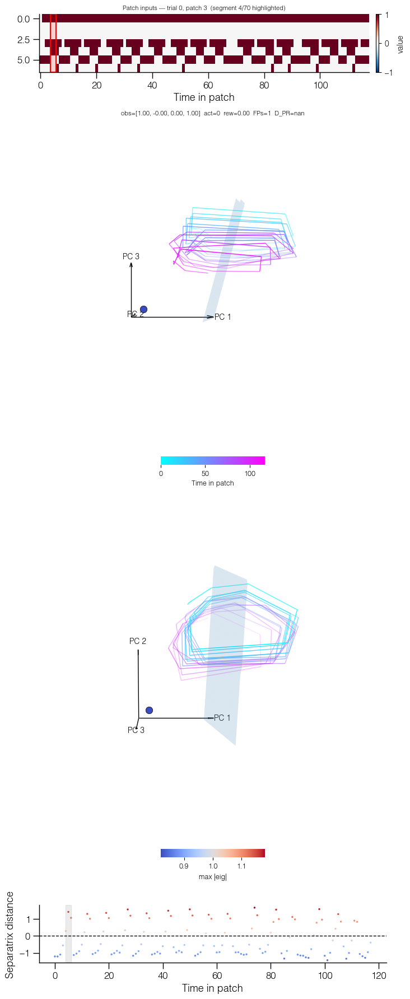

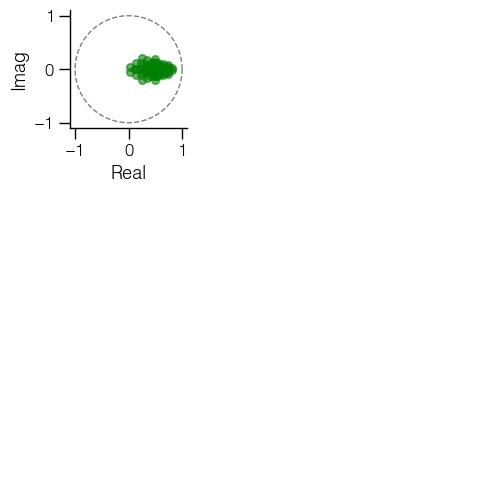

<Figure size 640x480 with 0 Axes>

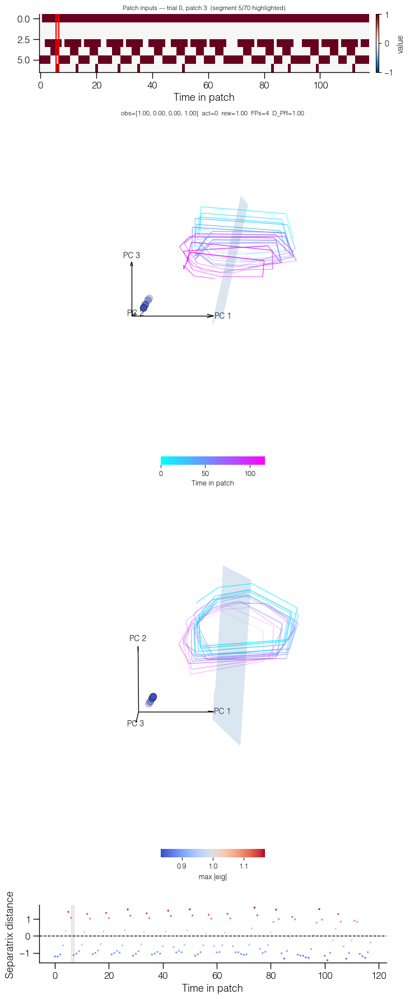

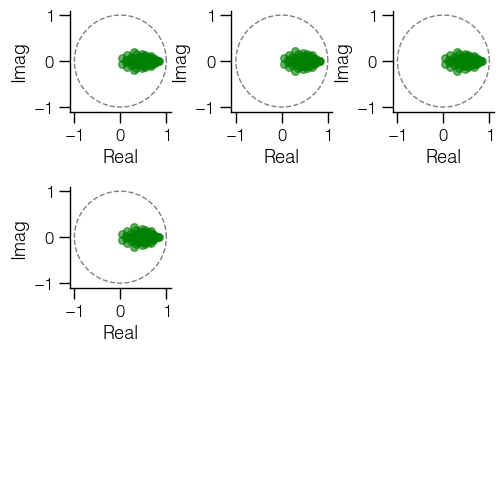

<Figure size 640x480 with 0 Axes>

Trial 0, patch 3  (global steps 447–564, length 118)  → 5 unique inputs


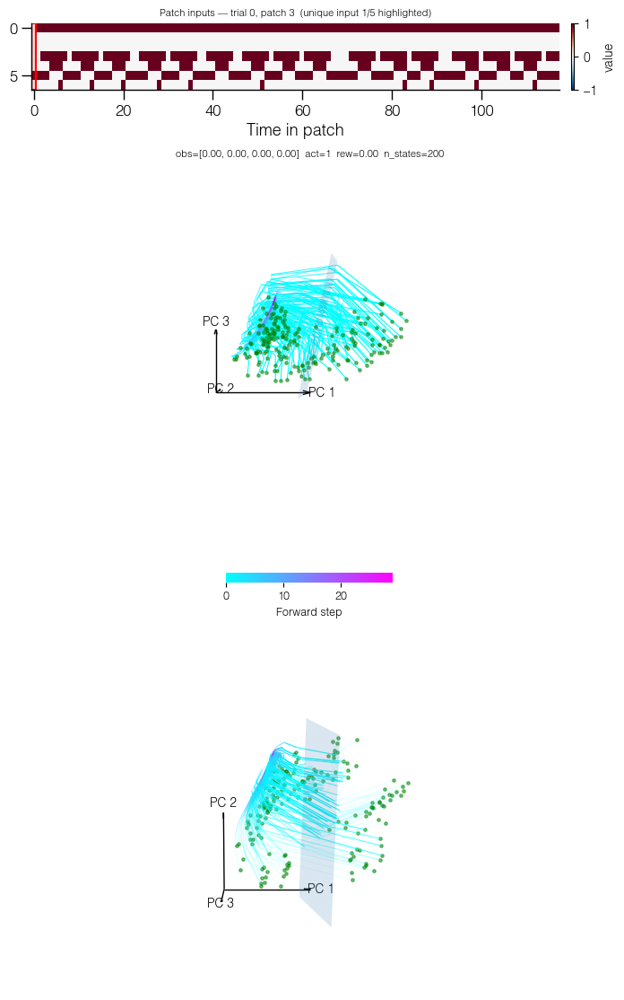

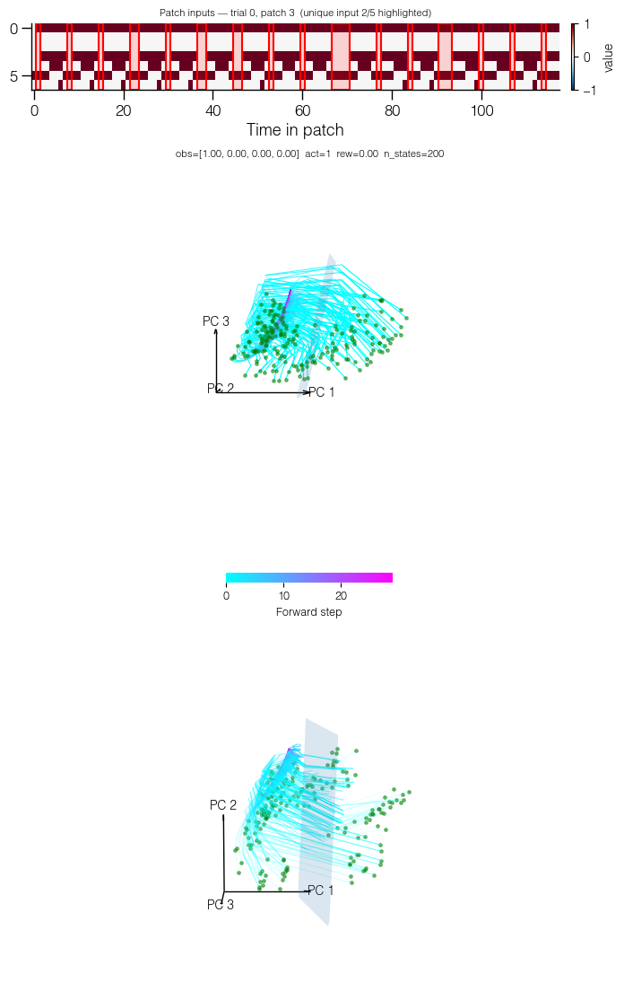

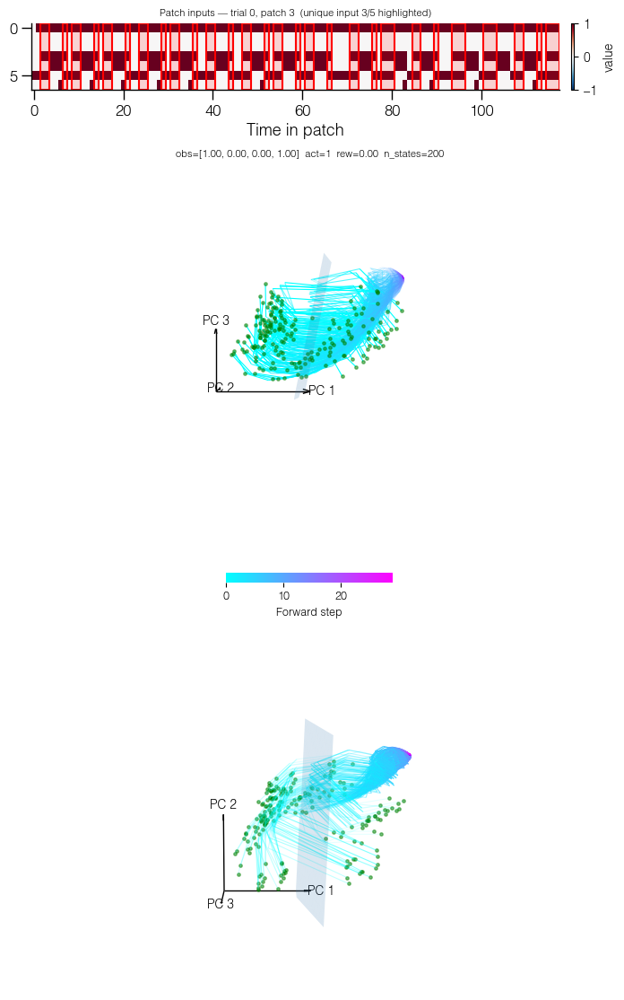

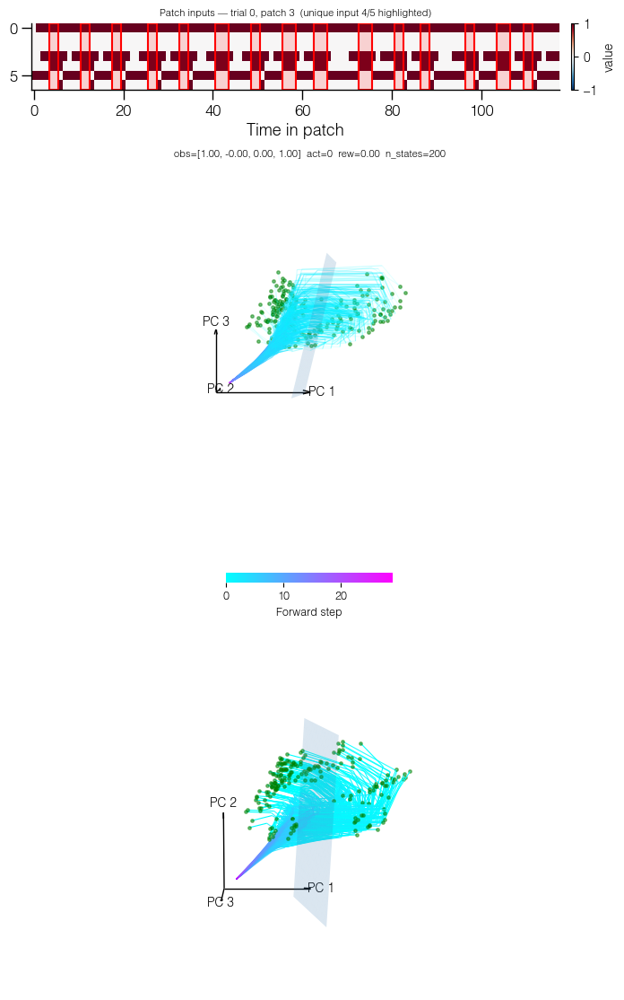

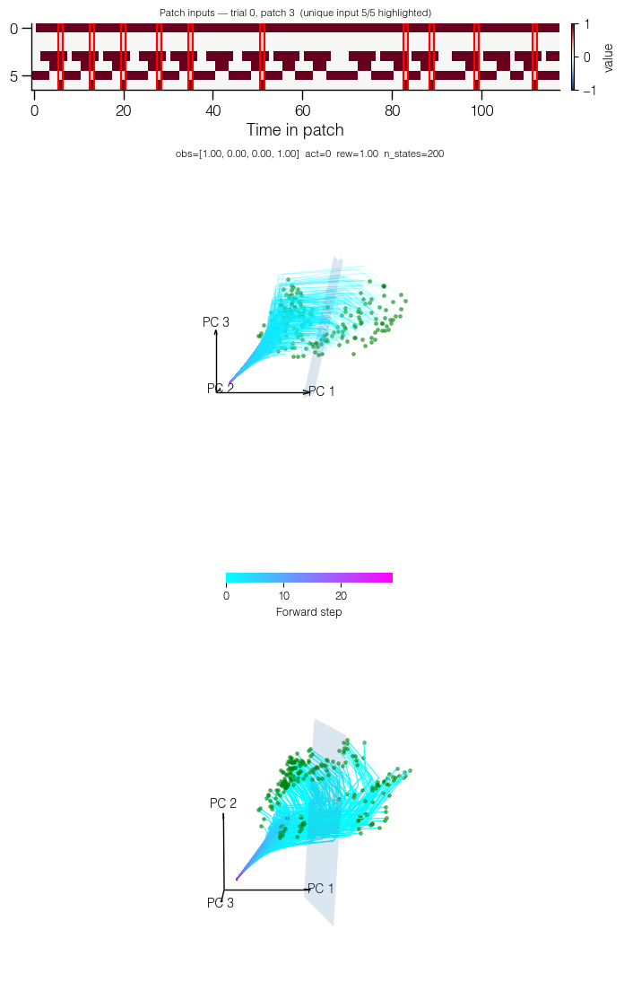

In [ ]:
for net_idx, (traj_path, ckpt_path) in enumerate(
    zip(FIXED_EXP_GRU_INITIAL_PROB_OFFSET_NETWORKS, FIXED_EXP_GRU_INITIAL_PROB_OFFSET_CHECKPOINTS)
):
    if net_idx != 0:
        continue
    print(f'{"="*60}')
    print(f'Network {net_idx}')
    print(f'{"="*60}')

    # Load trajectory data and fit PCA
    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(traj_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])
    pc_activities = pca.transform(traj_data['actor_hidden'])

    # Load checkpoint params for this network
    restored   = checkpoints.restore_checkpoint(
            ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = restored.params

    plot_patch_segments_with_fixed_points(
        traj_data, net_params, network, pca,
        trial_idx=0,
        patch_idx=3,
        patch_type=2,
        n_fp_attempts=300,
        fp_tol=5e-3,
        azim=270,
        elev=0,
        azim2=90 + 180,
        elev2=160 + -60,
        includes_actions_and_rewards=True,
        stop_after_unique_inputs=True,
        traj_cmap=sns.color_palette(palette='cool', as_cmap=True),
        save_dir=os.path.join('../../../figures', Path(traj_path).parent.name),
        plot_current_segment=False,
    )

    plot_patch_segments_forward_runs(
        traj_data, net_params, network, pca,
        trial_idx=0,
        patch_idx=3,
        patch_type=2,
        n_states=200,
        n_forward_steps=30,
        azim=270,
        elev=0,
        azim2=90 + 180,
        elev2=160 + -60,
        includes_actions_and_rewards=True,
        traj_cmap=sns.color_palette(palette='cool', as_cmap=True),
        save_dir=os.path.join('../../../figures', Path(traj_path).parent.name),
    )

### States immediately prior to odor onset
Within a patch but immediately prior to odor onset, states have graded accumulated reward representations. They also contain significant information about the duration of the inter site interval immediately prior to them. 

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===


Patch 1: plotting 2000/8375 points (23.9%)
Patch 2: plotting 2000/24386 points (8.2%)
Patch 1: plotting 2000/8375 points (23.9%)
Patch 2: plotting 2000/24386 points (8.2%)
Patch 1: plotting 2000/8375 points (23.9%)
Patch 2: plotting 2000/24386 points (8.2%)


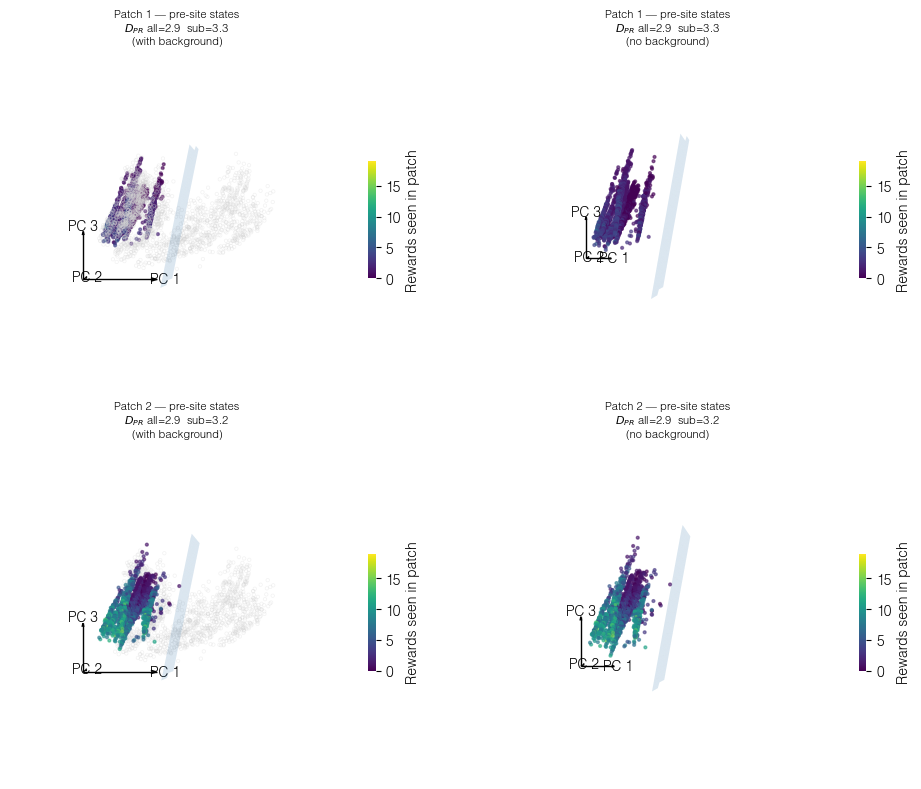

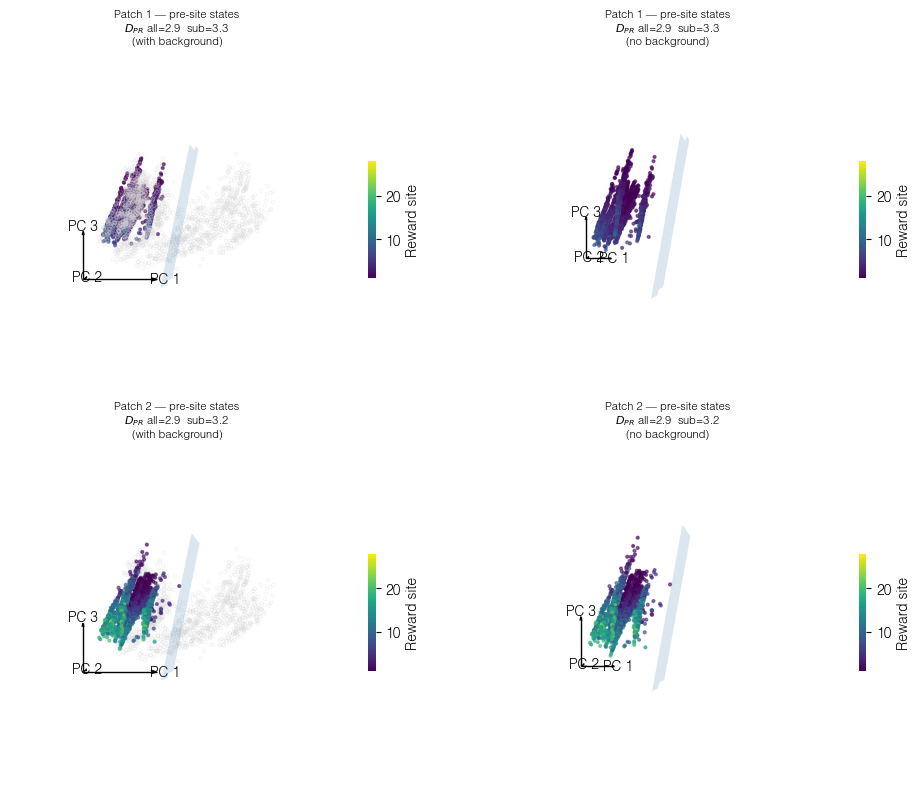

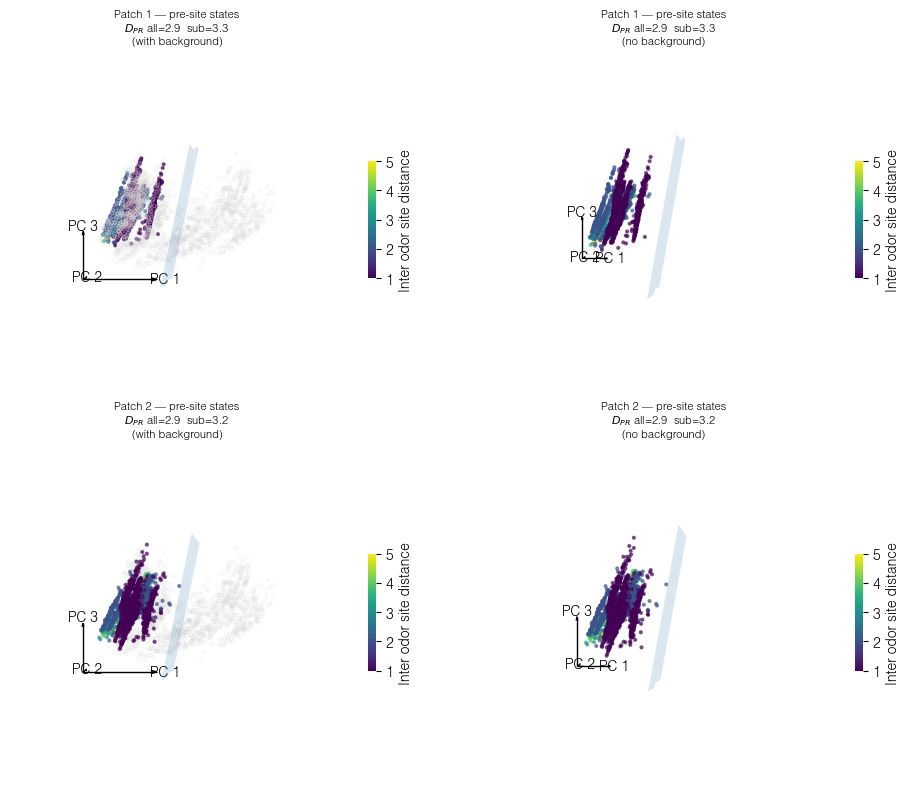

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

=== Network 1: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl ===


Patch 1: plotting 2000/10183 points (19.6%)
Patch 2: plotting 2000/22596 points (8.9%)
Patch 1: plotting 2000/10183 points (19.6%)
Patch 2: plotting 2000/22596 points (8.9%)
Patch 1: plotting 2000/10183 points (19.6%)
Patch 2: plotting 2000/22596 points (8.9%)


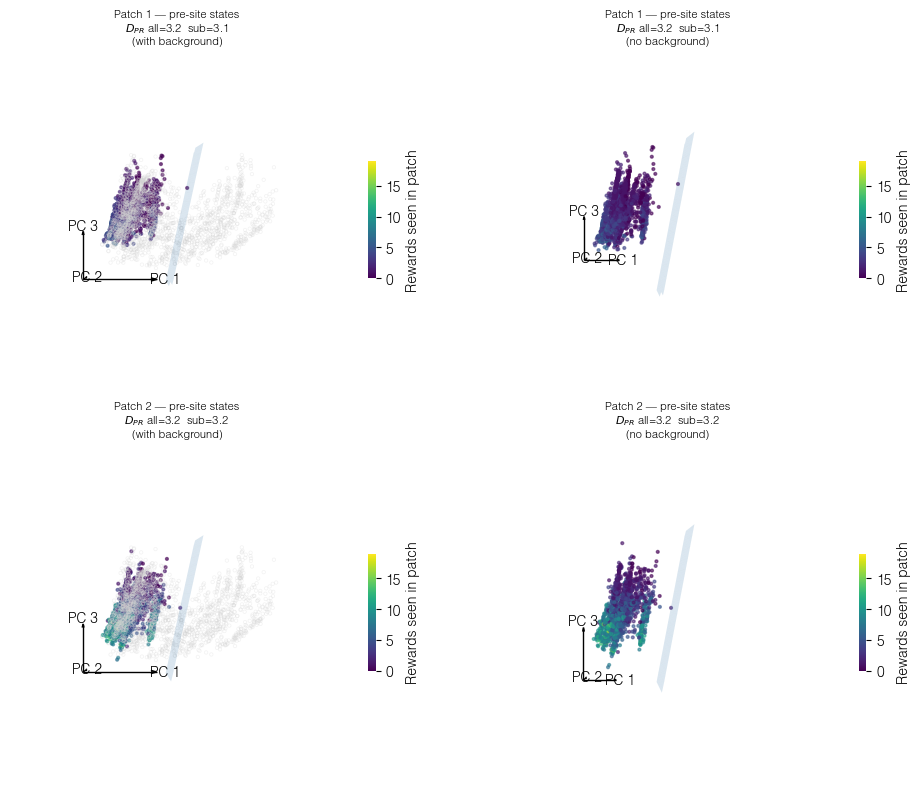

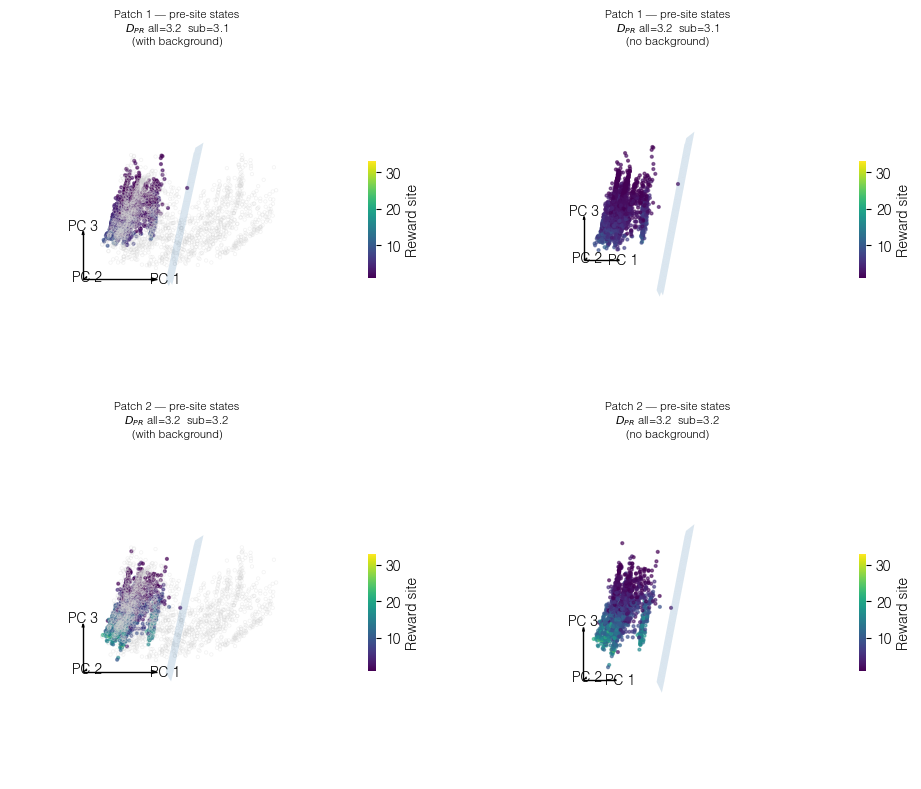

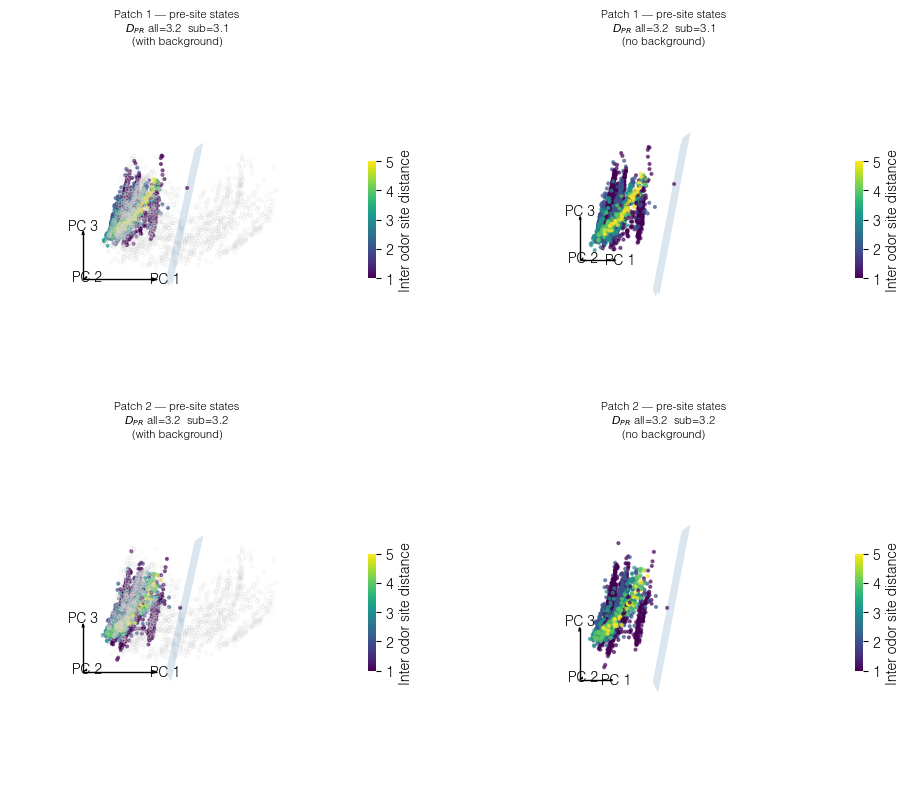

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

=== Network 2: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl ===


Patch 1: plotting 2000/9389 points (21.3%)
Patch 2: plotting 2000/23181 points (8.6%)
Patch 1: plotting 2000/9389 points (21.3%)
Patch 2: plotting 2000/23181 points (8.6%)
Patch 1: plotting 2000/9389 points (21.3%)
Patch 2: plotting 2000/23181 points (8.6%)


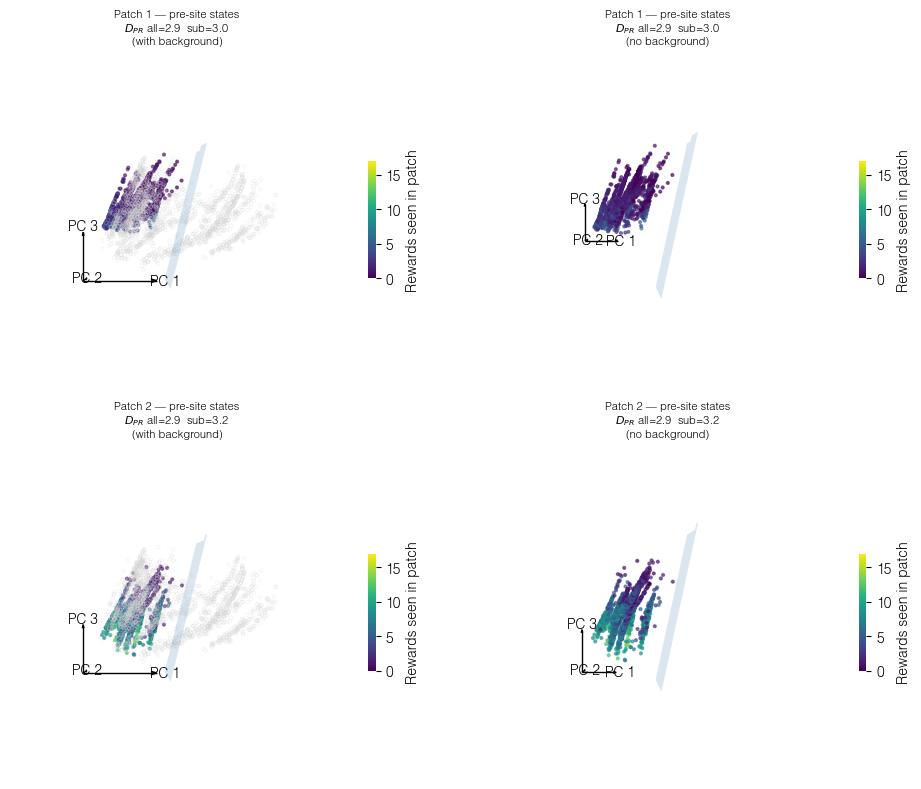

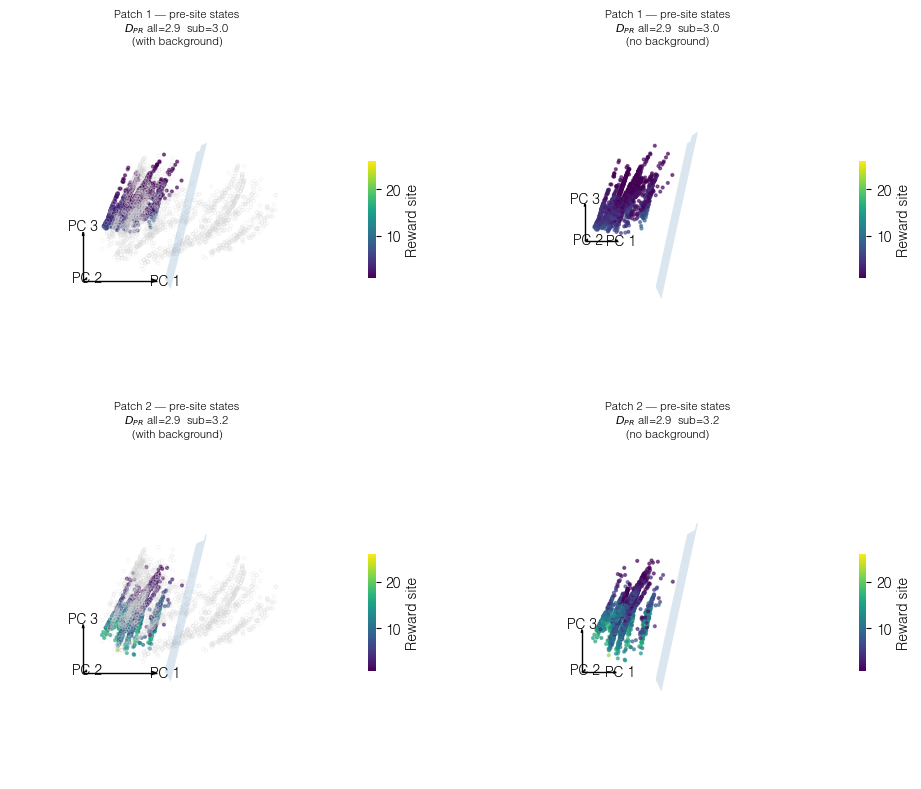

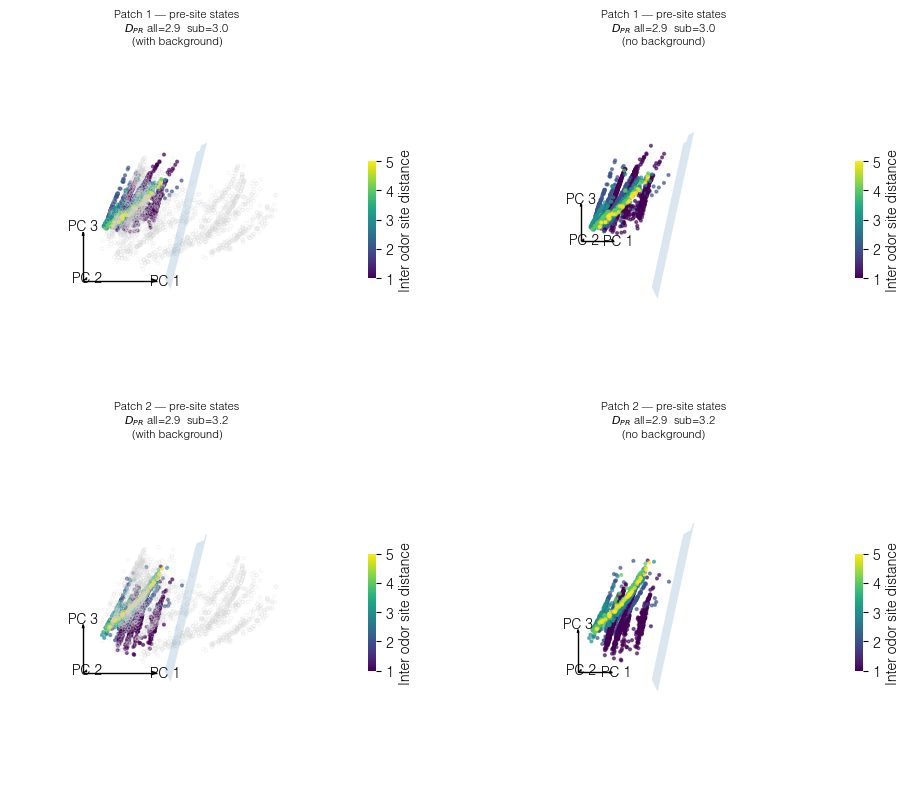

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

=== Network 3: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net3/trajectories_20260529_160251.pkl ===


Patch 1: plotting 2000/8352 points (23.9%)
Patch 2: plotting 2000/23077 points (8.7%)
Patch 1: plotting 2000/8352 points (23.9%)
Patch 2: plotting 2000/23077 points (8.7%)
Patch 1: plotting 2000/8352 points (23.9%)
Patch 2: plotting 2000/23077 points (8.7%)


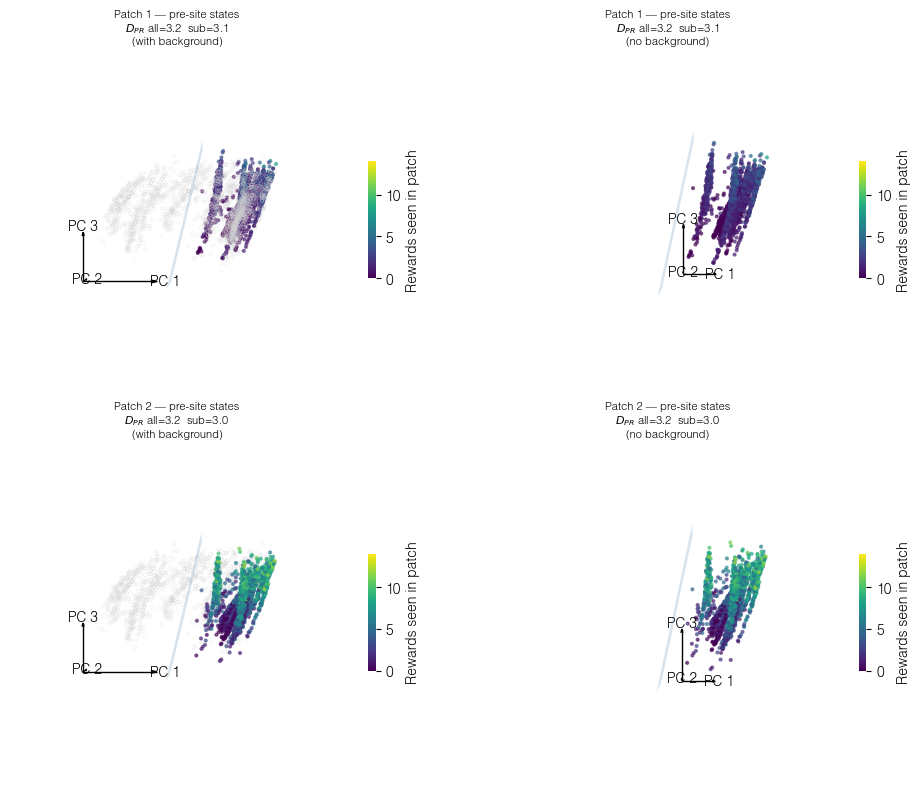

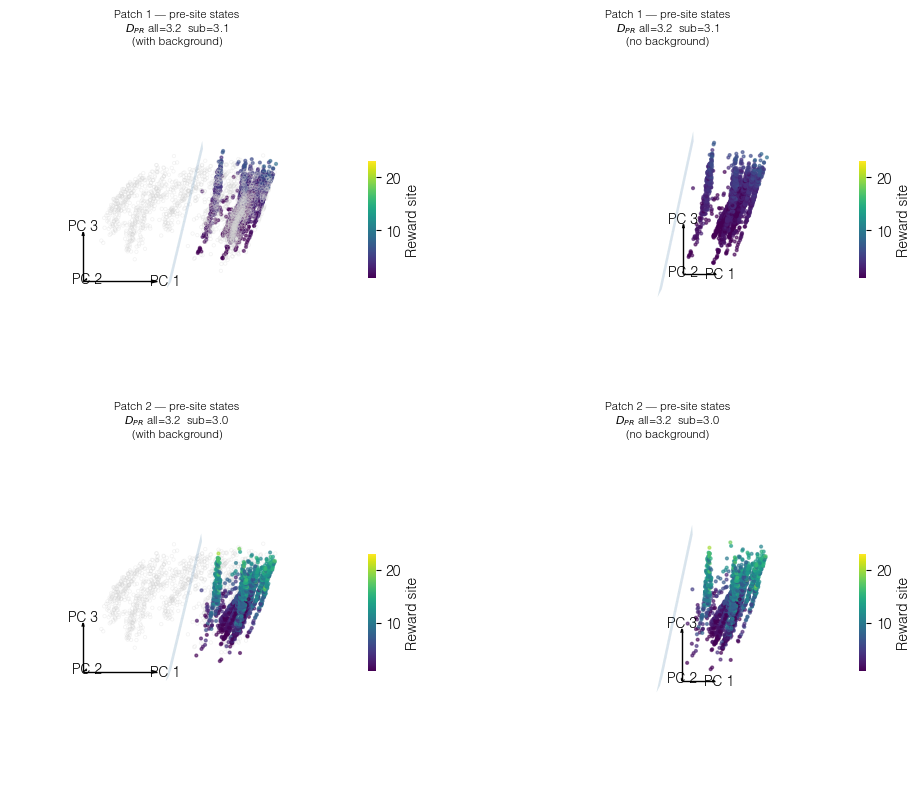

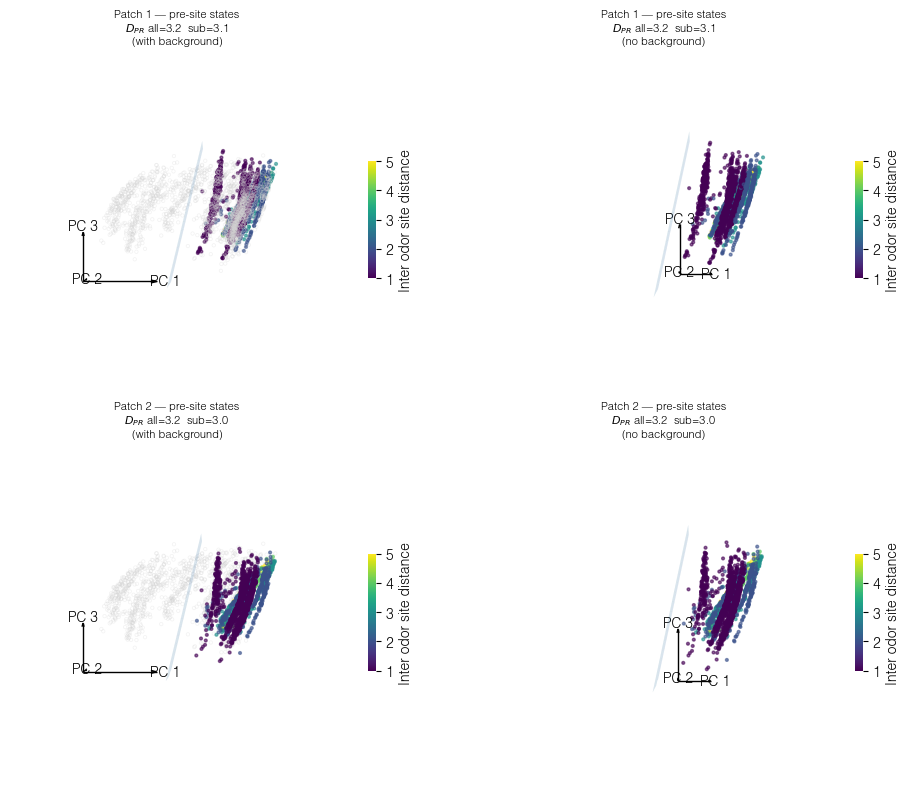

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

=== Network 4: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net4/trajectories_20260529_163734.pkl ===


Patch 1: plotting 2000/8868 points (22.6%)
Patch 2: plotting 2000/24434 points (8.2%)
Patch 1: plotting 2000/8868 points (22.6%)
Patch 2: plotting 2000/24434 points (8.2%)
Patch 1: plotting 2000/8868 points (22.6%)
Patch 2: plotting 2000/24434 points (8.2%)


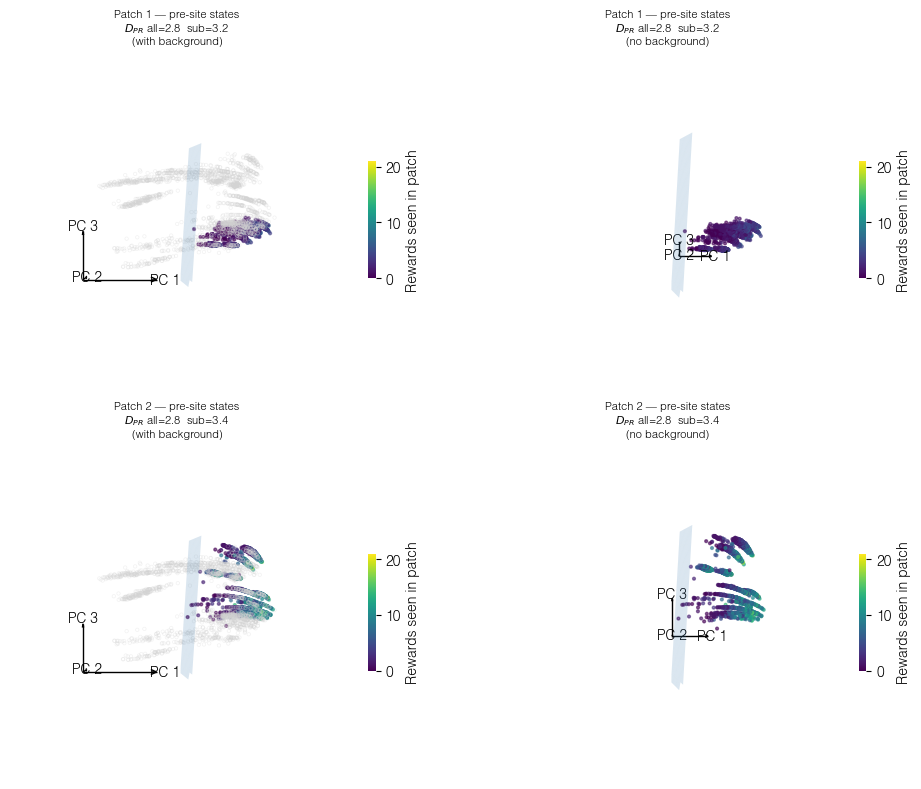

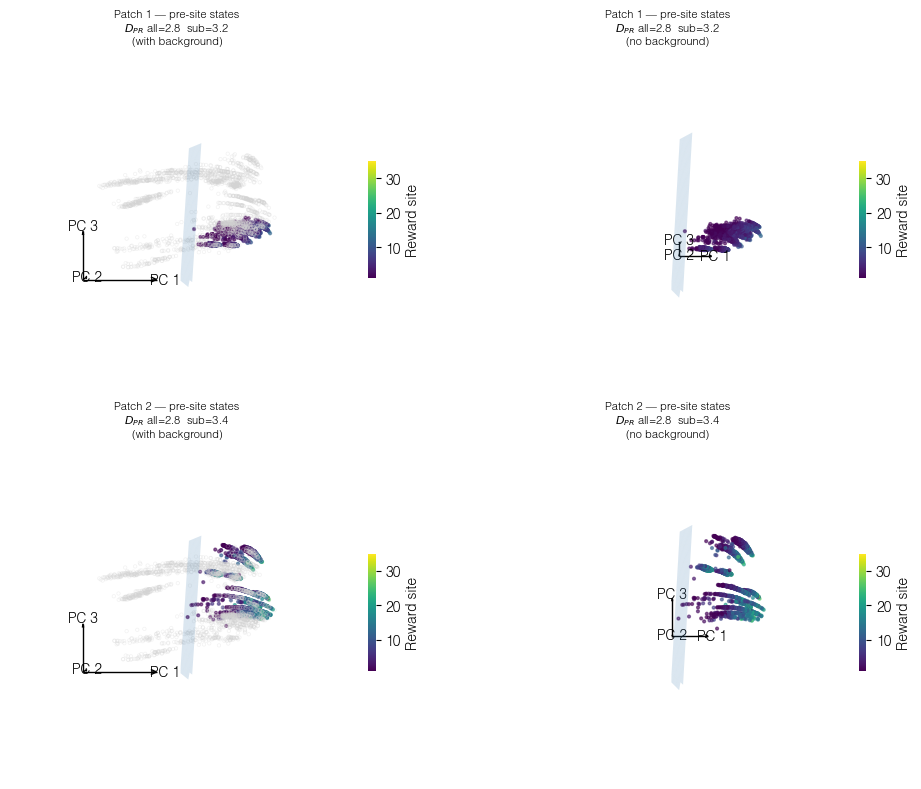

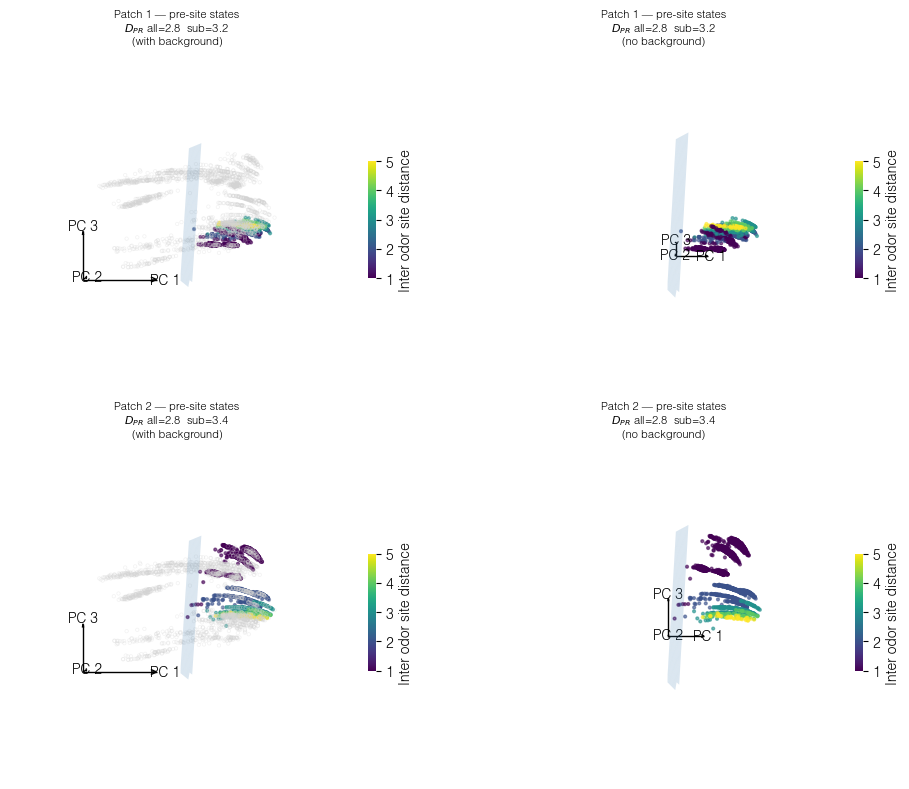

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [ ]:
for net_idx, (dir_path, ckpt_path) in enumerate(zip(PASSING_NETWORKS, PASSING_CHECKPOINTS)):
    print(f'=== Network {net_idx}: {dir_path} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])
    pc_activities = pca.transform(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    network_name = Path(dir_path).parent.name
    save_dir = os.path.join('../../../figures', network_name)
    os.makedirs(save_dir, exist_ok=True)

    color_bys = ['inter_odor_site_distances', 'rewards_seen_in_patch', 'reward_site_idx']
    colorbar_labels = ['Inter odor site distance', 'Rewards seen in patch', 'Reward site']
    figs = [
        plot_pre_odor_site_states_3d(
            traj_data,
            pca,
            params=net_params,
            color_by=color_by,
            cbar_label=cbar_label,
            azim1=-90, elev1=0, azim2=-90, elev2=0,
            max_points=2000
        )
        for color_by, cbar_label in zip(color_bys, colorbar_labels)
    ]

    for color_by, fig in zip(color_bys, figs):
        plt.figure(fig.number) 
        fig.savefig(os.path.join(save_dir, f'pre_odor_site_states_3d_{color_by}.svg'), bbox_inches='tight')
        plt.show()

=== Network 0 ===


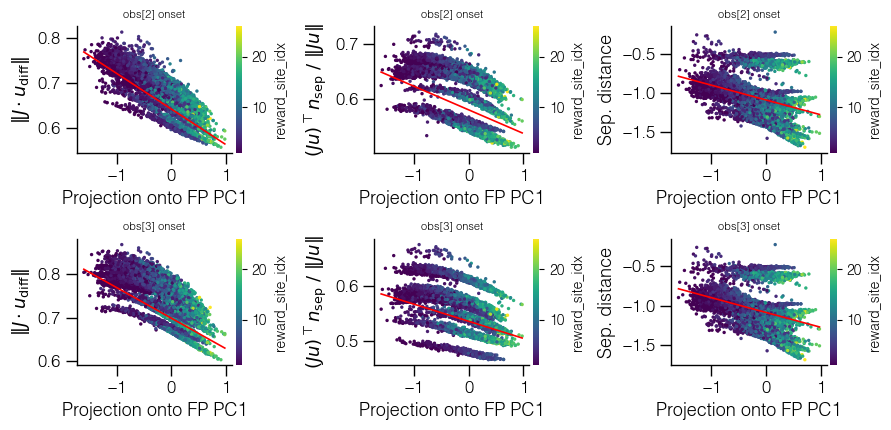

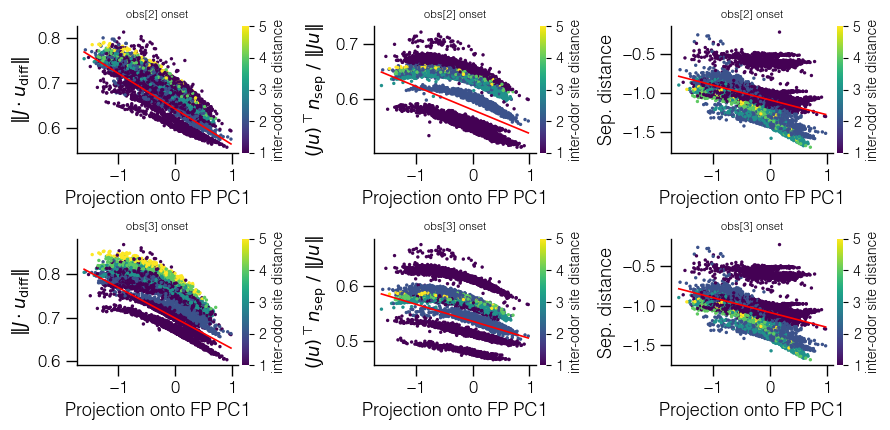

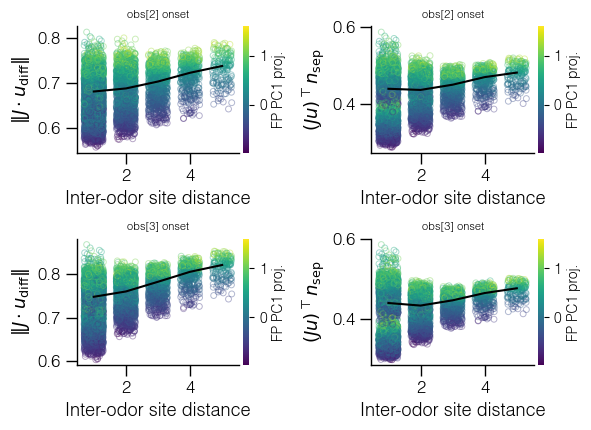

=== Network 1 ===


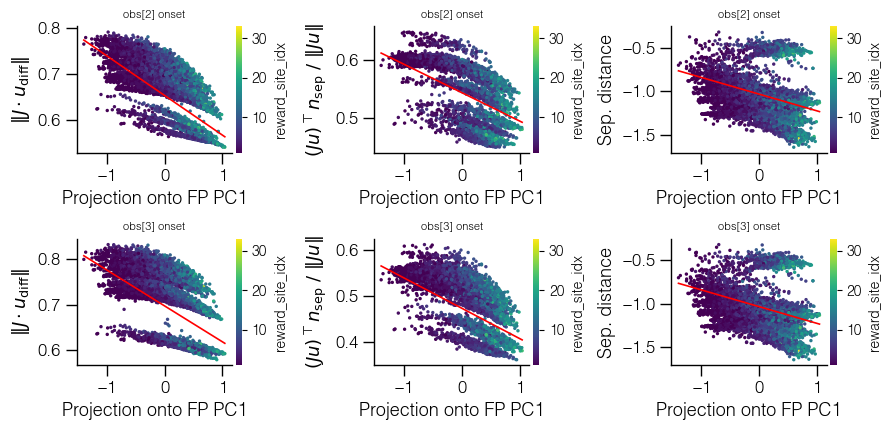

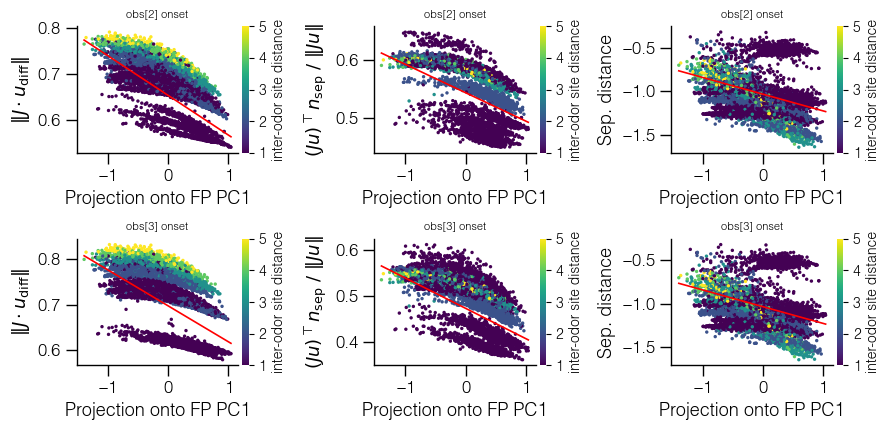

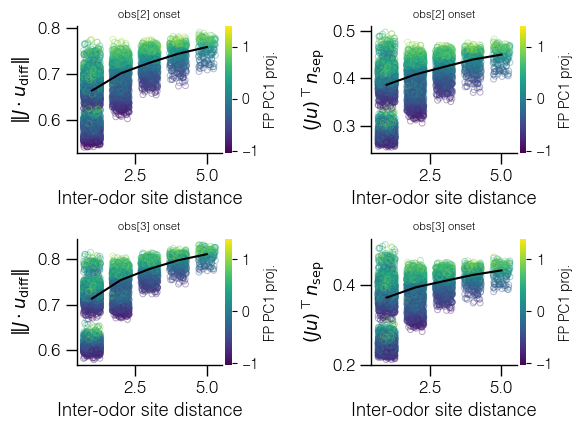

=== Network 2 ===


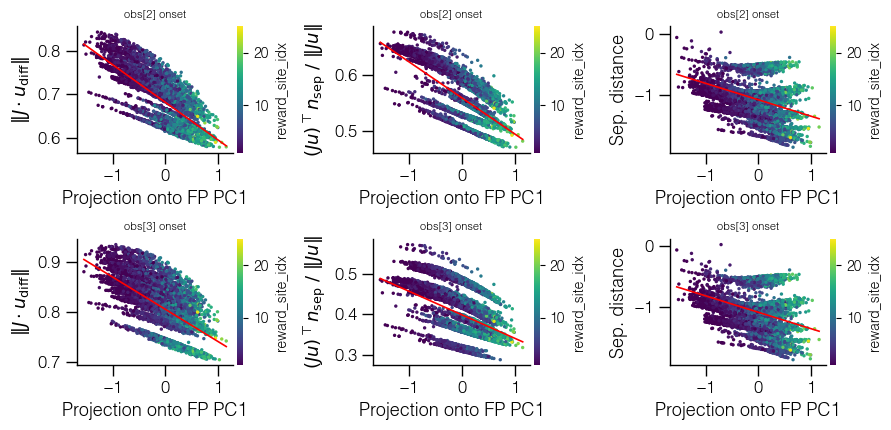

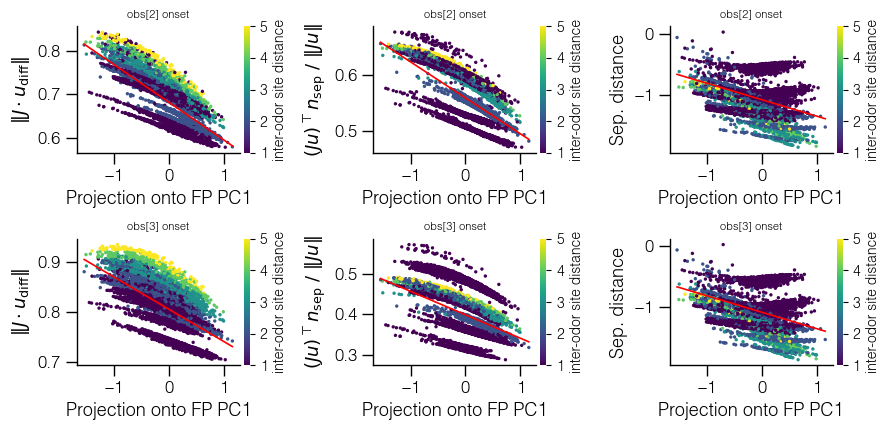

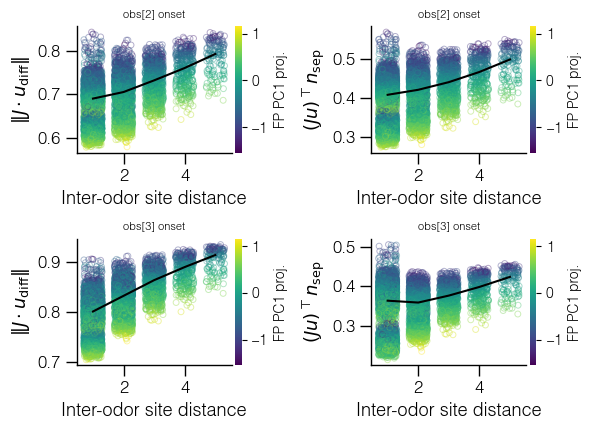

=== Network 3 ===


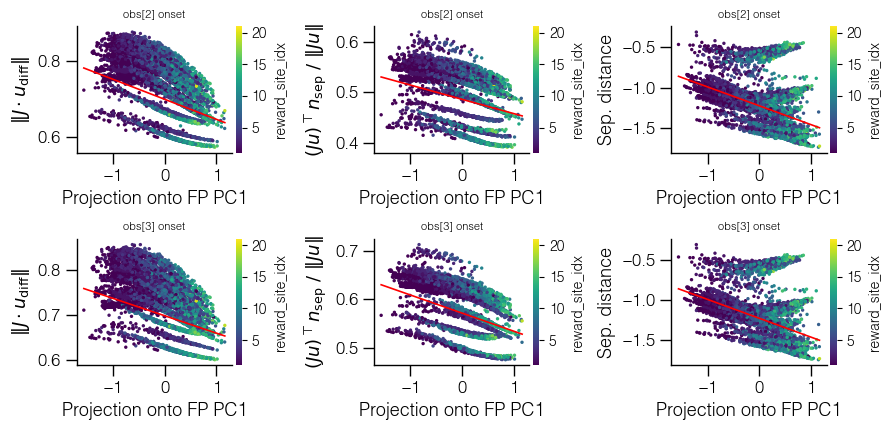

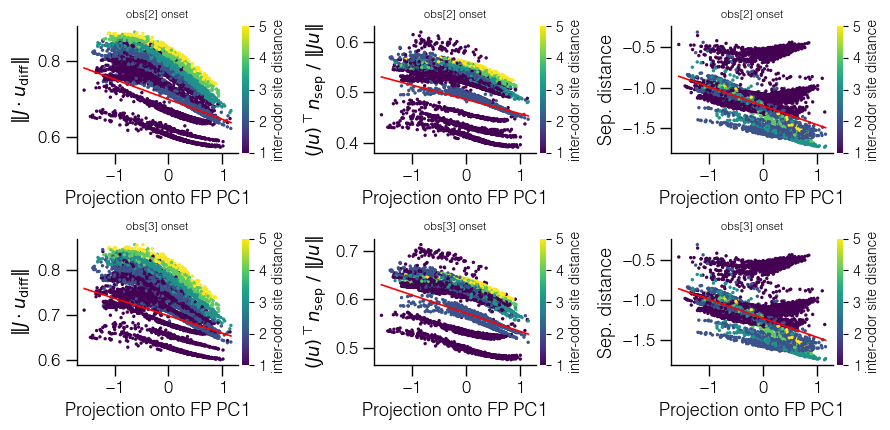

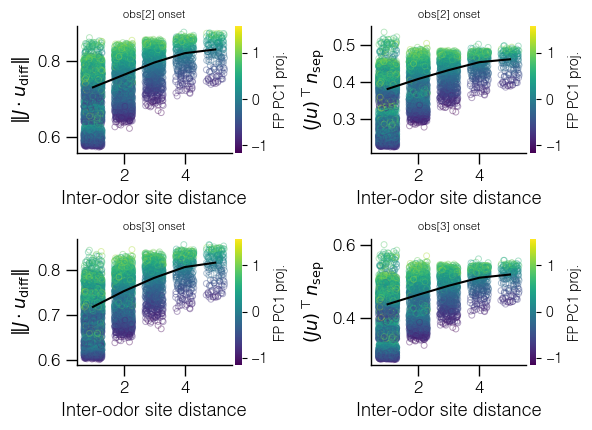

=== Network 4 ===


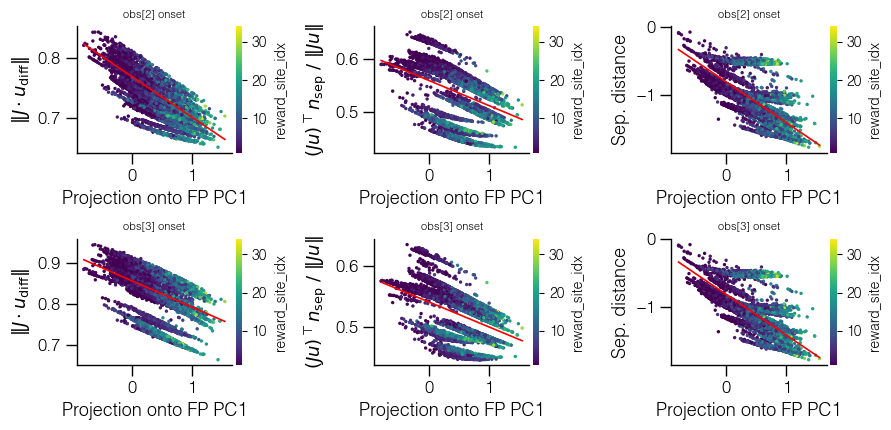

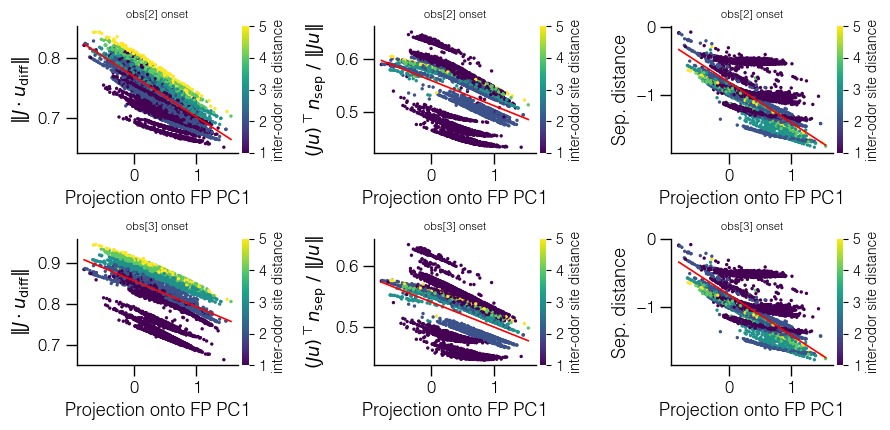

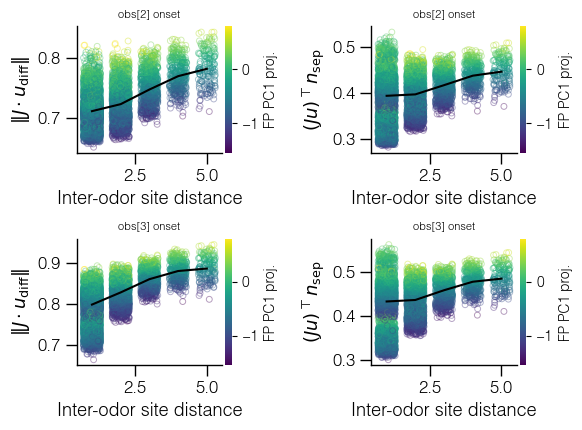

In [ ]:
all_jac2d_slopes = []
all_jac2d_ratios = []
for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(
        ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    # plot_pre_patch_states_jac_3d(traj_data, net_params, network, pca, azim=80, elev=70)
    save_base = f'../../../figures/gru_fixed_exp_decay_net_{net_idx}'
    os.makedirs(save_base, exist_ok=True)

    fig, slopes, ratios = plot_pre_patch_states_jac_2d(traj_data, net_params, network)
    all_jac2d_slopes.append(slopes)
    all_jac2d_ratios.append(ratios)
    fig.savefig(f'{save_base}/jac_2d_reward_site_idx.png', dpi=150, bbox_inches='tight')
    fig.savefig(f'{save_base}/jac_2d_reward_site_idx.svg', bbox_inches='tight')
    plt.show(fig)
    plt.close(fig)

    fig, slopes, ratios = plot_pre_patch_states_jac_2d(traj_data, net_params, network,
                                        color_by='inter_odor_site_distances',
                                        color_label='inter-odor site distance')
    fig.savefig(f'{save_base}/jac_2d_inter_odor.png', dpi=150, bbox_inches='tight')
    fig.savefig(f'{save_base}/jac_2d_inter_odor.svg', bbox_inches='tight')
    plt.show(fig)
    plt.close(fig)

    fig = plot_pre_patch_states_jac_2d_isi(traj_data, net_params, network)
    fig.savefig(f'{save_base}/jac_2d_isi.png', dpi=150, bbox_inches='tight')
    fig.savefig(f'{save_base}/jac_2d_isi.svg', bbox_inches='tight')
    plt.show(fig)
    plt.close(fig)

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===


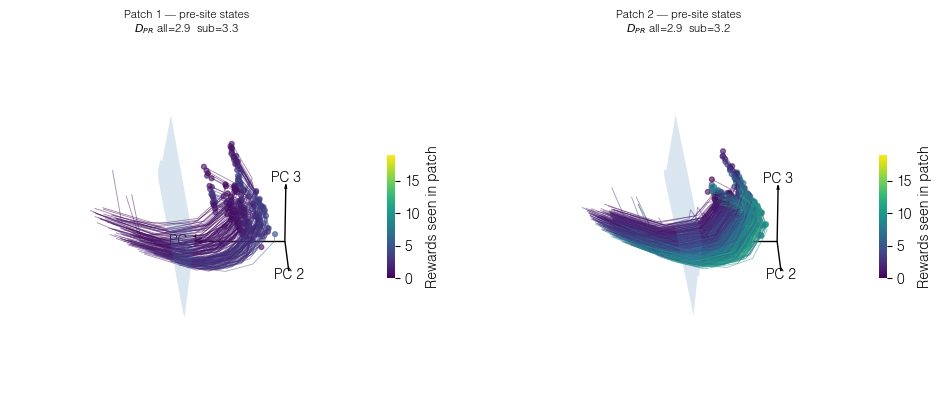

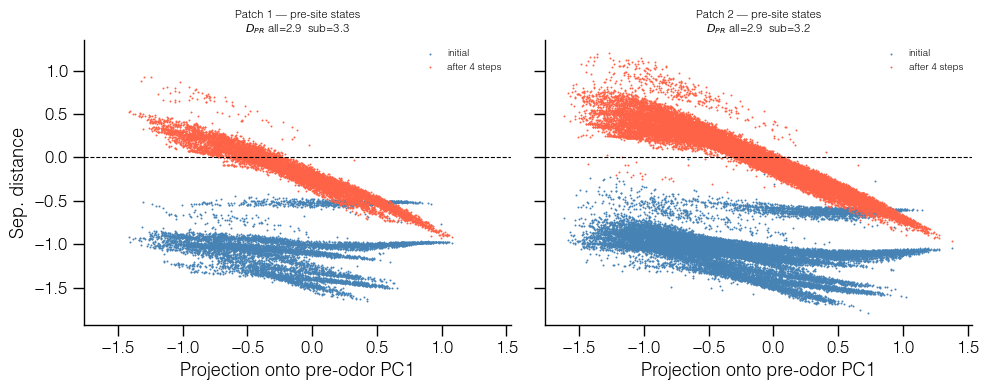

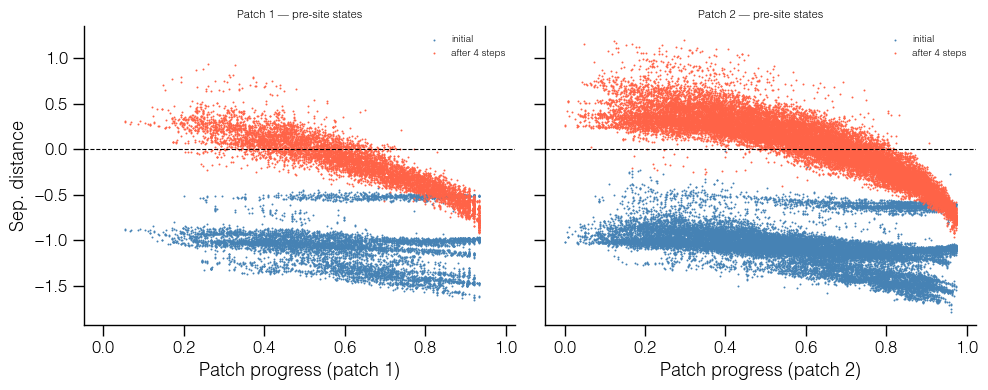

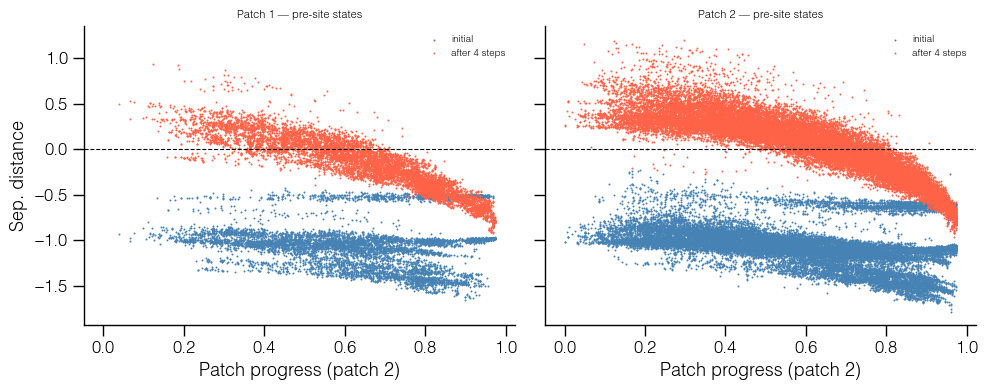

=== Network 1: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl ===


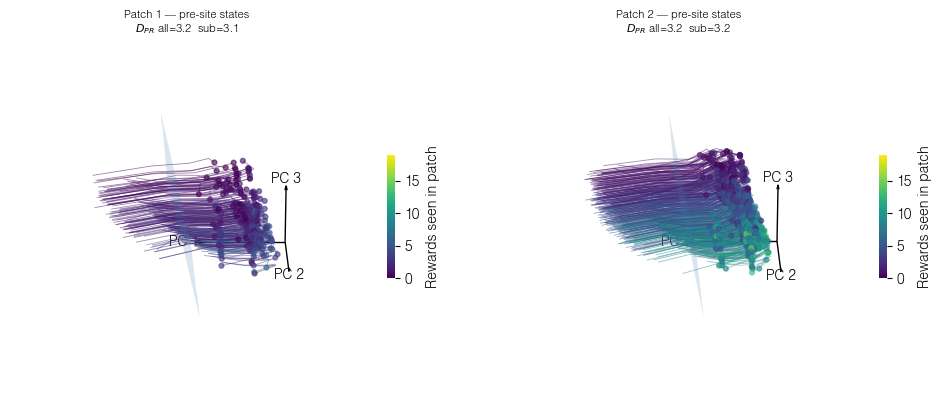

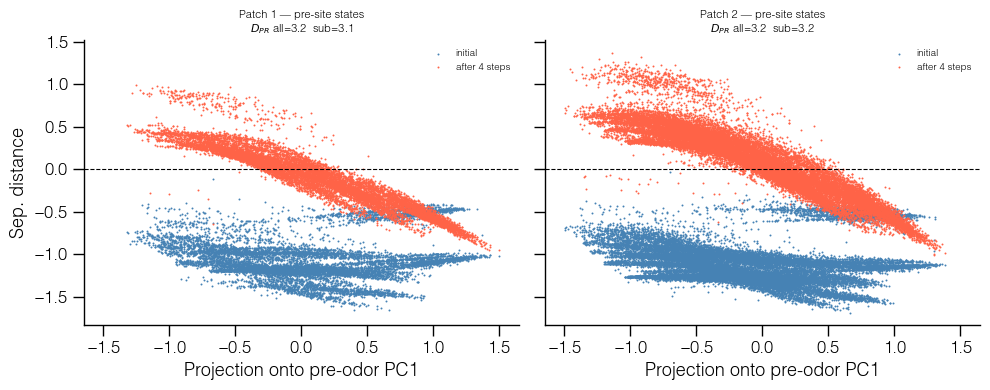

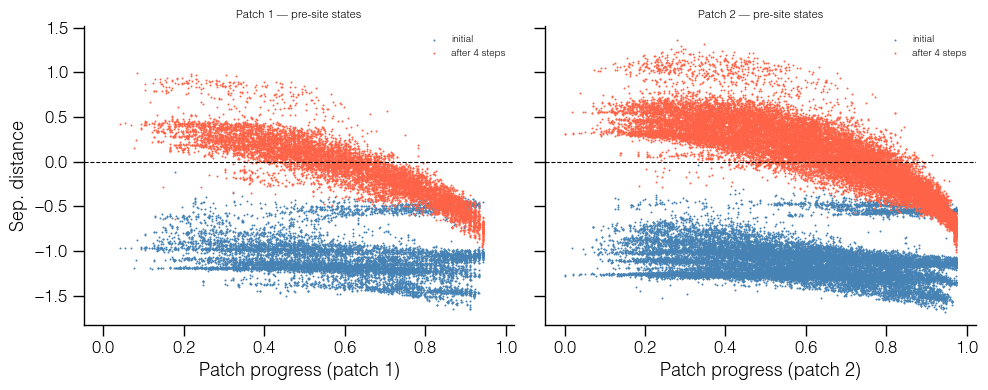

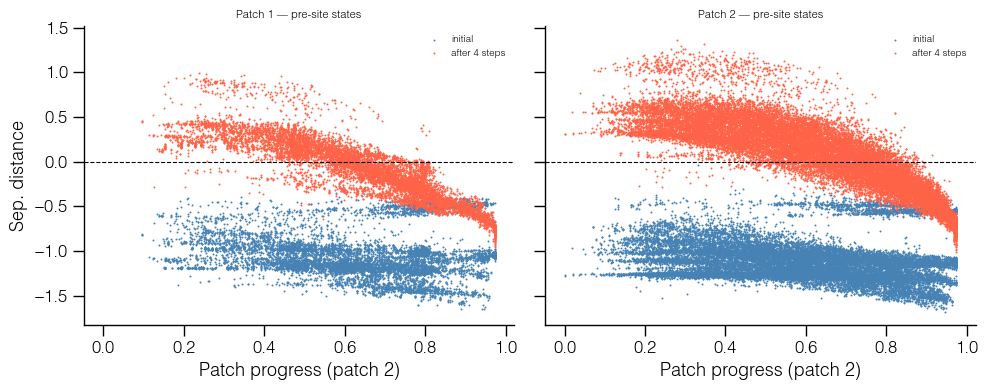

=== Network 2: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl ===


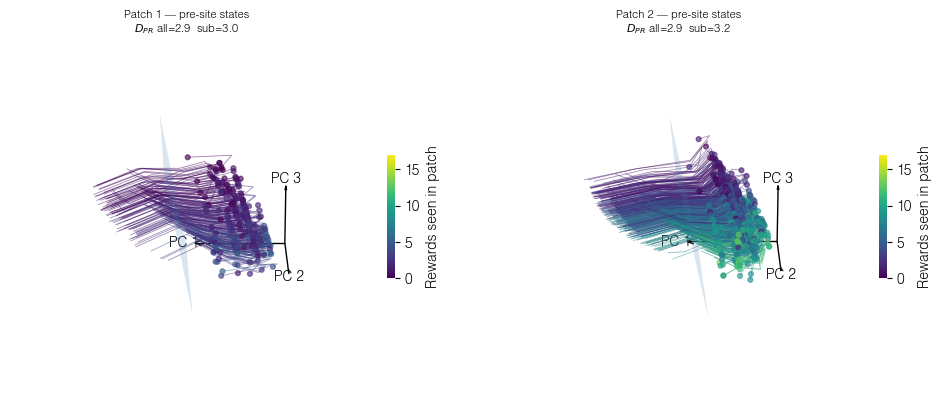

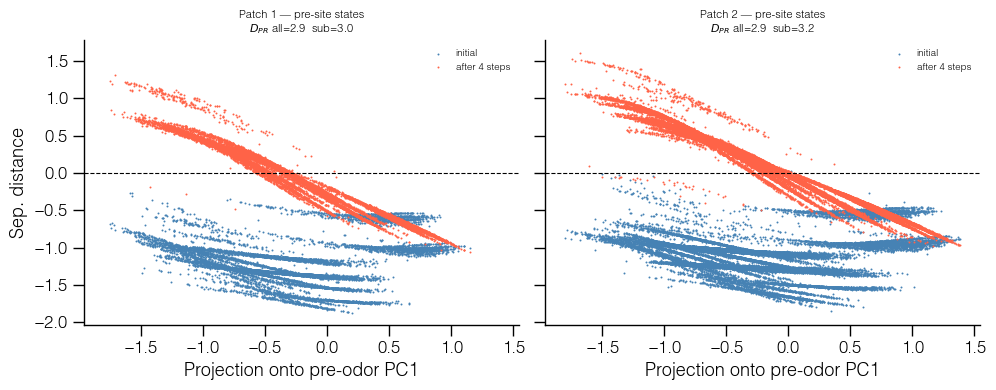

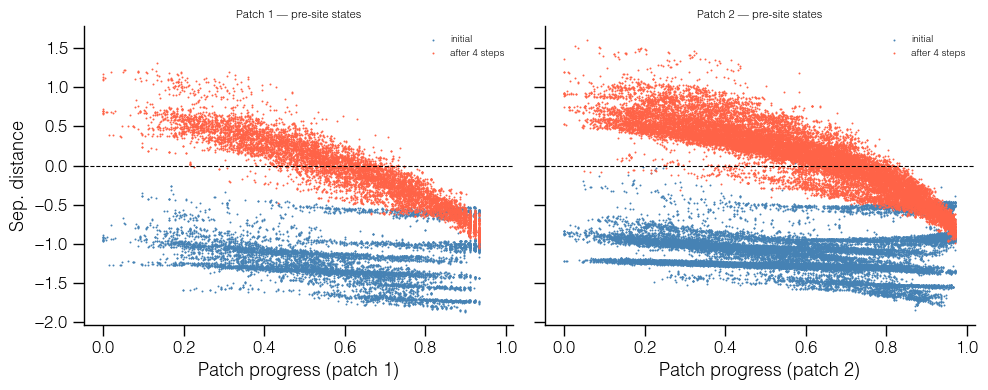

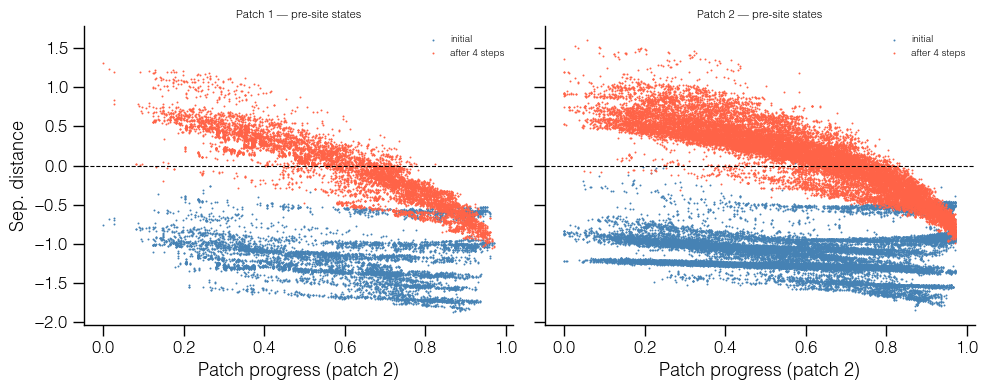

=== Network 3: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net3/trajectories_20260529_160251.pkl ===


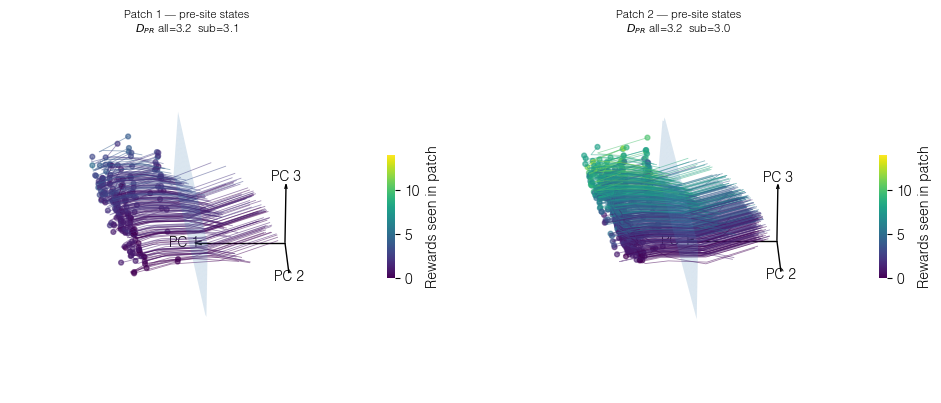

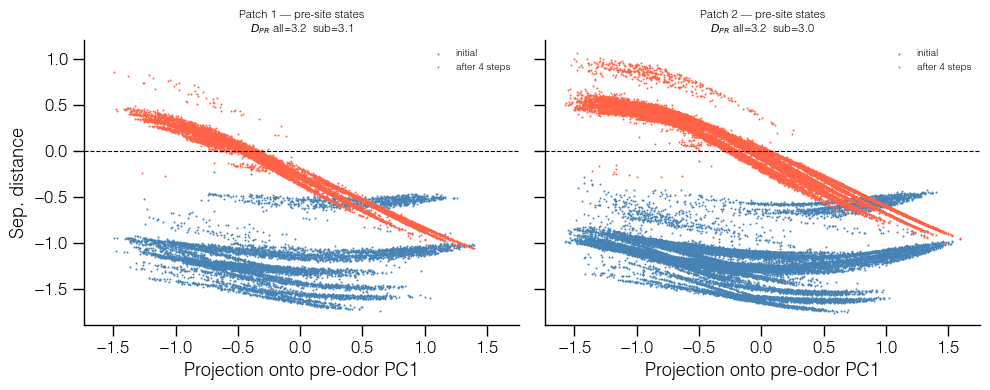

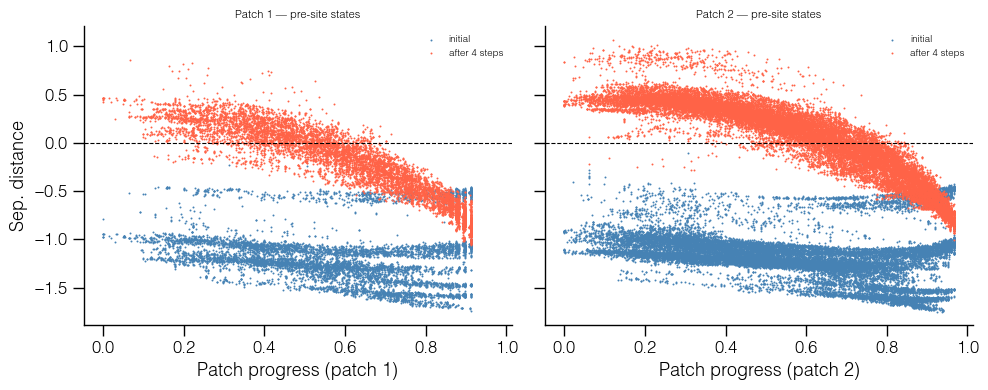

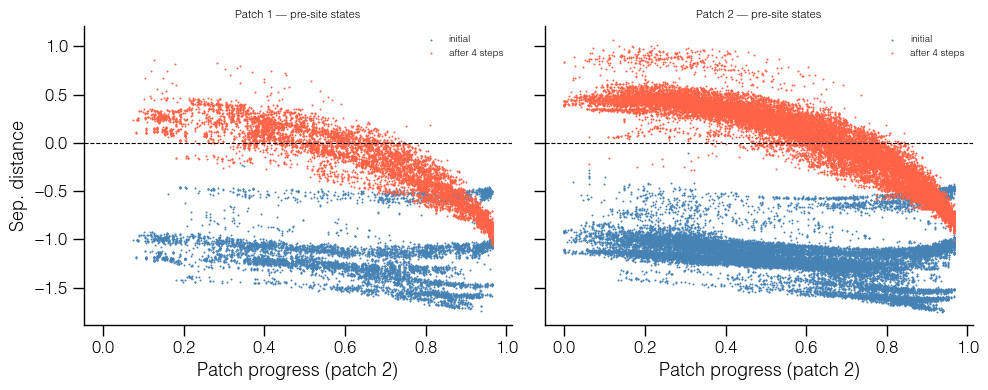

=== Network 4: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net4/trajectories_20260529_163734.pkl ===


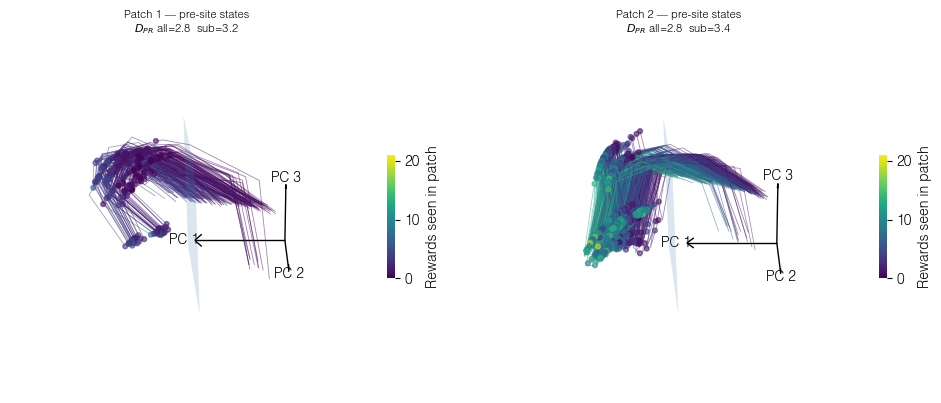

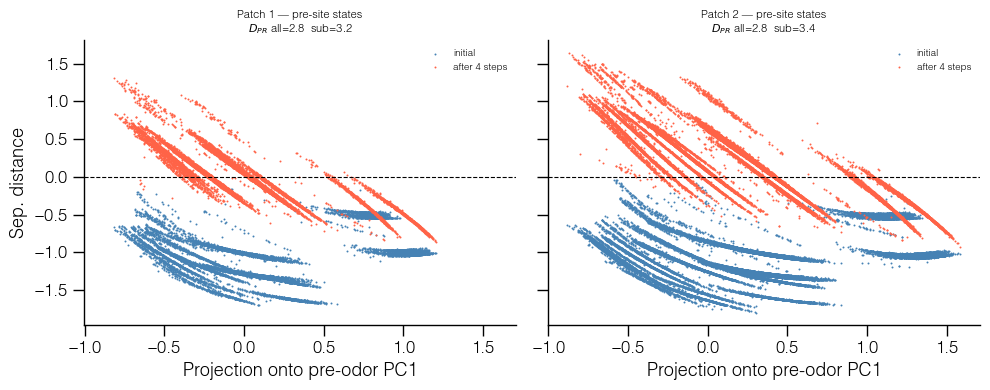

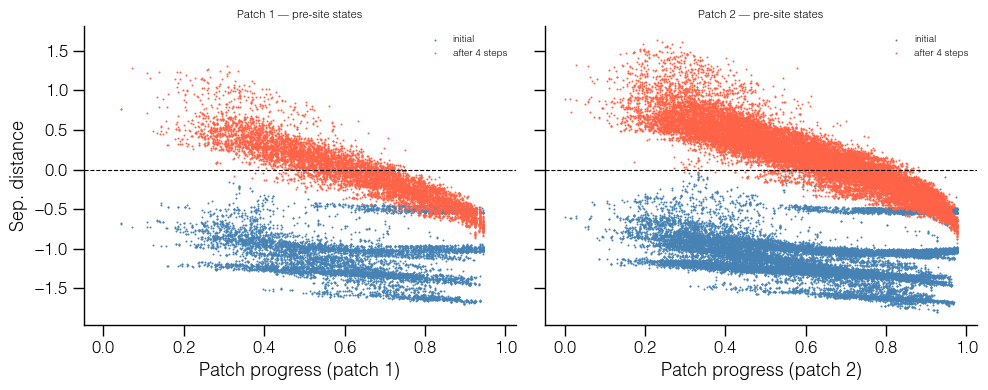

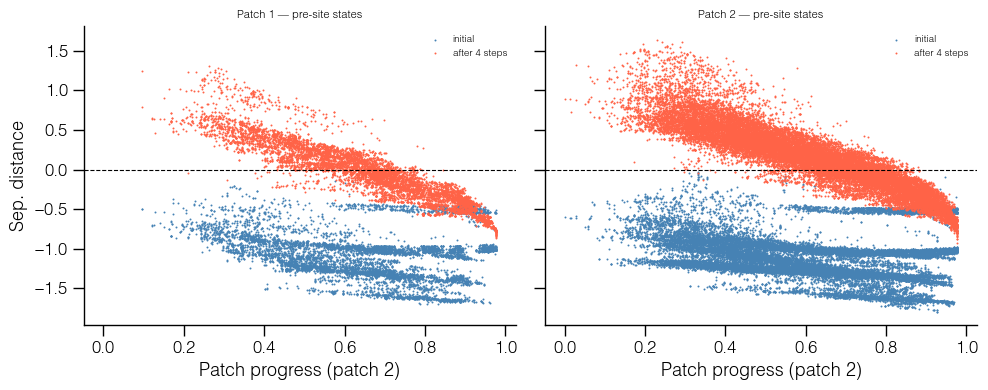

In [ ]:
cov_sep_dist_isi_all = []

for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx}: {dir_path} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])
    pc_activities = pca.transform(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(
        ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    fig1, fig2, fig3, fig4, fig5 = plot_pre_patch_states_with_next_3d(
        traj_data,
        net_params,
        pca,
        color_by='rewards_seen_in_patch',
        cbar_label='Rewards seen in patch',
        azim=90,
        elev=20,
    )
    fig1.savefig(f'../../../figures/pre_patch_states_with_next_net{net_idx}.png',
                 dpi=300, bbox_inches='tight')
    plt.show(fig1); plt.close(fig1)
    fig2.savefig(f'../../../figures/pre_patch_sep_dist_net{net_idx}.png',
                 dpi=300, bbox_inches='tight')
    plt.show(fig2); plt.close(fig2)
    if fig3 is not None:
        fig3.savefig(f'../../../figures/pre_patch_fp_pc1_net{net_idx}.png',
                     dpi=300, bbox_inches='tight')
        plt.show(fig3); plt.close(fig3)
    fig4.savefig(f'../../../figures/pre_patch_progress_net{net_idx}.png',
                 dpi=300, bbox_inches='tight')
    plt.show(fig4); plt.close(fig4)
    fig5.savefig(f'../../../figures/pre_patch_progress_p2_net{net_idx}.png',
                 dpi=300, bbox_inches='tight')
    plt.show(fig5); plt.close(fig5)


### Trajectories of patch progress against time for rewarded odor contexts

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===


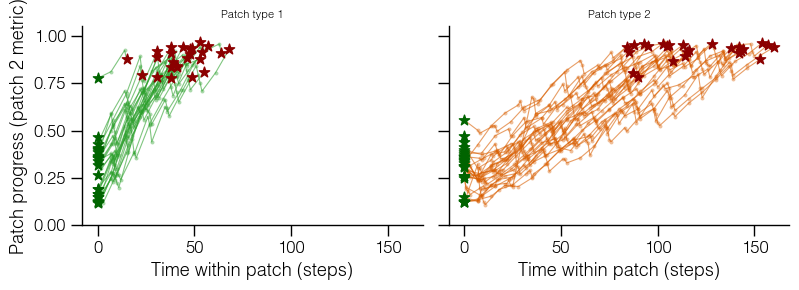

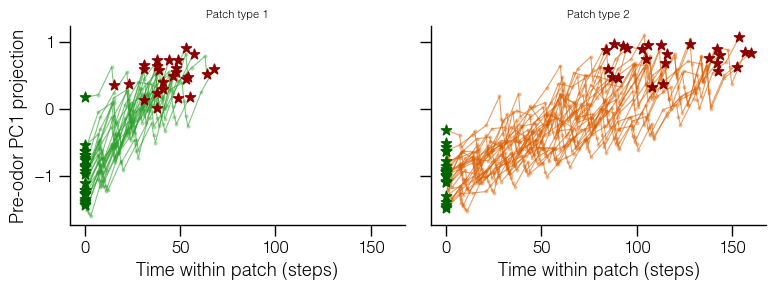

=== Network 1: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl ===


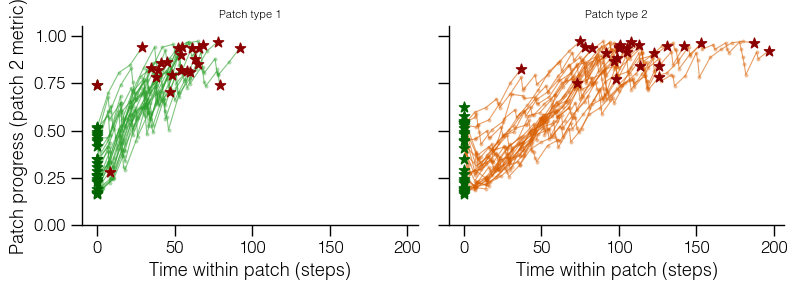

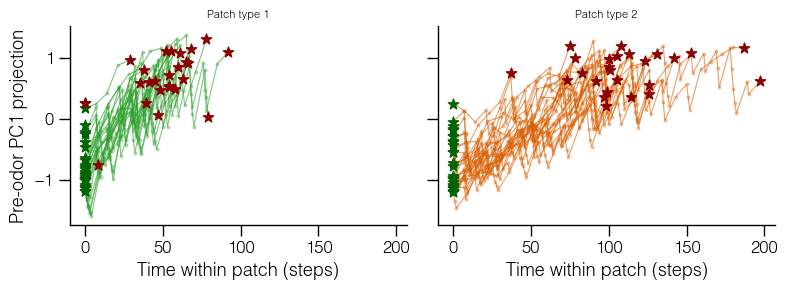

=== Network 2: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl ===


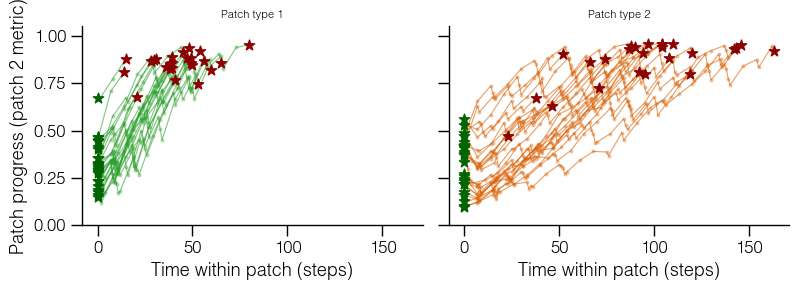

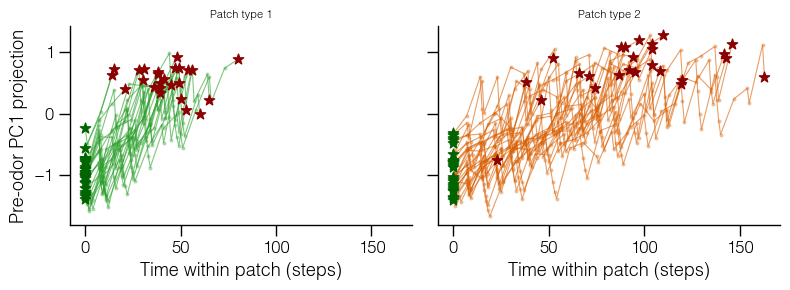

=== Network 3: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net3/trajectories_20260529_160251.pkl ===


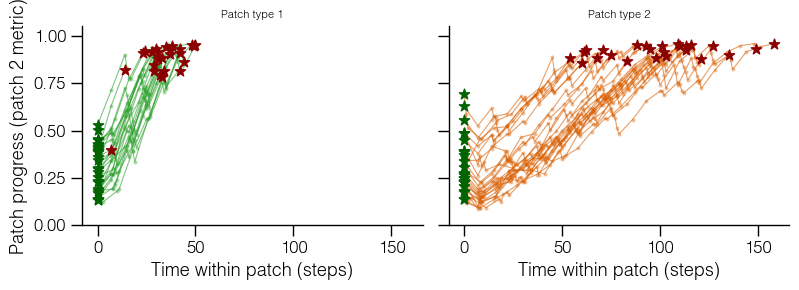

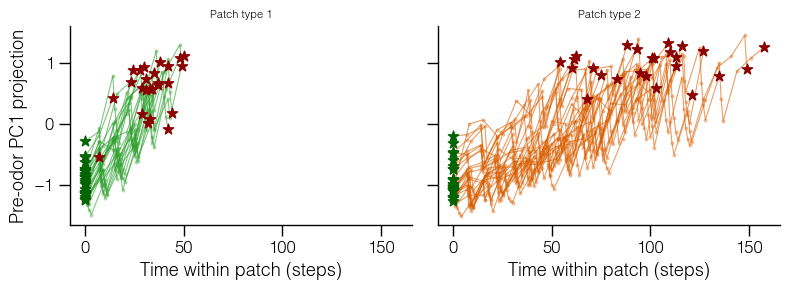

=== Network 4: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net4/trajectories_20260529_163734.pkl ===


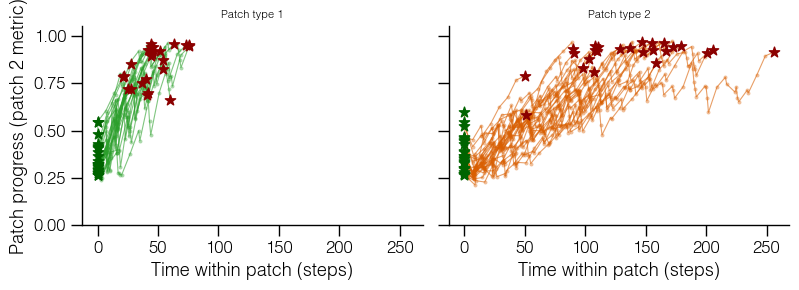

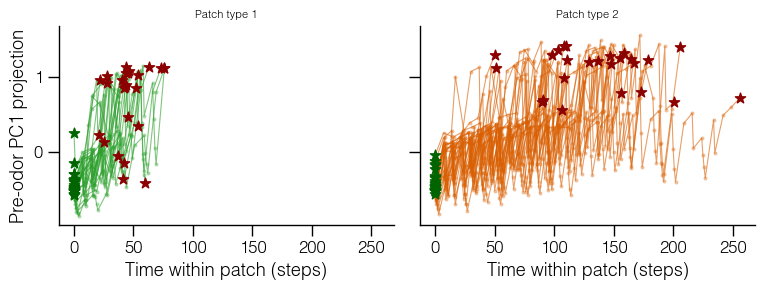

In [ ]:
for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx}: {dir_path} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    fig = plot_patch_progress_trajectories(traj_data, patch_types=(1, 2), n_traj=25)
    if fig is not None:
        fig.savefig(f'../../../figures/patch_progress_trajectories_net{net_idx}.png',
                    dpi=300, bbox_inches='tight')
        plt.show(fig)
        plt.close(fig)

    fig_pc1 = plot_patch_progress_trajectories_pc1(traj_data, patch_types=(1, 2), n_traj=25)
    if fig_pc1 is not None:
        fig_pc1.savefig(f'../../../figures/patch_progress_trajectories_pc1_net{net_idx}.png',
                        dpi=300, bbox_inches='tight')
        plt.show(fig_pc1)
        plt.close(fig_pc1)


In [ ]:
# for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
#     print(f'=== Network {net_idx}: {dir_path} ===')

#     traj_data = {}
#     for env_idx in range(15):
#         traj_data_raw = load_trajectory_data(dir_path)
#         traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
#         for key in traj_data_env.keys():
#             if key in traj_data:
#                 traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
#             else:
#                 traj_data[key] = traj_data_env[key]

#     pca = PCA()
#     pca.fit(traj_data['actor_hidden'])
#     pc_activities = pca.transform(traj_data['actor_hidden'])

#     net_restored = checkpoints.restore_checkpoint(ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
#     net_params = net_restored.params

#     plot_patch_trajectories_3d(traj_data, color_by='reward_site_idx', max_trajectories=5, params=net_params, pca=pca, azim=130, elev=80)
#     plot_patch_activity_heatmaps(traj_data)
#     plot_pre_patch_states_3d(traj_data, pca, color_by='reward_site_idx')
#     plot_pre_patch_states_3d(traj_data, pca, color_by='inter_odor_site_distances')
#     plot_pre_patch_states_3d(traj_data, pca, color_by='rewards_seen_in_patch')
#     plot_pre_patch_states_3d(traj_data, pca, color_by='rewarded_last_odor_site')
#     plot_neuron_reward_correlations(traj_data)

=== Network 1 ===


  20 / 20 fixed points are stable


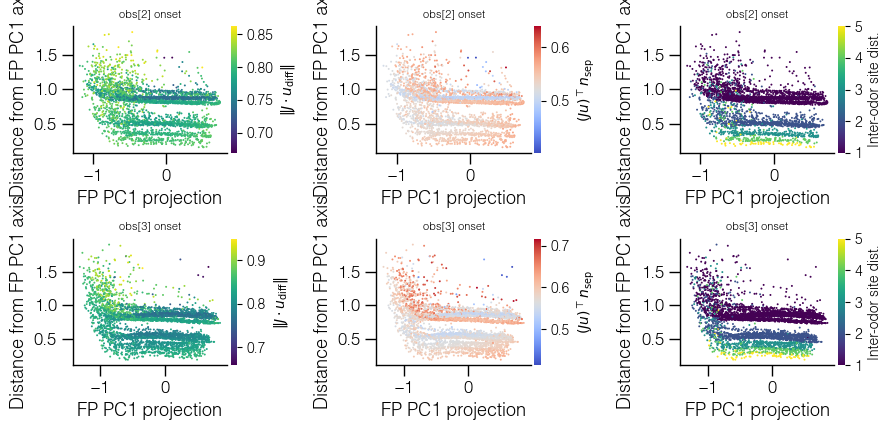

=== Network 2 ===


  13 / 18 fixed points are stable


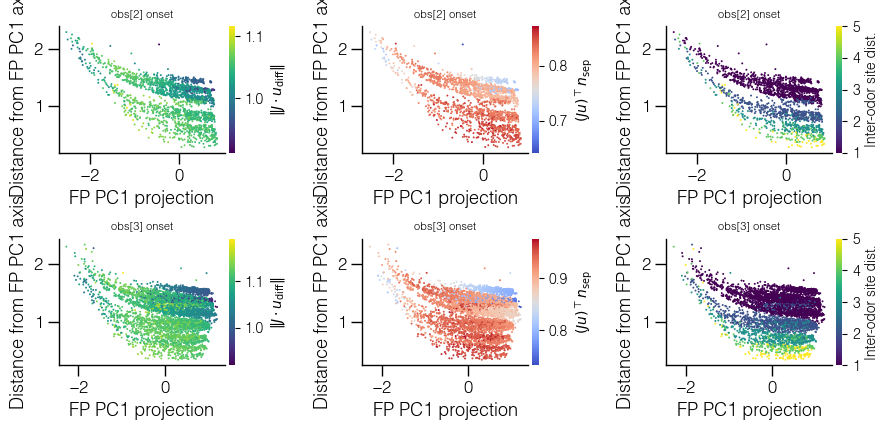

=== Network 4 ===


  13 / 17 fixed points are stable


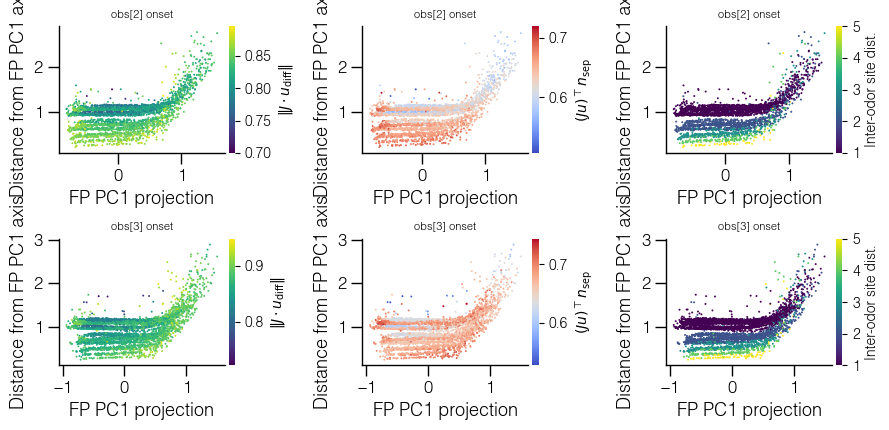

=== Network 5 ===


  13 / 13 fixed points are stable


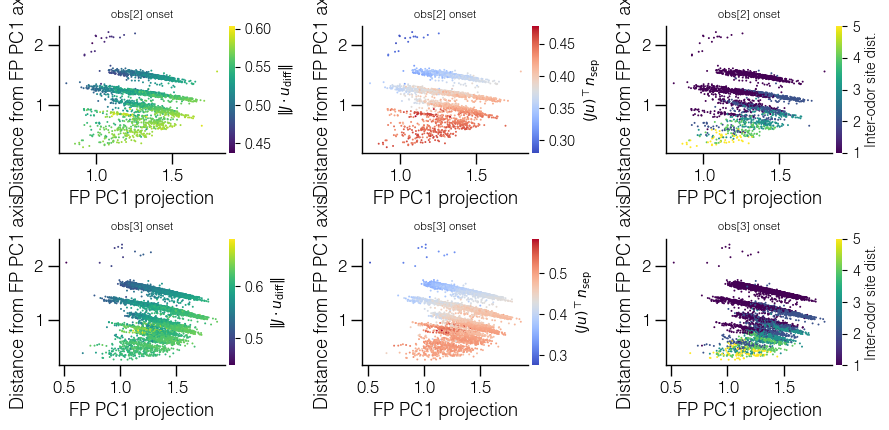

=== Network 6 ===


  24 / 24 fixed points are stable


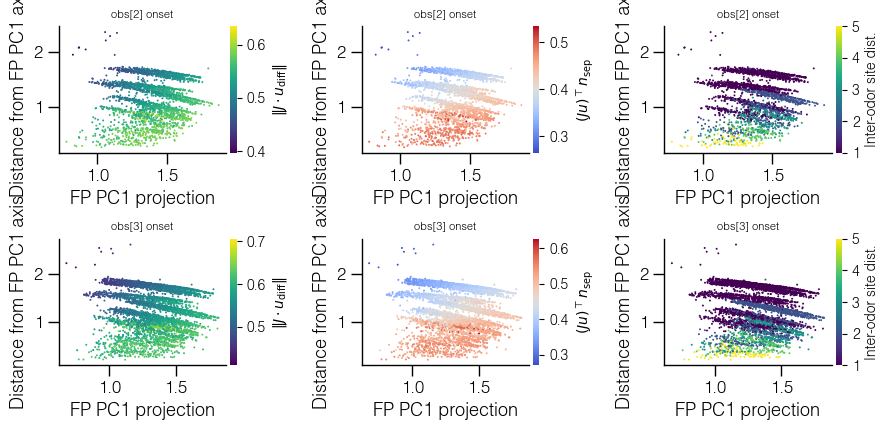

=== Network 7 ===


  18 / 18 fixed points are stable


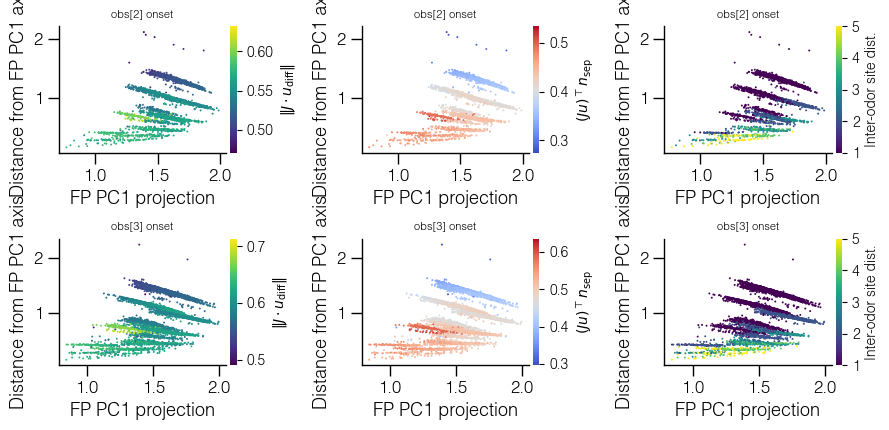

=== Network 8 ===


  1 / 2 fixed points are stable


/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/sklearn/decomposition/_pca.py:586: RuntimeWarning: invalid value encountered in divide
  explained_variance_ = (S**2) / (n_samples - 1)


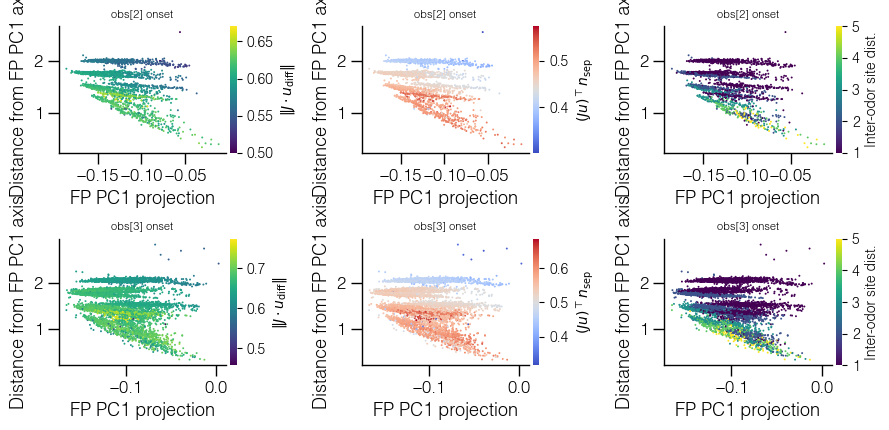

=== Network 9 ===


  19 / 19 fixed points are stable


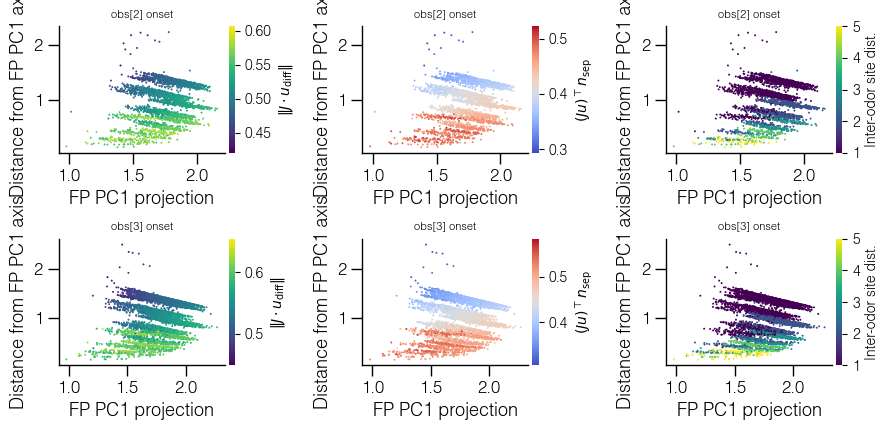

In [ ]:
for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    net_restored = checkpoints.restore_checkpoint(
        ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    plot_pre_patch_states_jac_pc1_space(traj_data, net_params, network)

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===


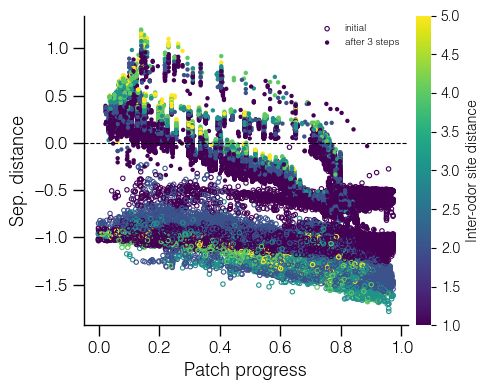

  4 / 4 fixed points stable


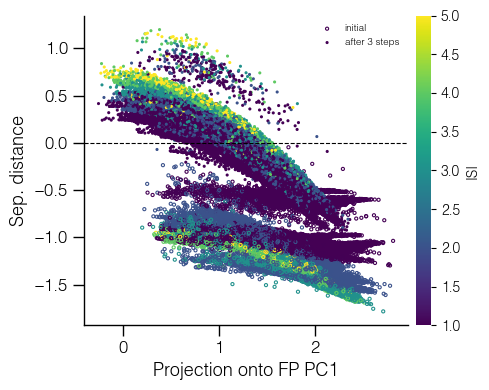

=== Network 1: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net1/trajectories_20260529_145421.pkl ===


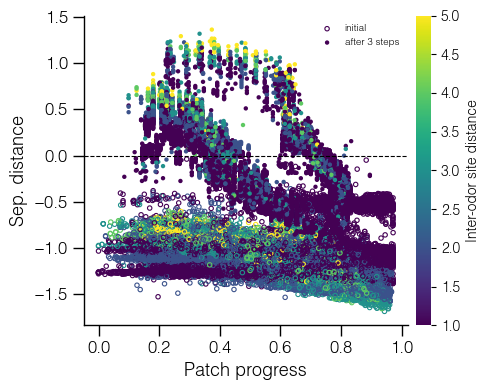

  6 / 6 fixed points stable


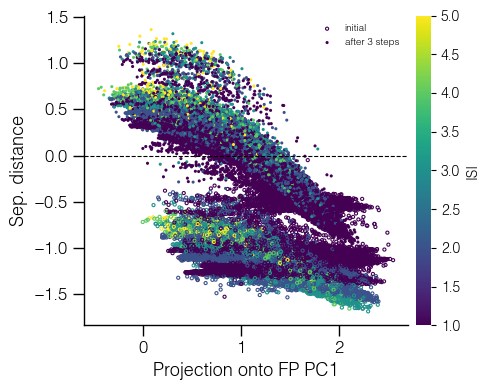

=== Network 2: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net2/trajectories_20260529_152843.pkl ===


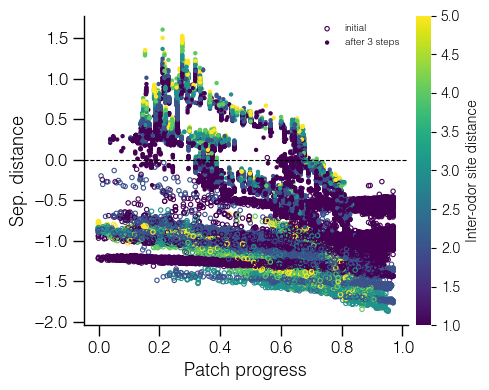

  4 / 4 fixed points stable


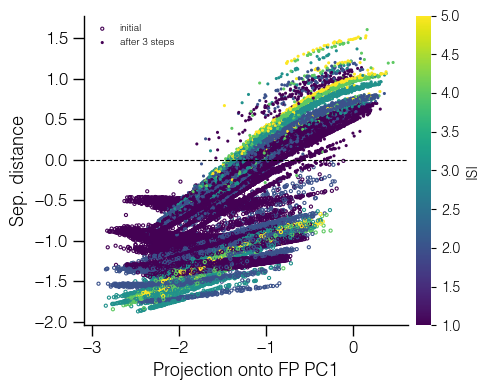

=== Network 3: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net3/trajectories_20260529_160251.pkl ===


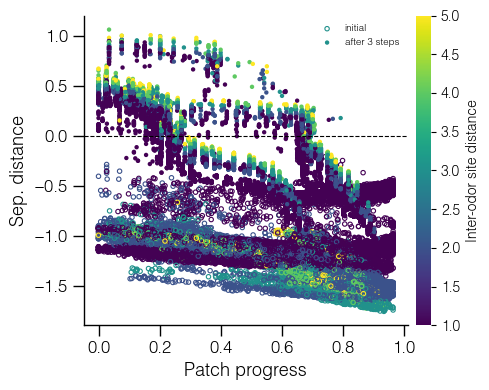

  6 / 6 fixed points stable


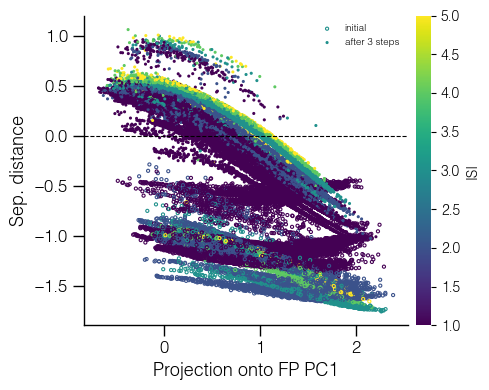

=== Network 4: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net4/trajectories_20260529_163734.pkl ===


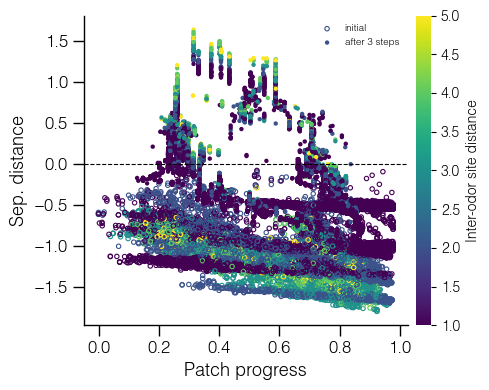

  5 / 5 fixed points stable


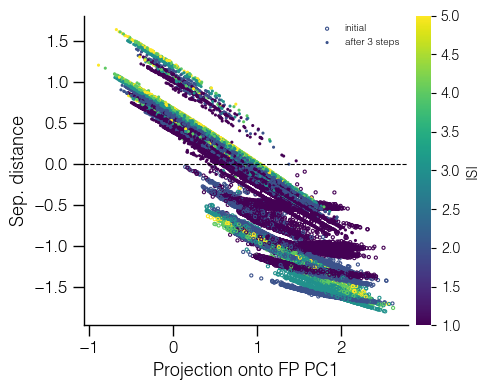

Covariance between sep dist and ISI across networks:


In [ ]:
cov_sep_dist_isi_all = []

for net_idx, dir_path, ckpt_path in zip(passing_indices, PASSING_NETWORKS, PASSING_CHECKPOINTS):
    print(f'=== Network {net_idx}: {dir_path} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])
    pc_activities = pca.transform(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(
        ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    fig_2d = plot_pre_patch_states_with_next_2d(traj_data, net_params)
    fig_2d.savefig(f'../../../figures/pre_patch_sep_dist_2d_net{net_idx}.png',
                   dpi=300, bbox_inches='tight')
    plt.show(fig_2d)
    plt.close(fig_2d)

    fig_fp_pc1 = plot_pre_patch_states_fp_pc1_2d(traj_data, net_params, network)
    fig_fp_pc1.savefig(f'../../../figures/pre_patch_fp_pc1_2d_net{net_idx}.png',
                       dpi=300, bbox_inches='tight')
    plt.show(fig_fp_pc1)
    plt.close(fig_fp_pc1)

    # fig_delta_sep, fig_delta_sep_groups, fig_delta_sep_pc1_lines, fig_delta_sep_delta_lines = plot_sep_dist_change_vs_isi(traj_data, net_params, n_groups=10)
    # fig_delta_sep.savefig(f'../../../figures/sep_dist_change_vs_isi_net{net_idx}.png',
    #                       dpi=300, bbox_inches='tight')
    # plt.show(fig_delta_sep)
    # plt.close(fig_delta_sep)
    # fig_delta_sep_groups.savefig(f'../../../figures/sep_dist_change_vs_isi_groups_net{net_idx}.png',
    #                              dpi=300, bbox_inches='tight')
    # plt.show(fig_delta_sep_groups)
    # plt.close(fig_delta_sep_groups)
    # fig_delta_sep_pc1_lines.savefig(f'../../../figures/sep_dist_final_vs_isi_pc1_lines_net{net_idx}.png',
    #                                 dpi=300, bbox_inches='tight')
    # plt.show(fig_delta_sep_pc1_lines)
    # plt.close(fig_delta_sep_pc1_lines)
    # fig_delta_sep_delta_lines.savefig(f'../../../figures/sep_dist_delta_vs_isi_pc1_lines_net{net_idx}.png',
    #                                   dpi=300, bbox_inches='tight')
    # plt.show(fig_delta_sep_delta_lines)
    # plt.close(fig_delta_sep_delta_lines)


print('Covariance between sep dist and ISI across networks:')
for idx, cov in enumerate(cov_sep_dist_isi_all):
    print(f'Net {idx}: {cov}')

=== Network 0 ===


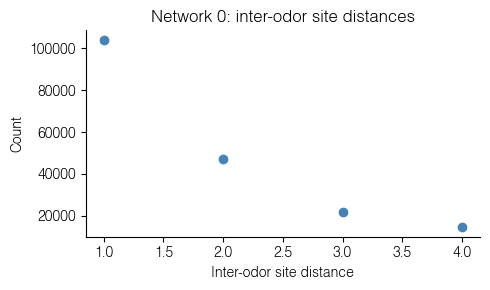

=== Network 1 ===


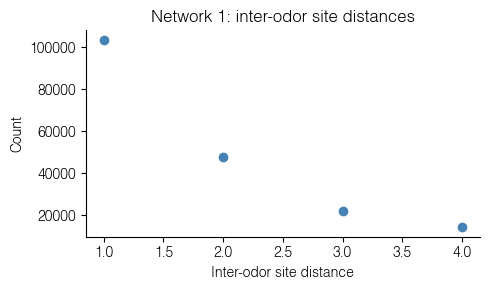

=== Network 2 ===


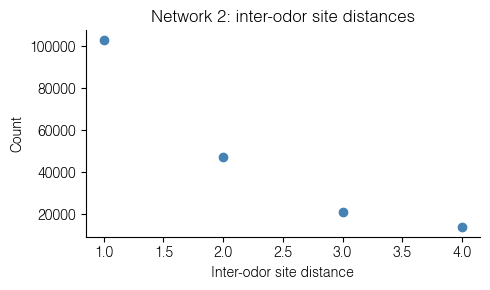

=== Network 3 ===


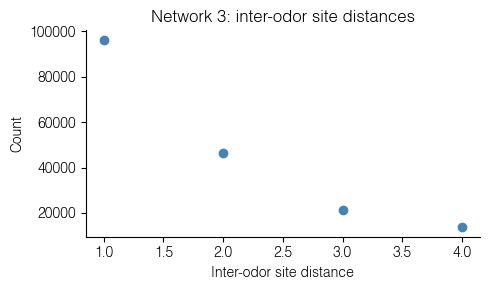

=== Network 4 ===


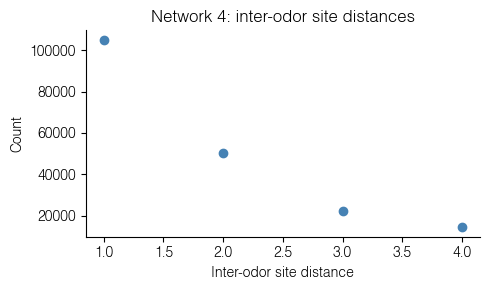

In [ ]:
for net_idx, dir_path in zip(passing_indices, PASSING_NETWORKS):
    print(f'=== Network {net_idx} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    inter_odor_site_distances = traj_data['inter_odor_site_distances']
    inter_odor_site_distances = inter_odor_site_distances[~np.isnan(inter_odor_site_distances)]
    inter_odor_site_distances = inter_odor_site_distances.astype(int)

    fig, ax = plt.subplots(figsize=(5, 3))
    counts, bins = np.histogram(inter_odor_site_distances, bins=np.unique(inter_odor_site_distances))
    ax.scatter(bins[:-1], counts, color='steelblue')
    ax.set_xlabel('Inter-odor site distance')
    ax.set_ylabel('Count')
    ax.set_title(f'Network {net_idx}: inter-odor site distances')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    plt.tight_layout()
    plt.show()


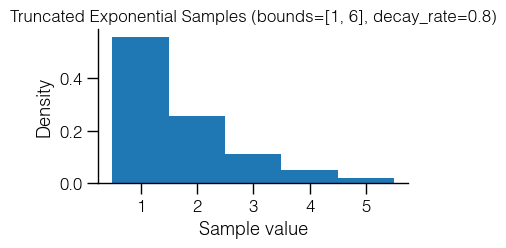

In [ ]:
from environments.treadmill_env_jax import sample_truncated_exp

n_samples = 10000
bounds = jnp.array([1.0, 6.0])
decay_rate = 0.8

rng_key = jax.random.PRNGKey(0)
sample_keys = jax.random.split(rng_key, n_samples)
samples = jax.vmap(lambda k: sample_truncated_exp(k, bounds, decay_rate))(sample_keys)

plt.figure(figsize=(4, 2))
plt.hist(samples.astype(int), bins=np.arange(1, 7) - 0.5, density=True)
plt.xlabel('Sample value')
plt.ylabel('Density')
plt.title('Truncated Exponential Samples (bounds=[1, 6], decay_rate=0.8)')
format_plot(plt.gca())
plt.show()

In [ ]:
OBS3_THRESHOLD = 0.5
MIN_GROUP_LEN  = 2   # skip groups too short to centre

group_pr_results = []
N_STEPS = 20000

for net_idx, dir_path in enumerate(FIXED_EXP_GRU_REWARD_DECAY_NETWORKS):
    print(f'Network {net_idx}...')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    obs_all    = traj_data['observations'].reshape(15, N_STEPS, -1)
    hidden_all = traj_data['actor_hidden'].reshape(15, N_STEPS, -1)

    for trial_idx in range(15):
        obs    = obs_all[trial_idx]    # (T, 4)
        hidden = hidden_all[trial_idx] # (T, H)

        # Locate patches via obs[:,0]
        in_patch = obs[:, 0] > OBS3_THRESHOLD
        padded   = np.concatenate([[False], in_patch, [False]])
        diff     = np.diff(padded.astype(int))
        p_starts = np.where(diff ==  1)[0]
        p_stops  = np.where(diff == -1)[0]

        for p_start, p_stop in zip(p_starts, p_stops):
            patch_obs    = obs[p_start:p_stop, :]      # (T_patch, 4)
            patch_hidden = hidden[p_start:p_stop, :]   # (T_patch, H)

            # Only include patches where obs[3] reaches ~1
            if not np.any(patch_obs[:, 3] > OBS3_THRESHOLD):
                continue

            # Low→high transitions of obs[3]
            obs3      = patch_obs[:, 3]
            rises     = np.where((obs3[:-1] <= OBS3_THRESHOLD) &
                                 (obs3[1:]  >  OBS3_THRESHOLD))[0] + 1

            if len(rises) == 0:
                continue  # obs[3] never rises — nothing to group

            # Groups: [rises[k], rises[k+1]), last group ends at T_patch
            group_edges = np.concatenate([rises, [len(obs3)]])
            groups = [(int(group_edges[k]), int(group_edges[k + 1]))
                      for k in range(len(group_edges) - 1)]

            # Centre each group and collect
            centred_groups = []
            for g_start, g_end in groups:
                H = patch_hidden[g_start:g_end]
                print(H.shape)
                if len(H) < MIN_GROUP_LEN:
                    continue
                print(H.shape)
                centred_groups.append(H - H.mean(axis=0))

            if len(centred_groups) < 2:
                continue  # need at least 2 groups for a meaningful comparison

            H_dim = centred_groups[0].shape[1]

            H_combined = np.vstack(centred_groups)
            pr = participation_ratio(H_combined)

            # Sequential control: unit t fires at step t within each group
            seq_groups = []
            for H_g in centred_groups:
                T_k = len(H_g)
                assert T_k <= H_dim, (
                    f"Group length {T_k} exceeds hidden dim {H_dim}")
                H_seq = np.zeros((T_k, H_dim))
                H_seq[np.arange(T_k), np.arange(T_k)] = 1.0
                seq_groups.append(H_seq - H_seq.mean(axis=0))

            pr_sequential = participation_ratio(np.vstack(seq_groups))

            group_pr_results.append({
                'net_idx':        net_idx,
                'trial_idx':      trial_idx,
                'n_groups':       len(centred_groups),
                'D_PR':           pr,
                'D_PR_sequential': pr_sequential,
            })

group_pr_df = pd.DataFrame(group_pr_results)
print(f'Collected {len(group_pr_df)} patches across all networks')
group_pr_df.head()

Network 0...
Loading trajectory data from: ../../results/fixed_exp_gru_reward_decay_net0/trajectories_20260409_181731.pkl
Loaded 30 episodes
Episode length: 20000
Observation shape: (20000, 4)
Action shape: (20000,)
Loading trajectory data from: ../../results/fixed_exp_gru_reward_decay_net0/trajectories_20260409_181731.pkl
Loaded 30 episodes
Episode length: 20000
Observation shape: (20000, 4)
Action shape: (20000,)
Loading trajectory data from: ../../results/fixed_exp_gru_reward_decay_net0/trajectories_20260409_181731.pkl
Loaded 30 episodes
Episode length: 20000
Observation shape: (20000, 4)
Action shape: (20000,)
Loading trajectory data from: ../../results/fixed_exp_gru_reward_decay_net0/trajectories_20260409_181731.pkl
Loaded 30 episodes
Episode length: 20000
Observation shape: (20000, 4)
Action shape: (20000,)
Loading trajectory data from: ../../results/fixed_exp_gru_reward_decay_net0/trajectories_20260409_181731.pkl
Loaded 30 episodes
Episode length: 20000
Observation shape: (20000

,net_idx,trial_idx,n_groups,D_PR,D_PR_sequential
0,0,0,22,2.338953,7.345279
1,0,0,23,2.300105,7.079509
2,0,0,20,2.614824,7.967423
3,0,0,21,2.296255,7.224583
4,0,0,22,2.302175,6.767591


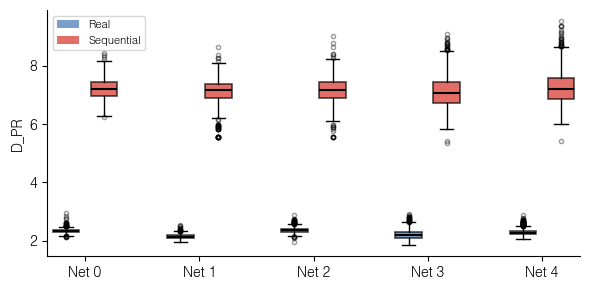

In [ ]:
net_indices = sorted(group_pr_df['net_idx'].unique())
n_nets = len(net_indices)

fig, ax = plt.subplots(figsize=(4 + n_nets * 0.4, 3))

positions_real = []
positions_seq  = []
data_real      = []
data_seq       = []

for k, net_idx in enumerate(net_indices):
    net = group_pr_df[group_pr_df['net_idx'] == net_idx]
    positions_real.append(k * 3 + 1)
    positions_seq.append(k * 3 + 2)
    data_real.append(net['D_PR'].values)
    data_seq.append(net['D_PR_sequential'].values)

bp_real = ax.boxplot(
    data_real, positions=positions_real, widths=0.7,
    patch_artist=True,
    medianprops={'color': 'black', 'linewidth': 1.5},
    boxprops={'linewidth': 1.2, 'facecolor': '#4575b4', 'alpha': 0.7},
    whiskerprops={'linewidth': 1.0},
    capprops={'linewidth': 1.0},
    flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.4},
)
bp_seq = ax.boxplot(
    data_seq, positions=positions_seq, widths=0.7,
    patch_artist=True,
    medianprops={'color': 'black', 'linewidth': 1.5},
    boxprops={'linewidth': 1.2, 'facecolor': '#d73027', 'alpha': 0.7},
    whiskerprops={'linewidth': 1.0},
    capprops={'linewidth': 1.0},
    flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.4},
)

tick_positions = [k * 3 + 1.5 for k in range(n_nets)]
ax.set_xticks(tick_positions)
ax.set_xticklabels([f'Net {i}' for i in net_indices])
ax.set_ylabel('D_PR')

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='#4575b4', alpha=0.7, label='Real'),
    Patch(facecolor='#d73027', alpha=0.7, label='Sequential'),
], fontsize=8)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

In [ ]:
for net_idx, (dir_path, ckpt_path) in enumerate(zip(
        FIXED_EXP_GRU_INITIAL_PROB_OFFSET_NETWORKS, FIXED_EXP_GRU_INITIAL_PROB_OFFSET_CHECKPOINTS)):
    network_name = Path(dir_path).parent.name
    print(f'=== Network {net_idx}: {network_name} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    net_restored = checkpoints.restore_checkpoint(
        ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])

    save_fixed_points_for_unique_inputs(
        traj_data=traj_data,
        params=net_params,
        network=network,
        save_dir='../../../saved_states',
        network_name=network_name,
        n_fp_attempts=1000,
        fp_tol=5e-1,
        min_occurrences=5,
        includes_actions_and_rewards=True,
        pca=pca,
        patch_idx=2,
    )


=== Network 0: fixed_exp_gru_initial_prob_offset_v4_net0 ===


12 unique input vectors; 11 have >= 5 occurrences
[1/12] 0_0_0_0_0_1_0  (count=23884)
  -> 568 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net0/fp_0_0_0_0_0_1_0.pkl
[2/12] 0_0_0_0_1_0_0  (count=366)
  -> 625 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net0/fp_0_0_0_0_1_0_0.pkl
[3/12] 1_0_0_0_0_1_0  (count=64386)
  -> 536 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net0/fp_1_0_0_0_0_1_0.pkl
[4/12] 1_0_0_0_1_0_0  (count=52)
  -> 671 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net0/fp_1_0_0_0_1_0_0.pkl
[5/12] 1_0_0_1_0_1_0  (count=77918)
  -> 720 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net0/fp_1_0_0_1_0_1_0.pkl
[6/12] 1_0_0_1_1_0_0  (count=58006)
  -> 735 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net0/fp_1_0_0_1

12 unique input vectors; 11 have >= 5 occurrences
[1/12] 0_0_0_0_0_1_0  (count=23412)
  -> 626 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net1/fp_0_0_0_0_0_1_0.pkl
[2/12] 0_0_0_0_1_0_0  (count=566)
  -> 723 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net1/fp_0_0_0_0_1_0_0.pkl
[3/12] 1_0_0_0_0_1_0  (count=64553)
  -> 641 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net1/fp_1_0_0_0_0_1_0.pkl
[4/12] 1_0_0_0_1_0_0  (count=67)
  -> 743 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net1/fp_1_0_0_0_1_0_0.pkl
[5/12] 1_0_0_1_0_1_0  (count=72466)
  -> 763 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net1/fp_1_0_0_1_0_1_0.pkl
[6/12] 1_0_0_1_1_0_0  (count=53781)
  -> 788 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net1/fp_1_0_0_1

12 unique input vectors; 11 have >= 5 occurrences
[1/12] 0_0_0_0_0_1_0  (count=24513)
  -> 577 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net2/fp_0_0_0_0_0_1_0.pkl
[2/12] 0_0_0_0_1_0_0  (count=548)
  -> 654 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net2/fp_0_0_0_0_1_0_0.pkl
[3/12] 1_0_0_0_0_1_0  (count=64130)
  -> 582 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net2/fp_1_0_0_0_0_1_0.pkl
[4/12] 1_0_0_0_1_0_0  (count=72)
  -> 687 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net2/fp_1_0_0_0_1_0_0.pkl
[5/12] 1_0_0_1_0_1_0  (count=74706)
  -> 687 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net2/fp_1_0_0_1_0_1_0.pkl
[6/12] 1_0_0_1_1_0_0  (count=54879)
  -> 679 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net2/fp_1_0_0_1

12 unique input vectors; 11 have >= 5 occurrences
[1/12] 0_0_0_0_0_1_0  (count=28959)
  -> 549 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net3/fp_0_0_0_0_0_1_0.pkl
[2/12] 0_0_0_0_1_0_0  (count=512)
  -> 676 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net3/fp_0_0_0_0_1_0_0.pkl
[3/12] 1_0_0_0_0_1_0  (count=64154)
  -> 546 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net3/fp_1_0_0_0_0_1_0.pkl
[4/12] 1_0_0_0_1_0_0  (count=37)
  -> 678 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net3/fp_1_0_0_0_1_0_0.pkl
[5/12] 1_0_0_1_0_1_0  (count=74997)
  -> 696 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net3/fp_1_0_0_1_0_1_0.pkl
[6/12] 1_0_0_1_1_0_0  (count=54475)
  -> 733 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net3/fp_1_0_0_1

12 unique input vectors; 11 have >= 5 occurrences
[1/12] 0_0_0_0_0_1_0  (count=21285)
  -> 429 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net4/fp_0_0_0_0_0_1_0.pkl
[2/12] 0_0_0_0_1_0_0  (count=624)
  -> 570 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net4/fp_0_0_0_0_1_0_0.pkl
[3/12] 1_0_0_0_0_1_0  (count=64787)
  -> 373 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net4/fp_1_0_0_0_0_1_0.pkl
[4/12] 1_0_0_0_1_0_0  (count=143)
  -> 514 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net4/fp_1_0_0_0_1_0_0.pkl
[5/12] 1_0_0_1_0_1_0  (count=77677)
  -> 550 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net4/fp_1_0_0_1_0_1_0.pkl
[6/12] 1_0_0_1_1_0_0  (count=58698)
  -> 611 unique fixed point(s) saved to ../../../saved_states/fixed_exp_gru_initial_prob_offset_v4_net4/fp_1_0_0_

### Generate animations of patch trajectories

In [ ]:
for net_idx, (dir_path, ckpt_path) in enumerate(zip(FIXED_EXP_GRU_INITIAL_PROB_OFFSET_NETWORKS, FIXED_EXP_GRU_INITIAL_PROB_OFFSET_CHECKPOINTS)):
    if net_idx != 0:
        continue
    print(f'=== Network {net_idx}: {dir_path} ===')

    traj_data = {}
    for env_idx in range(15):
        traj_data_raw = load_trajectory_data(dir_path)
        traj_data_env = parse_behavioral_data(traj_data_raw[env_idx])
        for key in traj_data_env.keys():
            if key in traj_data:
                traj_data[key] = np.concatenate([traj_data[key], traj_data_env[key]], axis=0)
            else:
                traj_data[key] = traj_data_env[key]

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])
    pc_activities = pca.transform(traj_data['actor_hidden'])

    net_restored = checkpoints.restore_checkpoint(ckpt_dir=Path(ckpt_path).resolve(), target=train_state)
    net_params = net_restored.params

    animate_patch_trajectories_3d(
        traj_data,
        max_trajectories=1,
        params=net_params,
        pca=pca,
        rx1=20, ry1=0, rz1=80,
        rx2=110, ry2=0, rz2=70,
        steps_per_frame=0.5,
        rotation=True,
        save_path=Path(dir_path).parent.resolve() / f'animated_patch_trajectories_{env_idx}.mp4',
        dpi=500,
    )

=== Network 0: ../../../results/fixed_exp_gru_initial_prob_offset_v4_net0/trajectories_20260529_141949.pkl ===


ffmpeg not found — saving as GIF instead: /home/david.bell/work/favorably_connected_2/results/fixed_exp_gru_initial_prob_offset_v4_net0/animated_patch_trajectories_14.gif
Saved to /home/david.bell/work/favorably_connected_2/results/fixed_exp_gru_initial_prob_offset_v4_net0/animated_patch_trajectories_14.gif


### Fixed-point dynamics across training (structure_evo_exp_gru_initial_prob_offset)

Found 80 traj/checkpoint pairs
Selected 12 pairs at sessions: [0, 25, 50, 75, 100, 125, 150, 175, 200, 500, 900, 1900]
Session 0: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000000.pkl


Trial 0, patch 3  (global steps 741–778, length 38)  → 38 segments with ≥2 steps


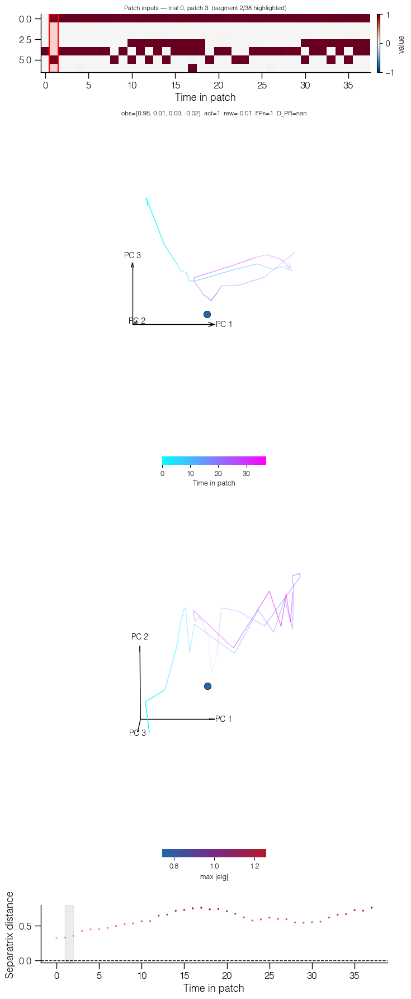

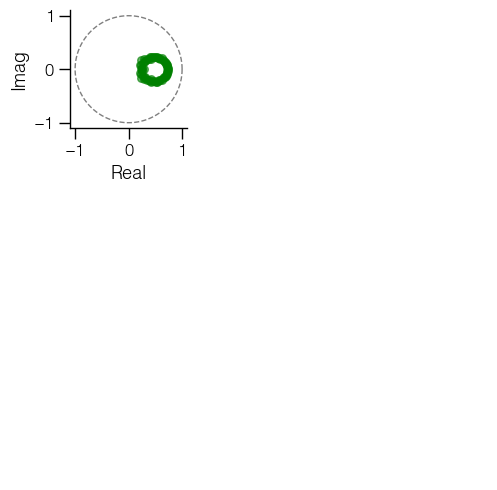

<Figure size 640x480 with 0 Axes>

Session 25: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000025.pkl


Trial 0, patch 3  (global steps 173–342, length 170)  → 170 segments with ≥2 steps


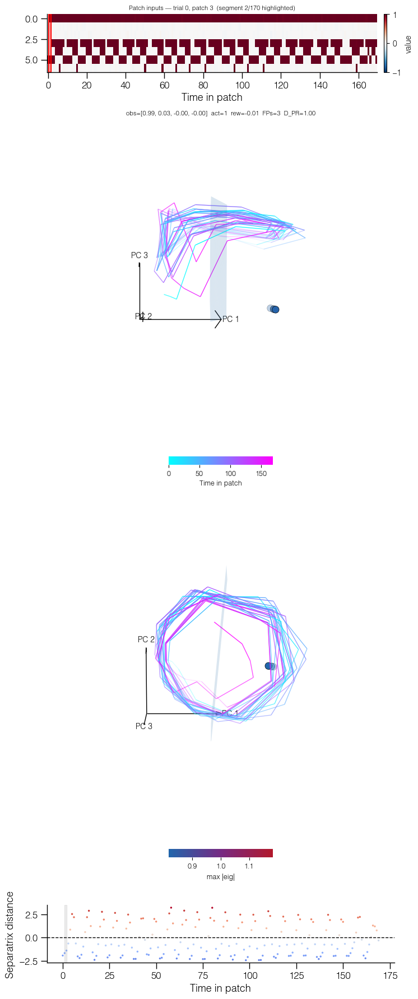

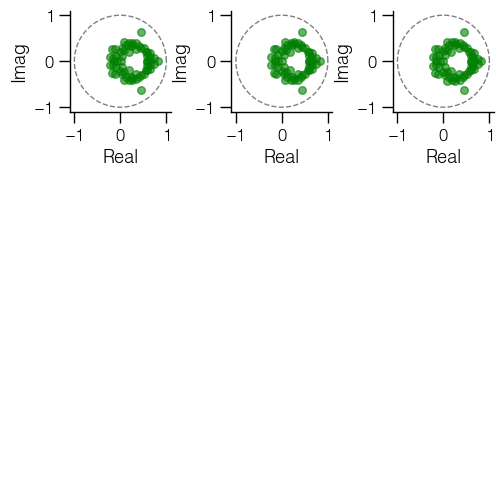

<Figure size 640x480 with 0 Axes>

Session 50: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000050.pkl


Trial 0, patch 3  (global steps 718–886, length 169)  → 169 segments with ≥2 steps


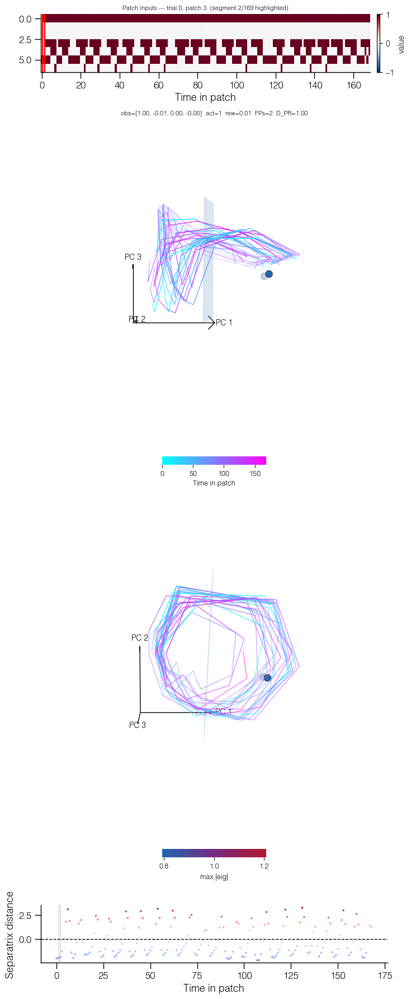

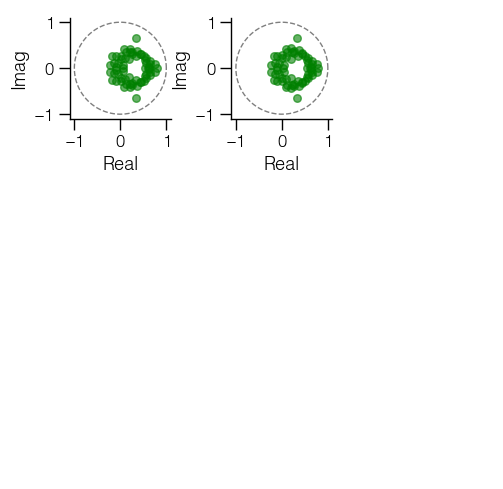

<Figure size 640x480 with 0 Axes>

Session 75: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000075.pkl


Trial 0, patch 3  (global steps 801–870, length 70)  → 70 segments with ≥2 steps


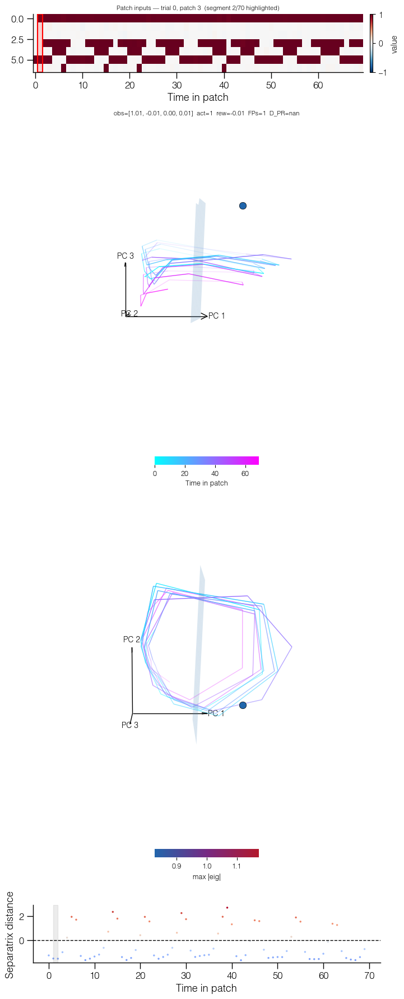

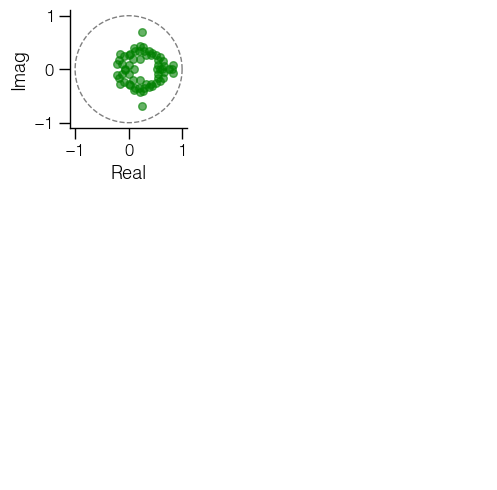

<Figure size 640x480 with 0 Axes>

Session 100: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000100.pkl


Trial 0, patch 3  (global steps 887–996, length 110)  → 110 segments with ≥2 steps


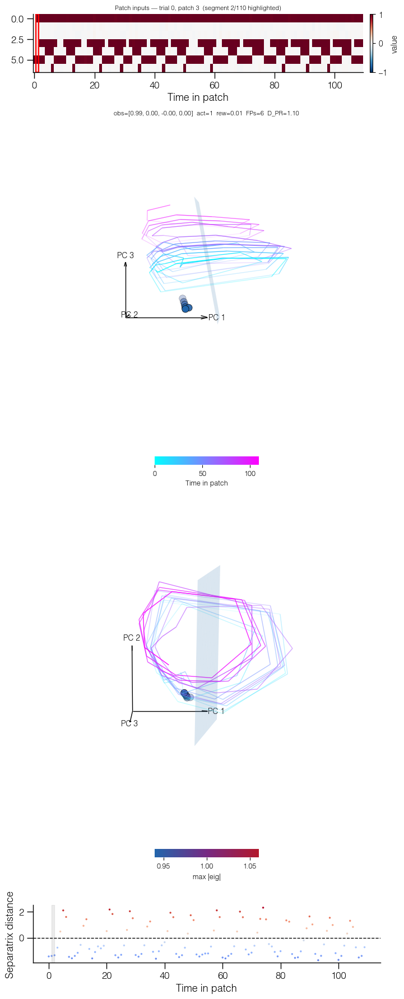

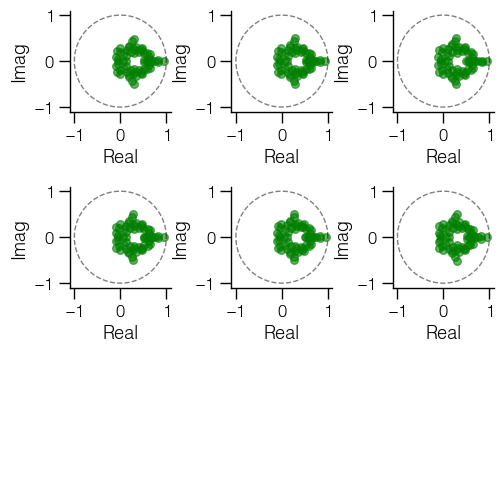

<Figure size 640x480 with 0 Axes>

Session 125: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000125.pkl


Trial 0, patch 3  (global steps 587–768, length 182)  → 182 segments with ≥2 steps


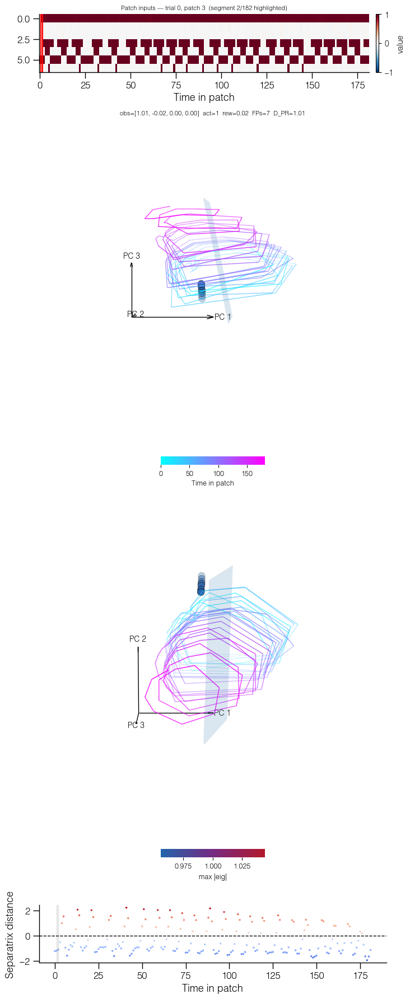

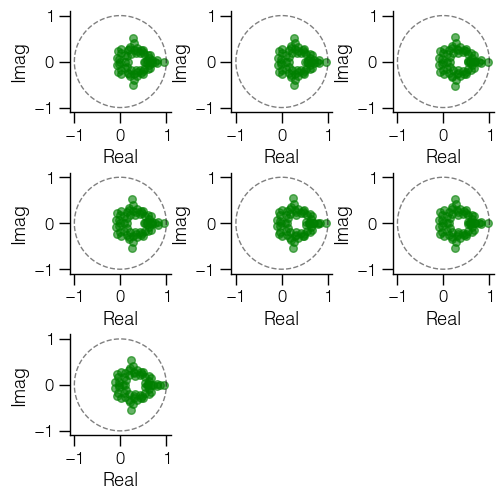

<Figure size 640x480 with 0 Axes>

Session 150: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000150.pkl


Trial 0, patch 3  (global steps 489–599, length 111)  → 111 segments with ≥2 steps


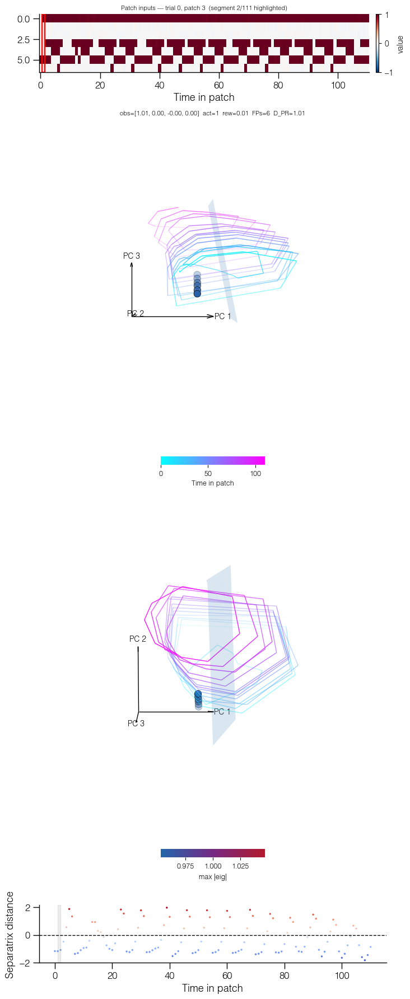

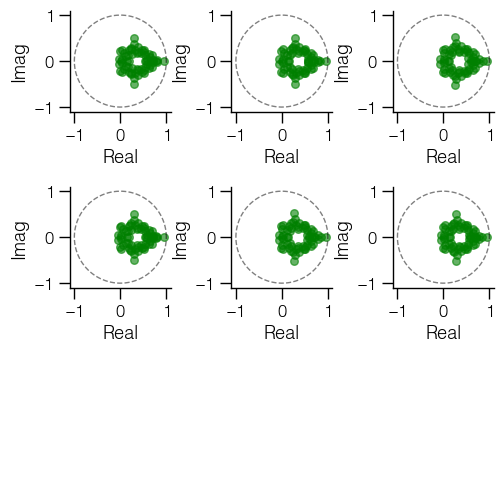

<Figure size 640x480 with 0 Axes>

Session 175: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000175.pkl


Trial 0, patch 3  (global steps 738–866, length 129)  → 129 segments with ≥2 steps


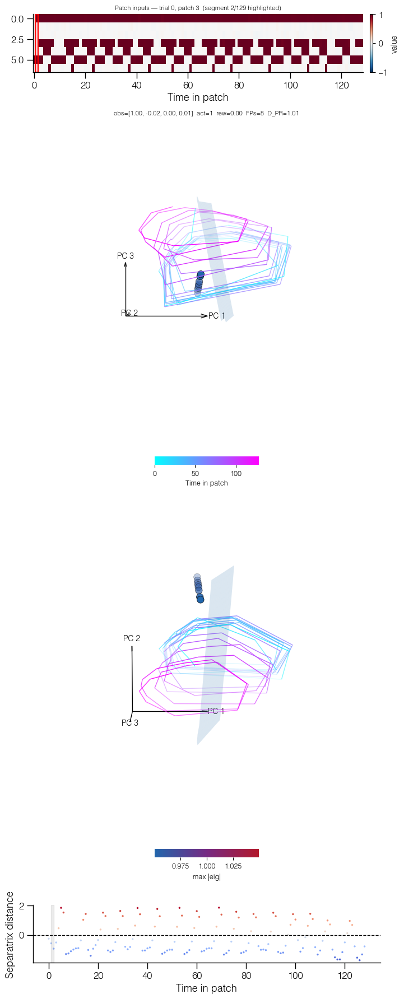

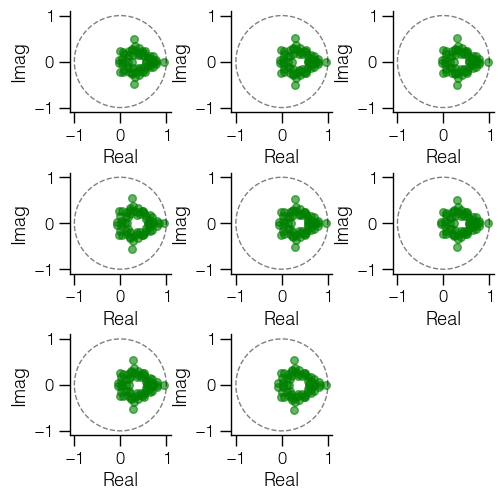

<Figure size 640x480 with 0 Axes>

Session 200: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000200.pkl


Trial 0, patch 3  (global steps 932–1030, length 99)  → 99 segments with ≥2 steps


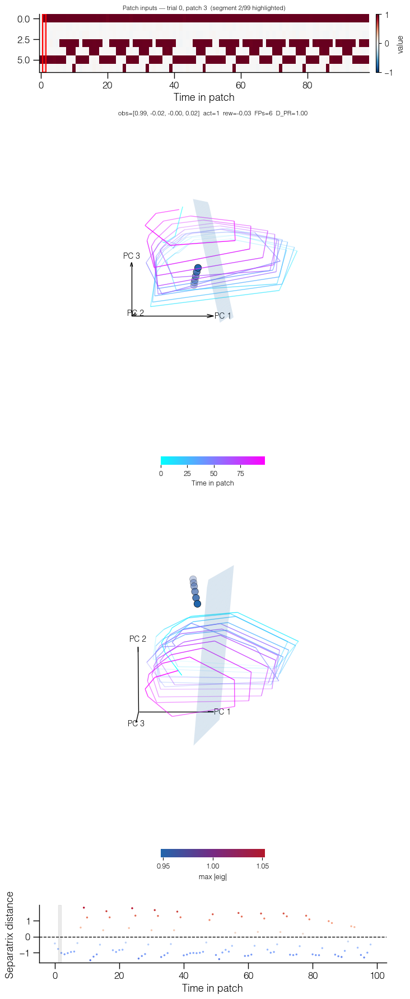

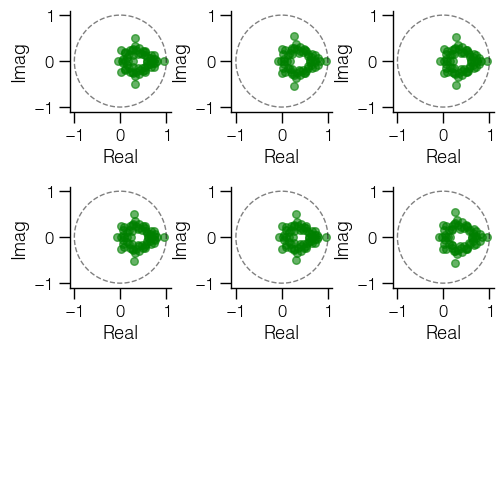

<Figure size 640x480 with 0 Axes>

Session 500: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000500.pkl


Trial 0, patch 3  (global steps 792–961, length 170)  → 170 segments with ≥2 steps


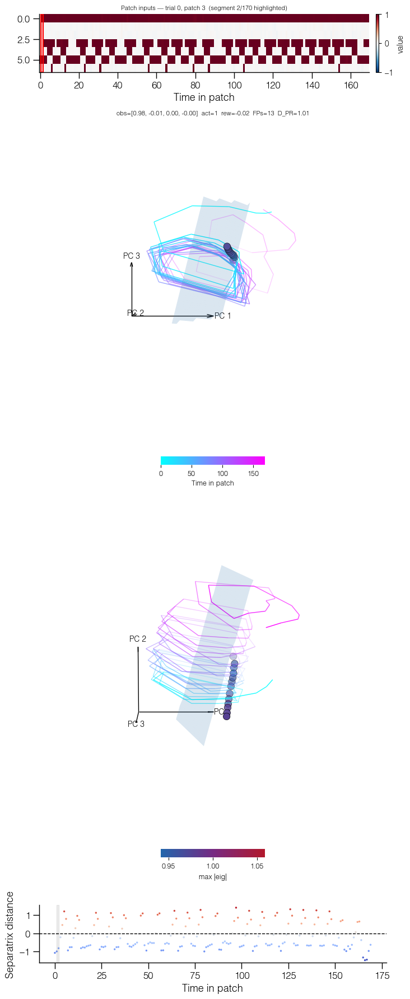

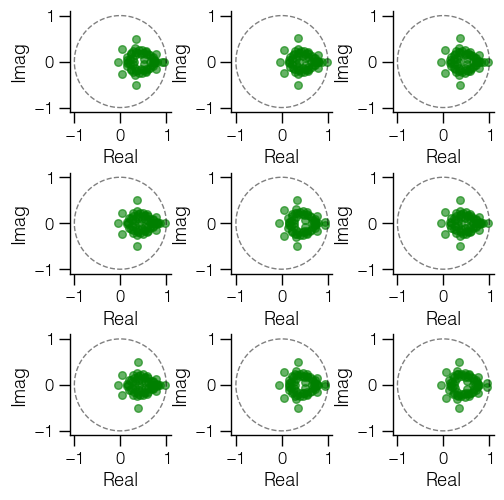

<Figure size 640x480 with 0 Axes>

Session 900: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000900.pkl


Trial 0, patch 3  (global steps 548–656, length 109)  → 109 segments with ≥2 steps


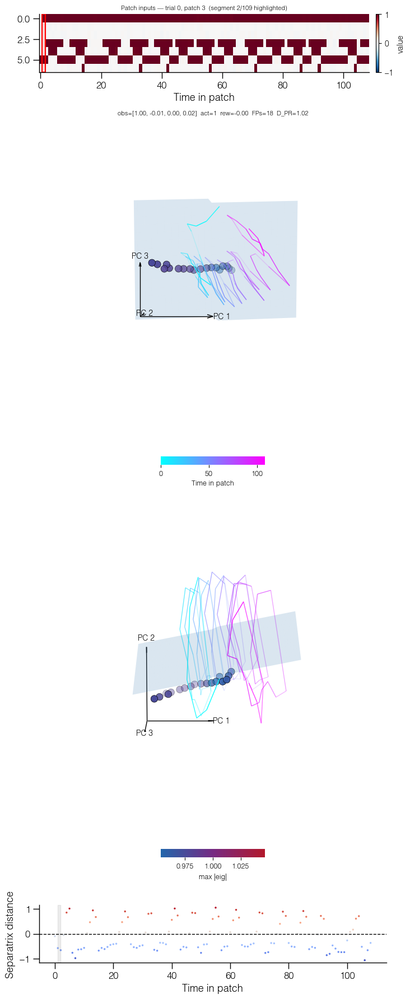

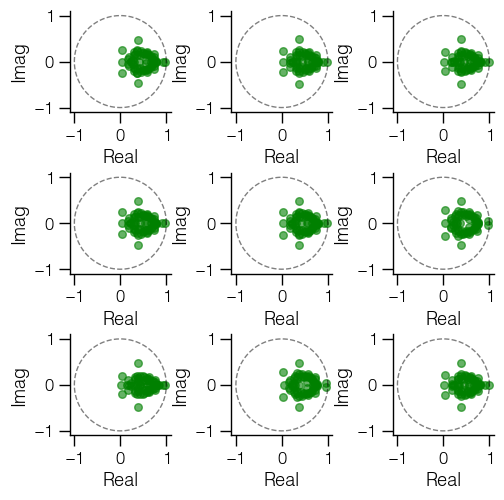

<Figure size 640x480 with 0 Axes>

Session 1900: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_001900.pkl


Trial 0, patch 3  (global steps 808–915, length 108)  → 108 segments with ≥2 steps


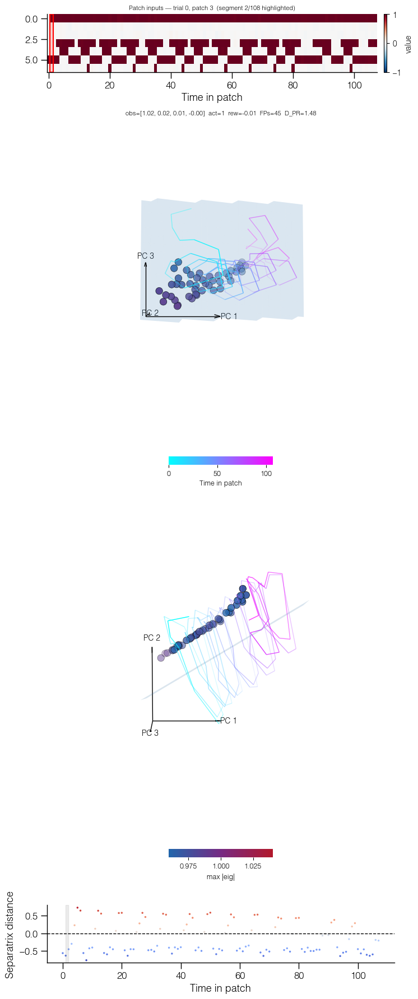

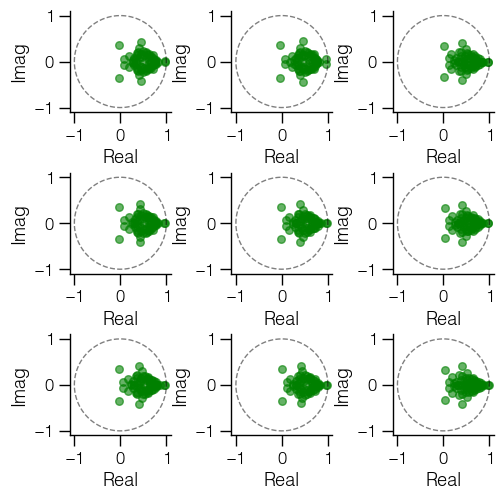

<Figure size 640x480 with 0 Axes>

In [ ]:
import re

STRUCT_EVO_RESULTS_DIR = Path('../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed')
STRUCT_EVO_CKPT_DIR = Path('../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_reward_normed')

# Collect all (session_abs, traj_path, ckpt_path) triples
pairs = []
for traj_path in sorted(STRUCT_EVO_RESULTS_DIR.rglob('traj_*.pkl')):
    m = re.search(r'traj_(\d+)\.pkl$', traj_path.name)
    if not m:
        continue
    session_abs = int(m.group(1))
    step_dir = traj_path.parent.name  # e.g. 'step_00'
    ckpt_path = STRUCT_EVO_CKPT_DIR / step_dir / f'checkpoint_{session_abs}'
    if ckpt_path.exists():
        pairs.append((session_abs, traj_path, ckpt_path))

pairs.sort(key=lambda x: x[0])
print(f'Found {len(pairs)} traj/checkpoint pairs')

# Sessions 0, 100, 200, ..., 900
target_sessions = set([0, 25, 50, 75, 100, 125, 150, 175, 200, 500, 900, 1900])
selected = [(s, t, c) for s, t, c in pairs if s in target_sessions]
print(f'Selected {len(selected)} pairs at sessions: {[s for s, _, _ in selected]}')

for session_abs, traj_path, ckpt_path in selected:
    # if session_abs > 0:
    #     continue
    print(f'{"="*60}')
    print(f'Session {session_abs}: {traj_path}')
    print(f'{"="*60}')

    traj_data_raw = load_trajectory_data(str(traj_path))
    traj_data = parse_behavioral_data(traj_data_raw[0])

    pca = PCA()
    pca.fit(traj_data['actor_hidden'])

    restored = checkpoints.restore_checkpoint(ckpt_dir=ckpt_path.resolve(), target=train_state)
    net_params = restored.params

    save_dir = os.path.join(
        '../../../figures',
        'structure_evo_exp_gru_initial_prob_offset',
        f'session_{session_abs:06d}',
    )

    plot_patch_segments_with_fixed_points(
        traj_data, net_params, network, pca,
        trial_idx=0,
        patch_idx=3,
        patch_type=2,
        n_fp_attempts=300,
        fp_tol=1e-3,
        azim=270,
        elev=0,
        azim2=90 + 180,
        elev2=160 + -60,
        includes_actions_and_rewards=True,
        stop_after_unique_inputs=True,
        round_inputs_for_uniqueness=True,
        traj_cmap=sns.color_palette(palette='cool', as_cmap=True),
        save_dir=save_dir,
        plot_current_segment=False,
        target_inputs=[
            [1, 0, 0, 0, 0, 1, 0]
        ],
    )

### Number and stability of fixed points across training

For the same input `[1, 0, 0, 0, 0, 1, 0]`, find the fixed points at each target
session and summarise (a) the number of fixed points vs. session and (b) the
spectrum of each fixed point's largest absolute eigenvalue, with each target
session coloured by a sequential colormap.

In [11]:
import re
from pathlib import Path
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize


def compute_fixed_point_evolution(
    results_dir,
    ckpt_dir,
    network,
    train_state,
    input_vecs,
    input_labels=None,
    target_sessions=None,
    n_fp_attempts=300,
    fp_tol=5e-3,
    fp_uniqueness_threshold=0.1,
    reward_rates_step='step_00',
    fp_max_steps=60000,
    fp_lr=0.001,
    seed=42,
):
    """ONE PASS over the saved checkpoints: for each checkpoint whose session is in
    `target_sessions`, find the fixed points induced by each input in `input_vecs` and collect their
    counts and spectral radii, plus the mean reward rate. Returns a PICKLABLE dict of the collected
    arrays -- NO plotting (see plot_fixed_point_evolution, which consumes this dict)."""
    results_dir = Path(results_dir)
    ckpt_dir = Path(ckpt_dir)
    input_vecs = [jnp.asarray(v) for v in input_vecs]
    if input_labels is None:
        input_labels = [str([int(x) for x in np.array(v)]) for v in input_vecs]
    if target_sessions is None:
        target_sessions = np.arange(0, 2000, 25)
    target_sessions = set(int(s) for s in target_sessions)

    # Collect (session_abs, traj_path, ckpt_path) triples
    pairs = []
    for traj_path in sorted(results_dir.rglob('traj_*.pkl')):
        m = re.search(r'traj_(\d+)\.pkl$', traj_path.name)
        if not m:
            continue
        session_abs = int(m.group(1))
        step_dir = traj_path.parent.name
        ckpt_path = ckpt_dir / step_dir / f'checkpoint_{session_abs}'
        if ckpt_path.exists():
            pairs.append((session_abs, traj_path, ckpt_path))
    pairs.sort(key=lambda x: x[0])

    selected = [(s, t, c) for s, t, c in pairs if s in target_sessions]
    print(f'Selected {len(selected)} pairs at sessions: {[s for s, _, _ in selected]}')

    reward_rates_dir = ckpt_dir / '_reward_rates' / reward_rates_step

    n_inputs = len(input_vecs)
    fp_session_list = []
    fp_perf_list = []                                  # mean reward rate per session (input-independent)
    fp_count_per_input = [[] for _ in range(n_inputs)]      # [input][session] -> n fixed points
    fp_max_eigs_per_input = [[] for _ in range(n_inputs)]   # [input][session] -> array of spectral radii

    for session_abs, traj_path, ckpt_path in selected:
        print(f'Session {session_abs}:')

        traj_data_raw = load_trajectory_data(str(traj_path))
        traj_data = parse_behavioral_data(traj_data_raw[0])

        restored = checkpoints.restore_checkpoint(ckpt_dir=ckpt_path.resolve(), target=train_state)
        net_params = restored.params

        # Seed the fixed-point search from random recorded hidden states
        key = jax.random.PRNGKey(seed)
        idx = jax.random.randint(key, (n_fp_attempts,), 0, traj_data['actor_hidden'].shape[0])
        h_inits = jnp.array(traj_data['actor_hidden'][idx])

        fp_session_list.append(session_abs)
        rr_path = reward_rates_dir / f'{session_abs:06d}'
        if rr_path.exists():
            with open(rr_path, 'rb') as _f:
                rr = np.load(_f)
            fp_perf_list.append(float(np.mean(rr)))
        else:
            fp_perf_list.append(np.nan)

        for i_in, input_vec in enumerate(input_vecs):
            fps, converged, _ = find_fixed_points_batch(
                params=net_params, network=network, input_vec=input_vec,
                h_inits=h_inits, max_steps=fp_max_steps, learning_rate=fp_lr,
                tolerance=fp_tol, verbose=False,
            )
            unique_fps = filter_unique_fixed_points(
                fps, converged, uniqueness_threshold=fp_uniqueness_threshold,
            )
            n_fps = len(unique_fps)
            if n_fps > 0:
                eigenvalues = analyze_stability_batch(unique_fps, input_vec, net_params, network)
                max_eigs = np.array(jnp.max(jnp.abs(eigenvalues), axis=-1))   # spectral radius per FP
            else:
                max_eigs = np.array([])
            fp_count_per_input[i_in].append(n_fps)
            fp_max_eigs_per_input[i_in].append(max_eigs)
            print(f'  input {input_labels[i_in]}: {n_fps} unique fixed points')
        print(f'  reward rate {fp_perf_list[-1]:.4f}')

    if not fp_session_list:
        print('No checkpoints matched the requested sessions.')
        return None

    return {
        'sessions': np.array(fp_session_list),
        'counts': fp_count_per_input,
        'max_eigs': fp_max_eigs_per_input,
        'performance': np.array(fp_perf_list),
        'input_labels': input_labels,
        'reward_rates_step': reward_rates_step,
    }


def _per_input_limits(counts, max_eigs_list):
    """Compute per-input axis limits for the count and eigenvalue plots."""
    count_ymax = (max(counts) if counts else 1) + 0.5
    max_n_fps  = max(counts) if counts else 1
    eigs_flat  = [me for me in max_eigs_list if len(me) > 0]
    if eigs_flat:
        all_eigs = np.concatenate(eigs_flat)
        eig_lo   = min(float(all_eigs.min()), 1.0)
        eig_hi   = max(float(all_eigs.max()), 1.0)
        pad      = 0.05 * (eig_hi - eig_lo) if eig_hi > eig_lo else 0.05
        eig_ylim = (eig_lo - pad, eig_hi + pad)
    else:
        eig_ylim = (0.0, 1.05)
    return count_ymax, max_n_fps, eig_ylim


def _make_fp_count_fig(fp_session_list, counts, label, colors, cmap_obj, norm,
                       count_ymax, colorbar_label, figsize, marker_size):
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(fp_session_list, counts, color='lightgray', lw=1, zorder=1)
    ax.scatter(fp_session_list, counts, c=colors, s=marker_size, zorder=2,
               edgecolors='k', linewidths=0.5)
    ax.set_xlabel('Session')
    ax.set_ylabel('Number of fixed points')
    ax.set_ylim(0, count_ymax)
    ax.set_title(f'Fixed points — input {label}')
    sm = ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, label=colorbar_label)
    cb.outline.set_visible(False)
    format_plot(ax)
    fig.tight_layout()
    return fig


def _make_eig_spectrum_fig(fp_session_list, max_eigs_list, label, cmap_obj, norm,
                           max_n_fps, eig_ylim, colorbar_label, figsize, perf_list=None):
    fig, ax = plt.subplots(figsize=figsize)
    for j, (s, max_eigs) in enumerate(zip(fp_session_list, max_eigs_list)):
        if len(max_eigs) == 0:
            continue
        color_key = perf_list[j] if perf_list is not None else s
        if perf_list is not None and not np.isfinite(color_key):
            continue
        sorted_eigs = np.sort(max_eigs)[::-1]
        ax.plot(np.arange(1, len(sorted_eigs) + 1), sorted_eigs,
                marker='o', ms=4, lw=1, color=cmap_obj(norm(color_key)), alpha=0.85)
    ax.axhline(1.0, color='red', ls='--', lw=1, alpha=0.5, label='|eig| = 1')
    ax.set_xlim(0.5, max_n_fps + 0.5)
    ax.set_ylim(*eig_ylim)
    ax.set_xlabel('Fixed point (sorted by largest |eig|)')
    ax.set_ylabel('Largest |eigenvalue|')
    ax.set_title(f'Spectral radii — input {label}')
    ax.legend(fontsize=8, frameon=False)
    sm = ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, label=colorbar_label)
    cb.outline.set_visible(False)
    format_plot(ax)
    fig.tight_layout()
    return fig


def plot_fixed_point_evolution(
    data,
    perf_threshold=0.068,
    cmap='viridis',
    perf_cmap='cividis',
    figsize=(4.5, 3),
    marker_size=12,
):
    """Make the fixed-point-structure figures from a dict returned by compute_fixed_point_evolution.

    Produces TWO versions of each per-input panel:
      (a) number of fixed points vs session,
      (b) spectrum of each fixed point's largest |eigenvalue| vs session.
    Version 1 colours by session (cmap, default 'viridis').
    Version 2 colours by performance/reward-rate (perf_cmap, default 'plasma').
    Each plot uses its own per-input axis limits (not shared across inputs).
    A final performance-vs-session plot and a mean fixed-point-count vs session
    plot (mean ± SD across inputs, shown as horizontal error bars, coloured by
    reward rate) are also produced.

    Returns `data` augmented with the list of figures under 'figs'.
    """
    fp_session_list   = list(np.asarray(data['sessions']))
    fp_count_per_input    = data['counts']
    fp_max_eigs_per_input = data['max_eigs']
    input_labels      = data['input_labels']
    perf              = np.asarray(data['performance'])
    reward_rates_step = data.get('reward_rates_step', '')
    n_inputs          = len(fp_count_per_input)

    # --- Colormap 1: coloured by session ---
    cmap_obj   = plt.get_cmap(cmap) if isinstance(cmap, str) else cmap
    norm_sess  = Normalize(vmin=min(fp_session_list), vmax=max(fp_session_list))
    sess_colors = [cmap_obj(norm_sess(s)) for s in fp_session_list]

    # --- Colormap 2: coloured by performance ---
    perf_cmap_obj = plt.get_cmap(perf_cmap) if isinstance(perf_cmap, str) else perf_cmap
    perf_finite   = perf[np.isfinite(perf)]
    norm_perf     = Normalize(
        vmin=float(perf_finite.min()) if len(perf_finite) else 0.0,
        vmax=float(perf_finite.max()) if len(perf_finite) else 1.0,
    )
    perf_colors = [
        perf_cmap_obj(norm_perf(p)) if np.isfinite(p) else (0.5, 0.5, 0.5, 1.0)
        for p in perf
    ]

    figs = []

    for i_in in range(n_inputs):
        counts        = fp_count_per_input[i_in]
        max_eigs_list = fp_max_eigs_per_input[i_in]
        label         = input_labels[i_in]
        count_ymax, max_n_fps, eig_ylim = _per_input_limits(counts, max_eigs_list)

        # Version 1 — coloured by session
        fig_a = _make_fp_count_fig(
            fp_session_list, counts, label, sess_colors,
            cmap_obj, norm_sess, count_ymax, 'Session', figsize, marker_size,
        )
        plt.show(); figs.append(fig_a)

        fig_b = _make_eig_spectrum_fig(
            fp_session_list, max_eigs_list, label,
            cmap_obj, norm_sess, max_n_fps, eig_ylim, 'Session', figsize,
        )
        plt.show(); figs.append(fig_b)

        # Version 2 — coloured by performance
        fig_a2 = _make_fp_count_fig(
            fp_session_list, counts, label, perf_colors,
            perf_cmap_obj, norm_perf, count_ymax, 'Reward rate', figsize, marker_size,
        )
        plt.show(); figs.append(fig_a2)

        fig_b2 = _make_eig_spectrum_fig(
            fp_session_list, max_eigs_list, label,
            perf_cmap_obj, norm_perf, max_n_fps, eig_ylim, 'Reward rate', figsize,
            perf_list=list(perf),
        )
        plt.show(); figs.append(fig_b2)

    # --- Performance vs session ---
    sess = np.asarray(fp_session_list)
    mask = np.isfinite(perf)
    fig_c, ax_c = plt.subplots(figsize=figsize)
    ax_c.plot(sess[mask], perf[mask], color='lightgray', lw=1, zorder=1)
    ax_c.scatter(sess[mask], perf[mask],
                 c=[cmap_obj(norm_sess(s)) for s in sess[mask]], s=marker_size, zorder=2,
                 edgecolors='k', linewidths=0.5)
    if perf_threshold is not None:
        ax_c.axhline(perf_threshold, color='red', ls='--', lw=1, alpha=0.5)
    ax_c.set_xlabel('Session')
    ax_c.set_ylabel('Mean reward rate')
    ax_c.set_title(f'Performance across training ({reward_rates_step})')
    ax_c.set_xscale('log')
    format_plot(ax_c)
    fig_c.tight_layout()
    plt.show()
    figs.append(fig_c)

    # --- Mean (±SD across inputs) fixed-point count vs session, coloured by reward rate ---
    counts_matrix = np.array(
        [[fp_count_per_input[i][j] for i in range(n_inputs)]
         for j in range(len(fp_session_list))],
        dtype=float,
    )  # shape (n_sessions, n_inputs)
    mean_counts = counts_matrix.mean(axis=1)
    std_counts  = counts_matrix.std(axis=1)

    valid = np.isfinite(perf)
    perf_v        = perf[valid]
    mean_counts_v = mean_counts[valid]
    std_counts_v  = std_counts[valid]
    sess_v        = sess[valid]

    # Sort by session so the connecting line follows training order
    order = np.argsort(sess_v)
    sess_sorted        = sess_v[order]
    mean_counts_sorted = mean_counts_v[order]
    std_counts_sorted  = std_counts_v[order]
    perf_sorted        = perf_v[order]

    fig_d, ax_d = plt.subplots(figsize=figsize)
    ax_d.plot(sess_sorted, mean_counts_sorted, color='lightgray', lw=1, zorder=1)
    ax_d.errorbar(
        sess_sorted, mean_counts_sorted,
        yerr=std_counts_sorted,
        fmt='none', ecolor='steelblue', elinewidth=1, capsize=3, alpha=0.7, zorder=2,
    )
    ax_d.scatter(
        sess_sorted, mean_counts_sorted,
        c=[perf_cmap_obj(norm_perf(p)) for p in perf_sorted],
        s=marker_size, zorder=3, edgecolors='k', linewidths=0.5,
    )
    y_max = float((mean_counts_sorted + std_counts_sorted).max())
    ax_d.set_ylim(0, y_max * 1.05)
    ax_d.set_xlabel('Session')
    ax_d.set_ylabel('Fixed points')
    sm = ScalarMappable(cmap=perf_cmap_obj, norm=norm_perf)
    sm.set_array([])
    cb = fig_d.colorbar(sm, ax=ax_d, label='Mean reward rate')
    cb.outline.set_visible(False)
    format_plot(ax_d)
    fig_d.tight_layout()
    plt.show()
    figs.append(fig_d)

    return {**data, 'figs': figs}


Selected 80 pairs at sessions: [0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 425, 450, 475, 500, 525, 550, 575, 600, 625, 650, 675, 700, 725, 750, 775, 800, 825, 850, 875, 900, 925, 950, 975, 1000, 1025, 1050, 1075, 1100, 1125, 1150, 1175, 1200, 1225, 1250, 1275, 1300, 1325, 1350, 1375, 1400, 1425, 1450, 1475, 1500, 1525, 1550, 1575, 1600, 1625, 1650, 1675, 1700, 1725, 1750, 1775, 1800, 1825, 1850, 1875, 1900, 1925, 1950, 1975]
Session 0:


  input [1, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  reward rate 0.0130
Session 25:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  reward rate 0.0559
Session 50:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 8 unique fixed points
  reward rate 0.0608
Session 75:


  input [1, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 7 unique fixed points
  reward rate 0.0629
Session 100:


  input [1, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0649
Session 125:


... (71 outputs left out)

  input [1, 0, 0, 0, 0, 1, 0]: 47 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 10 unique fixed points
  reward rate 0.0674
Session 1925:


  input [1, 0, 0, 0, 0, 1, 0]: 65 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 8 unique fixed points
  reward rate 0.0673
Session 1950:


  input [1, 0, 0, 0, 0, 1, 0]: 46 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  reward rate 0.0670
Session 1975:


  input [1, 0, 0, 0, 0, 1, 0]: 53 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 7 unique fixed points
  reward rate 0.0676


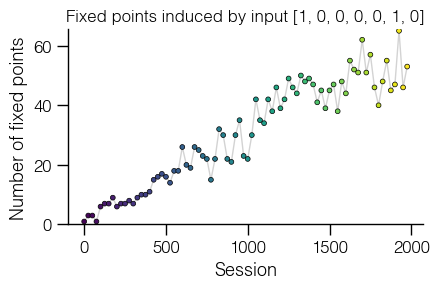

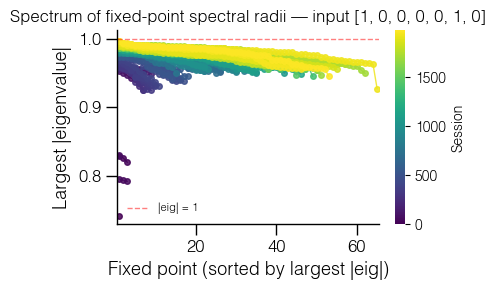

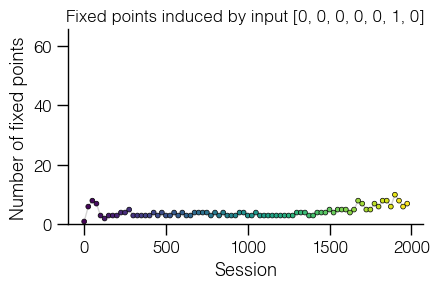

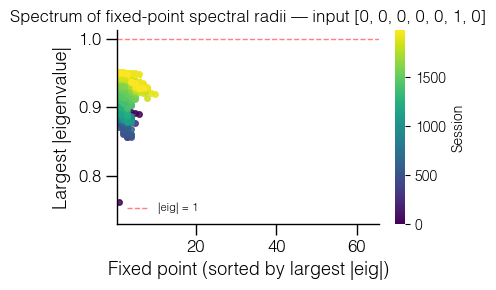

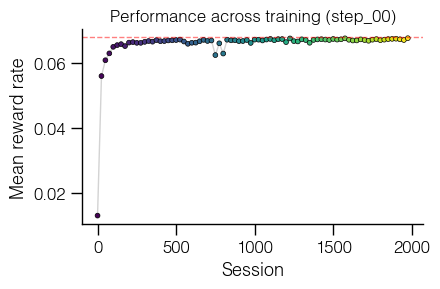

In [ ]:
# Reproduce the original analysis for structure_evo_exp_gru_initial_prob_offset
_fp_evo = plot_fixed_point_evolution(
    results_dir=STRUCT_EVO_RESULTS_DIR,
    ckpt_dir=STRUCT_EVO_CKPT_DIR,
    network=network,
    train_state=train_state,
    input_vecs=[
        jnp.array([1., 0., 0., 0., 0., 1., 0.]),   # in patch, no odor
        jnp.array([0., 0., 0., 0., 0., 1., 0.]),   # out of patch
    ],
    target_sessions=np.arange(0, 2000, 25),
    n_fp_attempts=400,
    fp_tol=1e-3,
    fp_uniqueness_threshold=0.1,
    perf_threshold=0.068,
)



Network: structure_evo_exp_gru_initial_prob_offset_full_net0
Selected 80 pairs at sessions: [0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 425, 450, 475, 500, 525, 550, 575, 600, 625, 650, 675, 700, 725, 750, 775, 800, 825, 850, 875, 900, 925, 950, 975, 1000, 1025, 1050, 1075, 1100, 1125, 1150, 1175, 1200, 1225, 1250, 1275, 1300, 1325, 1350, 1375, 1400, 1425, 1450, 1475, 1500, 1525, 1550, 1575, 1600, 1625, 1650, 1675, 1700, 1725, 1750, 1775, 1800, 1825, 1850, 1875, 1900, 1925, 1950, 1975]
Session 0:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0145
Session 25:


  input [1, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0558
Session 50:


  input [1, 0, 0, 0, 0, 1, 0]: 5 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 5 unique fixed points
  reward rate 0.0610
Session 75:


  input [1, 0, 0, 0, 0, 1, 0]: 7 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0630
Session 100:


  input [1, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0497
Session 125:


... (71 outputs left out)

  input [1, 0, 0, 0, 0, 1, 0]: 45 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0670
Session 1925:


  input [1, 0, 0, 0, 0, 1, 0]: 30 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0672
Session 1950:


  input [1, 0, 0, 0, 0, 1, 0]: 45 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0670
Session 1975:


  input [1, 0, 0, 0, 0, 1, 0]: 38 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0669


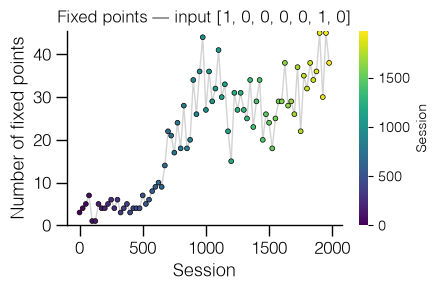

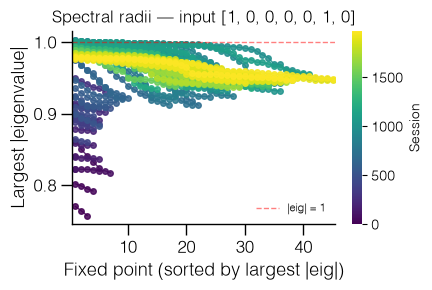

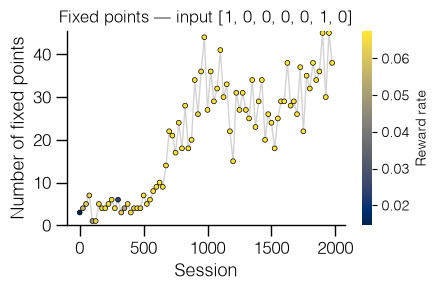

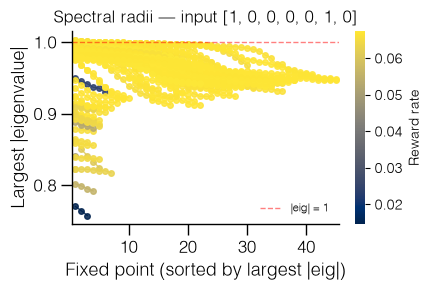

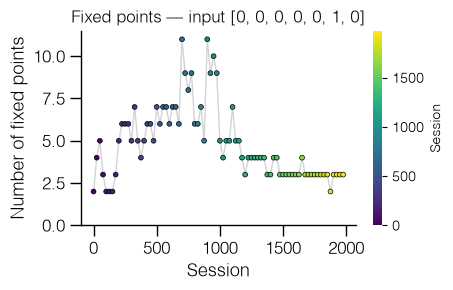

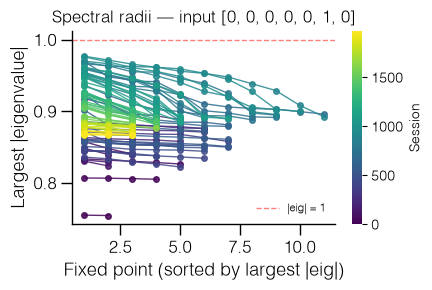

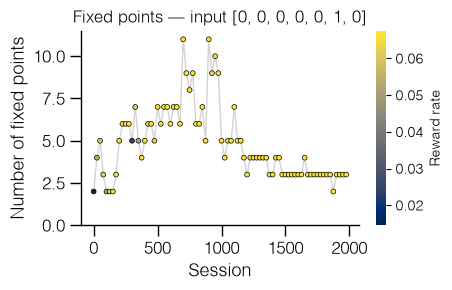

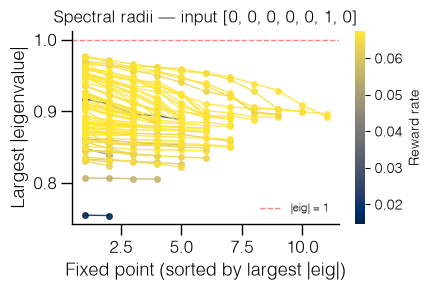

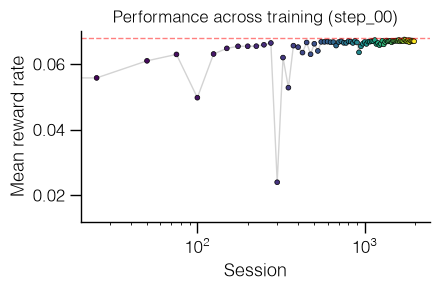

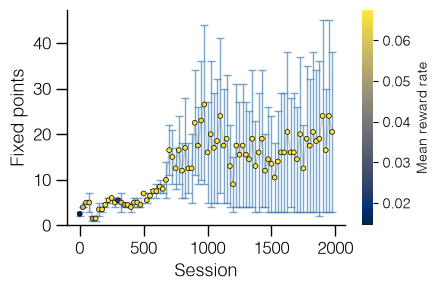


Network: structure_evo_exp_gru_initial_prob_offset_full_net1
Selected 80 pairs at sessions: [0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 425, 450, 475, 500, 525, 550, 575, 600, 625, 650, 675, 700, 725, 750, 775, 800, 825, 850, 875, 900, 925, 950, 975, 1000, 1025, 1050, 1075, 1100, 1125, 1150, 1175, 1200, 1225, 1250, 1275, 1300, 1325, 1350, 1375, 1400, 1425, 1450, 1475, 1500, 1525, 1550, 1575, 1600, 1625, 1650, 1675, 1700, 1725, 1750, 1775, 1800, 1825, 1850, 1875, 1900, 1925, 1950, 1975]
Session 0:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0165
Session 25:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0568
Session 50:


  input [1, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 8 unique fixed points
  reward rate 0.0607
Session 75:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 5 unique fixed points
  reward rate 0.0629
Session 100:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0629
Session 125:


... (71 outputs left out)

  input [1, 0, 0, 0, 0, 1, 0]: 28 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 5 unique fixed points
  reward rate 0.0674
Session 1925:


  input [1, 0, 0, 0, 0, 1, 0]: 30 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 5 unique fixed points
  reward rate 0.0672
Session 1950:


  input [1, 0, 0, 0, 0, 1, 0]: 29 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 5 unique fixed points
  reward rate 0.0674
Session 1975:


  input [1, 0, 0, 0, 0, 1, 0]: 16 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 5 unique fixed points
  reward rate 0.0672


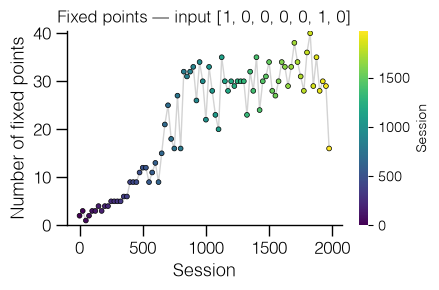

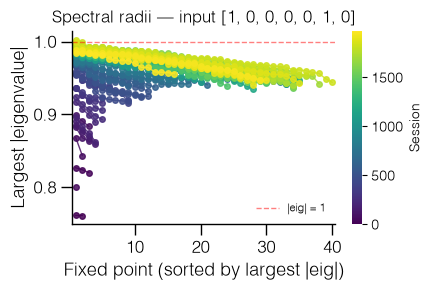

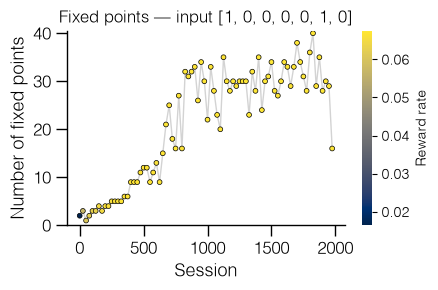

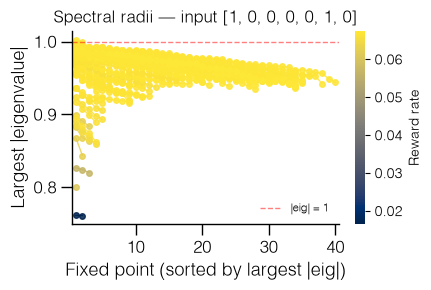

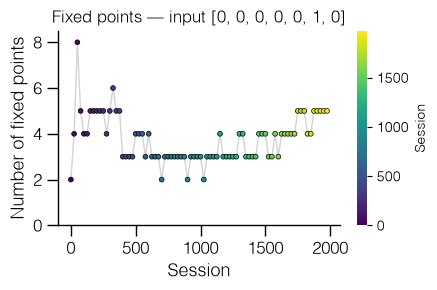

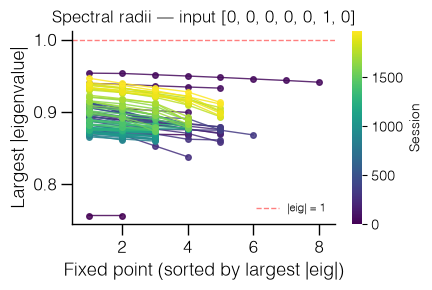

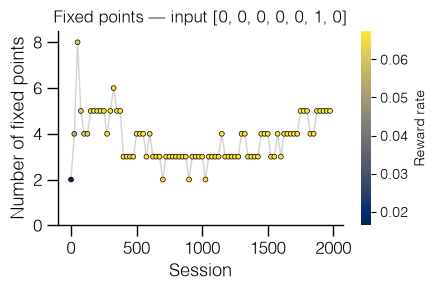

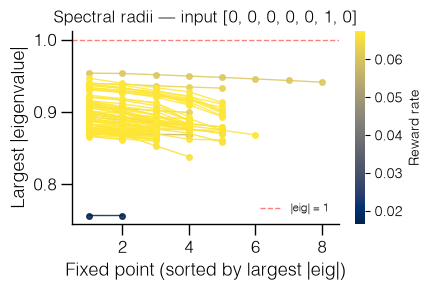

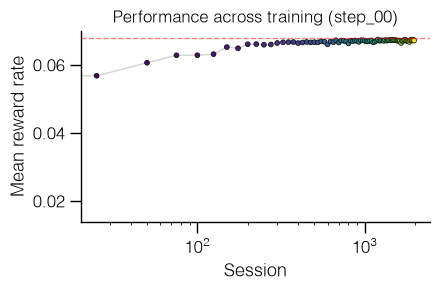

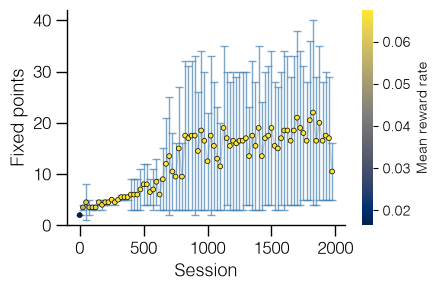


Network: structure_evo_exp_gru_initial_prob_offset_full_net2
Selected 80 pairs at sessions: [0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 425, 450, 475, 500, 525, 550, 575, 600, 625, 650, 675, 700, 725, 750, 775, 800, 825, 850, 875, 900, 925, 950, 975, 1000, 1025, 1050, 1075, 1100, 1125, 1150, 1175, 1200, 1225, 1250, 1275, 1300, 1325, 1350, 1375, 1400, 1425, 1450, 1475, 1500, 1525, 1550, 1575, 1600, 1625, 1650, 1675, 1700, 1725, 1750, 1775, 1800, 1825, 1850, 1875, 1900, 1925, 1950, 1975]
Session 0:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0130
Session 25:


  input [1, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  reward rate 0.0562
Session 50:


  input [1, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 11 unique fixed points
  reward rate 0.0604
Session 75:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  reward rate 0.0616
Session 100:


  input [1, 0, 0, 0, 0, 1, 0]: 8 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0635
Session 125:


... (71 outputs left out)

  input [1, 0, 0, 0, 0, 1, 0]: 47 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0671
Session 1925:


  input [1, 0, 0, 0, 0, 1, 0]: 46 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0675
Session 1950:


  input [1, 0, 0, 0, 0, 1, 0]: 57 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 5 unique fixed points
  reward rate 0.0673
Session 1975:


  input [1, 0, 0, 0, 0, 1, 0]: 50 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 5 unique fixed points
  reward rate 0.0674


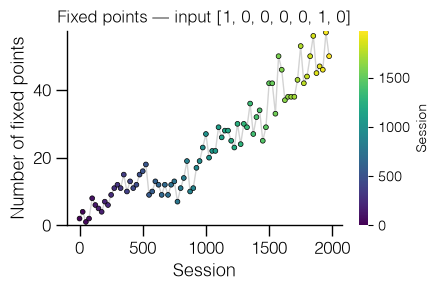

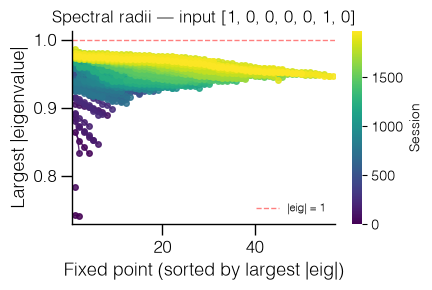

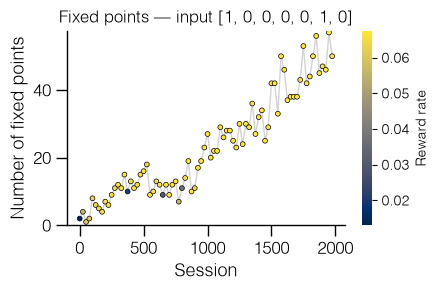

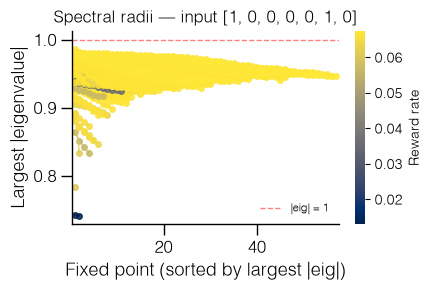

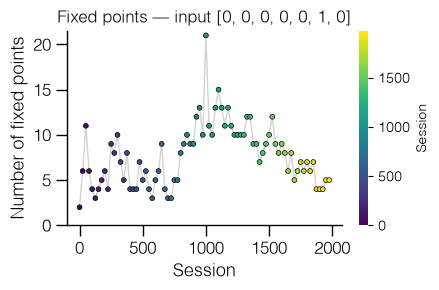

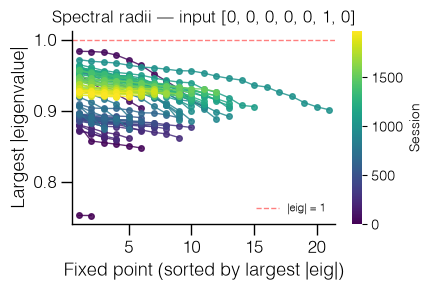

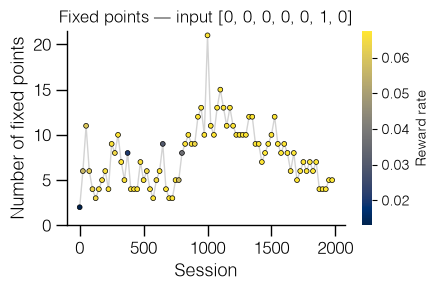

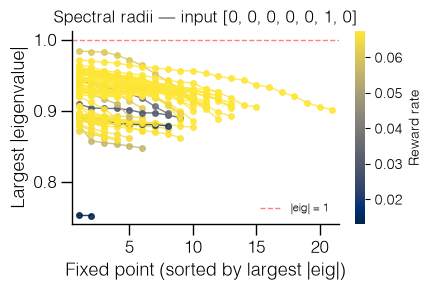

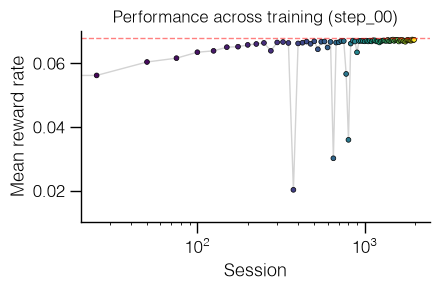

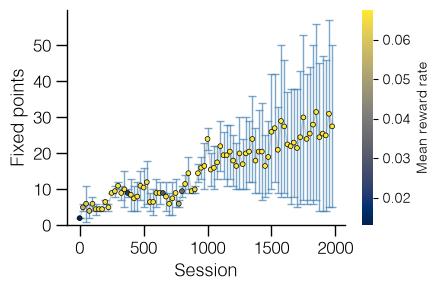


Network: structure_evo_exp_gru_initial_prob_offset_full_net3
Selected 80 pairs at sessions: [0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 425, 450, 475, 500, 525, 550, 575, 600, 625, 650, 675, 700, 725, 750, 775, 800, 825, 850, 875, 900, 925, 950, 975, 1000, 1025, 1050, 1075, 1100, 1125, 1150, 1175, 1200, 1225, 1250, 1275, 1300, 1325, 1350, 1375, 1400, 1425, 1450, 1475, 1500, 1525, 1550, 1575, 1600, 1625, 1650, 1675, 1700, 1725, 1750, 1775, 1800, 1825, 1850, 1875, 1900, 1925, 1950, 1975]
Session 0:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  reward rate 0.0151
Session 25:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 5 unique fixed points
  reward rate 0.0563
Session 50:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 8 unique fixed points
  reward rate 0.0606
Session 75:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  reward rate 0.0625
Session 100:


  input [1, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 5 unique fixed points
  reward rate 0.0645
Session 125:


... (71 outputs left out)

  input [1, 0, 0, 0, 0, 1, 0]: 39 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0672
Session 1925:


  input [1, 0, 0, 0, 0, 1, 0]: 28 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0670
Session 1950:


  input [1, 0, 0, 0, 0, 1, 0]: 38 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0672
Session 1975:


  input [1, 0, 0, 0, 0, 1, 0]: 29 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0674


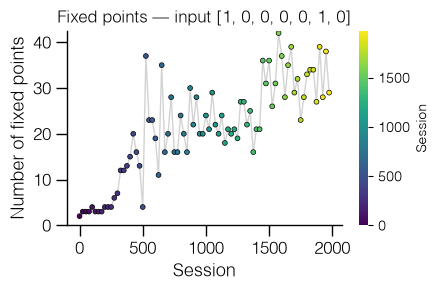

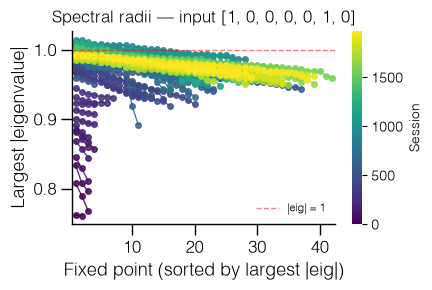

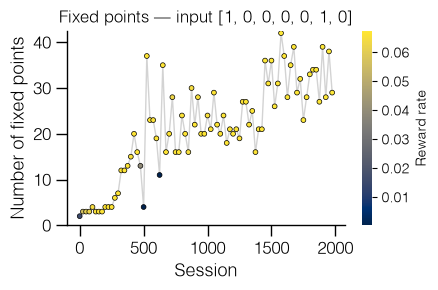

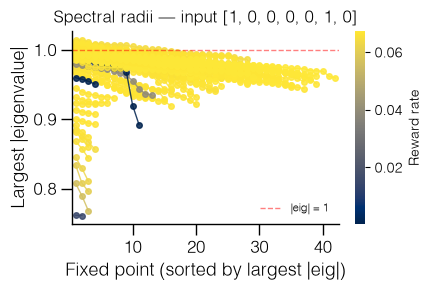

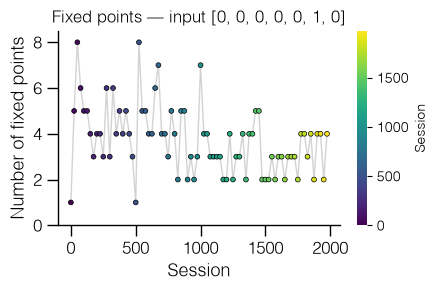

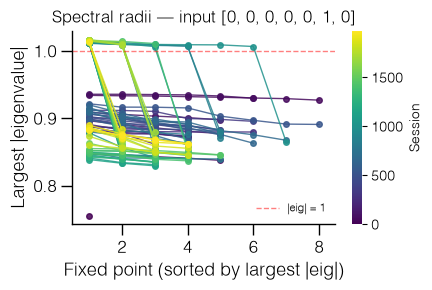

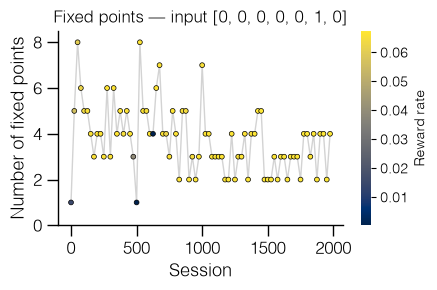

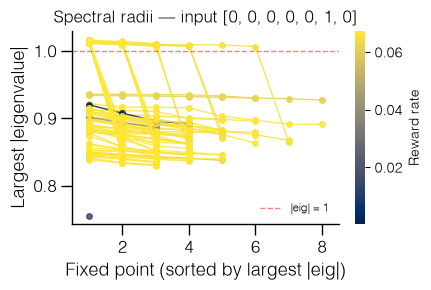

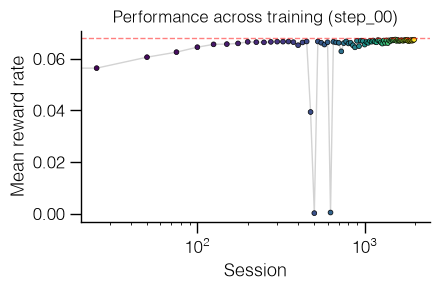

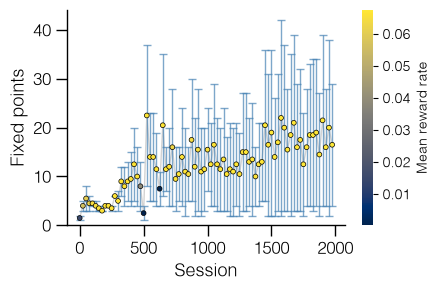


Network: structure_evo_exp_gru_initial_prob_offset_full_net4
Selected 80 pairs at sessions: [0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 425, 450, 475, 500, 525, 550, 575, 600, 625, 650, 675, 700, 725, 750, 775, 800, 825, 850, 875, 900, 925, 950, 975, 1000, 1025, 1050, 1075, 1100, 1125, 1150, 1175, 1200, 1225, 1250, 1275, 1300, 1325, 1350, 1375, 1400, 1425, 1450, 1475, 1500, 1525, 1550, 1575, 1600, 1625, 1650, 1675, 1700, 1725, 1750, 1775, 1800, 1825, 1850, 1875, 1900, 1925, 1950, 1975]
Session 0:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0189
Session 25:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0571
Session 50:


  input [1, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0615
Session 75:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0633
Session 100:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0649
Session 125:


... (71 outputs left out)

  input [1, 0, 0, 0, 0, 1, 0]: 49 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0672
Session 1925:


  input [1, 0, 0, 0, 0, 1, 0]: 44 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 5 unique fixed points
  reward rate 0.0672
Session 1950:


  input [1, 0, 0, 0, 0, 1, 0]: 35 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0674
Session 1975:


  input [1, 0, 0, 0, 0, 1, 0]: 45 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0671


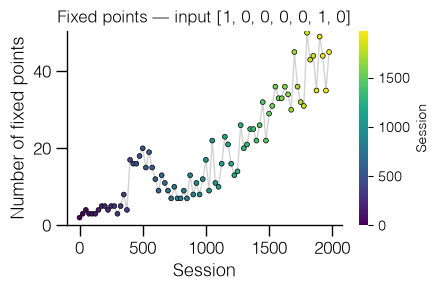

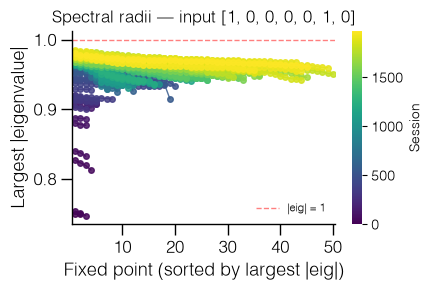

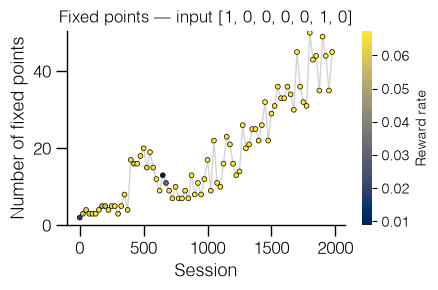

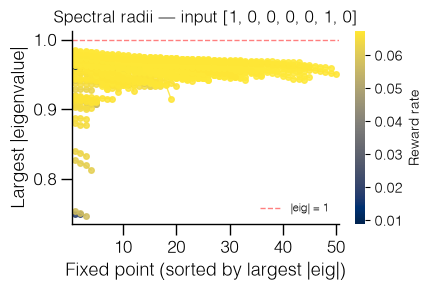

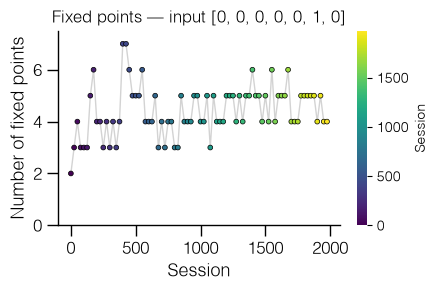

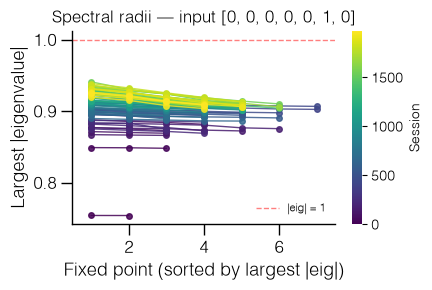

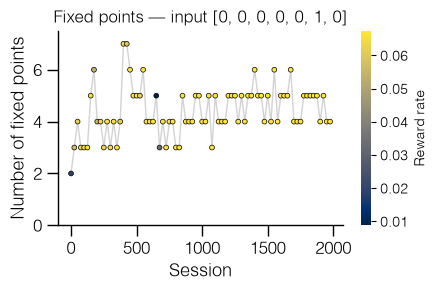

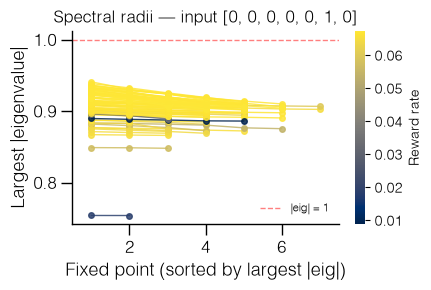

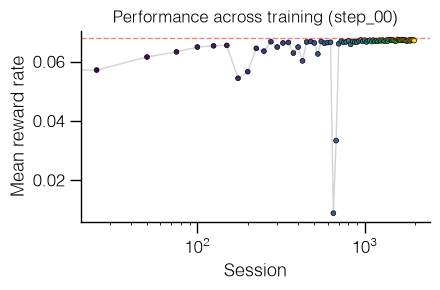

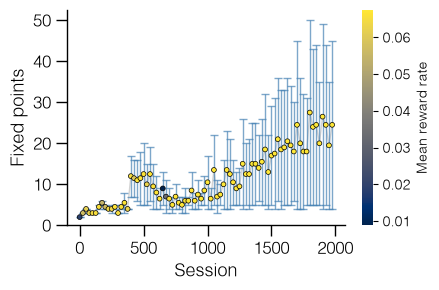

In [12]:
# Fixed-point dynamics across training for each full_net (0-4)
_full_net_fp_evos = {}
for _net_idx in range(5):
    _name = f'structure_evo_exp_gru_initial_prob_offset_full_net{_net_idx}'
    print(f'\n{"="*70}')
    print(f'Network: {_name}')
    print(f'{"="*70}')
    _data = compute_fixed_point_evolution(
        results_dir=Path(f'../../../results/{_name}'),
        ckpt_dir=Path(f'../../../checkpoints/{_name}'),
        network=network,
        train_state=train_state,
        input_vecs=[
            jnp.array([1., 0., 0., 0., 0., 1., 0.]),   # in patch, no odor
            jnp.array([0., 0., 0., 0., 0., 1., 0.]),   # out of patch
        ],
        target_sessions=np.arange(0, 2000, 25),
        n_fp_attempts=400,
        fp_tol=1e-3,
        fp_uniqueness_threshold=0.1,
    )
    if _data is not None:
        _full_net_fp_evos[_net_idx] = plot_fixed_point_evolution(
            _data, perf_threshold=0.068,
        )


Selected 50 pairs at sessions: [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150, 155, 160, 165, 170, 175, 180, 185, 190, 195, 200, 205, 210, 215, 220, 225, 230, 235, 240, 245]
Session 0:


  input [1, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  reward rate 0.0130
Session 5:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0315
Session 10:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  reward rate 0.0457
Session 15:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 9 unique fixed points
  reward rate 0.0507
Session 20:


  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 7 unique fixed points
  reward rate 0.0540
Session 25:


... (41 outputs left out)

  input [1, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0660
Session 235:


  input [1, 0, 0, 0, 0, 1, 0]: 7 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0657
Session 240:


  input [1, 0, 0, 0, 0, 1, 0]: 6 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  reward rate 0.0618
Session 245:


  input [1, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0638


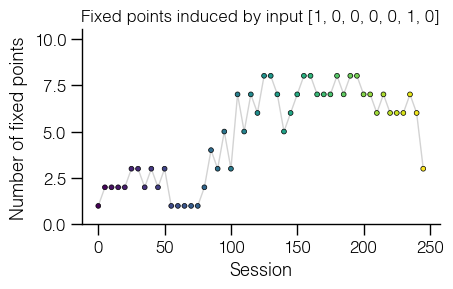

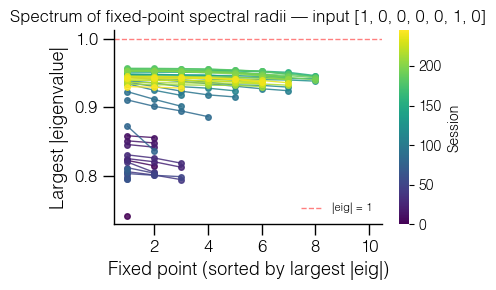

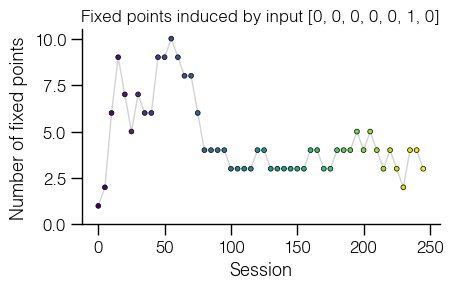

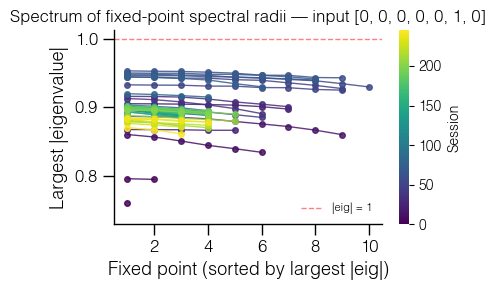

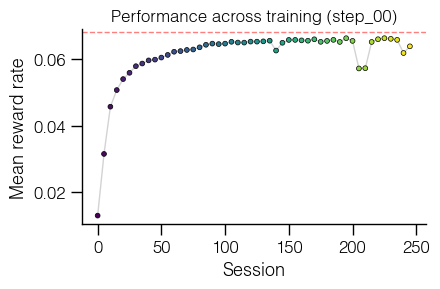

In [ ]:
STRUCT_EVO_RESULTS_DIR_FIRST_250 = Path('../../../results/structure_evo_exp_gru_initial_prob_offset_first_250')
STRUCT_EVO_CKPT_DIR_FIRST_250 = Path('../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_first_250')

# Reproduce the original analysis for structure_evo_exp_gru_initial_prob_offset
_fp_evo = plot_fixed_point_evolution(
    results_dir=STRUCT_EVO_RESULTS_DIR_FIRST_250,
    ckpt_dir=STRUCT_EVO_CKPT_DIR_FIRST_250,
    network=network,
    train_state=train_state,
    input_vecs=[
        jnp.array([1., 0., 0., 0., 0., 1., 0.]),   # in patch, no odor
        jnp.array([0., 0., 0., 0., 0., 1., 0.]),   # out of patch
    ],
    target_sessions=np.arange(0, 250, 5),
    n_fp_attempts=400,
    fp_tol=1e-3,
    fp_uniqueness_threshold=0.1,
    perf_threshold=0.068,
)

In [45]:
# Find all unique binarized inputs observed in STRUCT_EVO_RESULTS_DIR_FIRST_250, then COMPUTE the
# fixed points for each one in ONE PASS and SAVE the result. Plotting is done in the downstream cell.
import re

STRUCT_EVO_RESULTS_DIR = Path('../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed')
STRUCT_EVO_CKPT_DIR = Path('../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_reward_normed')


# Collect traj/checkpoint pairs from the FIRST_250 directory
_pairs_250 = []
for _traj_path in sorted(STRUCT_EVO_RESULTS_DIR.rglob('traj_*.pkl')):
    _m = re.search(r'traj_(\d+)\.pkl$', _traj_path.name)
    if not _m:
        continue
    _session_abs = int(_m.group(1))
    _step_dir = _traj_path.parent.name
    _ckpt_path = STRUCT_EVO_CKPT_DIR / _step_dir / f'checkpoint_{_session_abs}'
    if _ckpt_path.exists():
        _pairs_250.append((_session_abs, _traj_path, _ckpt_path))
_pairs_250.sort(key=lambda x: x[0])

# Use the latest checkpoint to enumerate which inputs actually occur
_last_session_250, _last_traj_250, _ = _pairs_250[-1]
print(f'Enumerating unique inputs from session {_last_session_250}: {_last_traj_250}')

_traj_raw = load_trajectory_data(str(_last_traj_250))
_traj_rep = parse_behavioral_data(_traj_raw[0])

# observations already encodes [obs(4), prev_action_onehot(2), prev_reward(1)]
_obs_flat = np.array(_traj_rep['observations'])  # (T, 7)

# Route each dimension to the closest 0 or 1
_binarized = np.round(_obs_flat).clip(0, 1)

_unique_inputs, _counts = np.unique(_binarized, axis=0, return_counts=True)

MIN_OCCURRENCES = 5
_keep = _counts >= MIN_OCCURRENCES
_unique_inputs = _unique_inputs[_keep]
_counts = _counts[_keep]

print(f'Found {len(_unique_inputs)} unique binarized inputs (min_occurrences={MIN_OCCURRENCES}):')
for _inp, _cnt in zip(_unique_inputs, _counts):
    print(f'  {[int(x) for x in _inp]}  (n={_cnt})')

import pickle

_fp_evo_data = compute_fixed_point_evolution(
    results_dir=STRUCT_EVO_RESULTS_DIR,
    ckpt_dir=STRUCT_EVO_CKPT_DIR,
    network=network,
    train_state=train_state,
    input_vecs=[jnp.array(_inp) for _inp in _unique_inputs],
    target_sessions=np.arange(0, 2000, 25),
    n_fp_attempts=400,
    fp_tol=1e-3,
    fp_uniqueness_threshold=0.2,
    fp_max_steps=10000,
)

# Save the one-pass computation so the downstream plotting cell never recomputes.
FP_EVO_SAVE_PATH = STRUCT_EVO_RESULTS_DIR / 'fixed_point_evolution.pkl'
with open(FP_EVO_SAVE_PATH, 'wb') as _f:
    pickle.dump(_fp_evo_data, _f)
print(f'Saved fixed-point evolution ({len(_fp_evo_data["sessions"])} sessions) to {FP_EVO_SAVE_PATH}')


Enumerating unique inputs from session 1975: ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_001975.pkl
Found 10 unique binarized inputs (min_occurrences=5):
  [0, 0, 0, 0, 0, 1, 0]  (n=1559)
  [1, 0, 0, 0, 0, 1, 0]  (n=4308)
  [1, 0, 0, 0, 1, 0, 0]  (n=7)
  [1, 0, 0, 1, 0, 1, 0]  (n=4266)
  [1, 0, 0, 1, 1, 0, 0]  (n=3166)
  [1, 0, 0, 1, 1, 0, 1]  (n=848)
  [1, 0, 1, 0, 0, 1, 0]  (n=2940)
  [1, 0, 1, 0, 1, 0, 0]  (n=2108)
  [1, 0, 1, 0, 1, 0, 1]  (n=485)
  [1, 1, 0, 0, 0, 1, 0]  (n=311)
Selected 80 pairs at sessions: [0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 425, 450, 475, 500, 525, 550, 575, 600, 625, 650, 675, 700, 725, 750, 775, 800, 825, 850, 875, 900, 925, 950, 975, 1000, 1025, 1050, 1075, 1100, 1125, 1150, 1175, 1200, 1225, 1250, 1275, 1300, 1325, 1350, 1375, 1400, 1425, 1450, 1475, 1500, 1525, 1550, 1575, 1600, 1625, 1650, 1675, 1700, 1725, 1750, 1775, 1800, 1825, 1850, 1875, 1900, 1925, 1950, 1975]
Ses

  input [0, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  input [1, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  input [1, 0, 0, 0, 1, 0, 0]: 1 unique fixed points
  input [1, 0, 0, 1, 0, 1, 0]: 1 unique fixed points
  input [1, 0, 0, 1, 1, 0, 0]: 1 unique fixed points
  input [1, 0, 0, 1, 1, 0, 1]: 1 unique fixed points
  input [1, 0, 1, 0, 0, 1, 0]: 1 unique fixed points
  input [1, 0, 1, 0, 1, 0, 0]: 1 unique fixed points
  input [1, 0, 1, 0, 1, 0, 1]: 1 unique fixed points
  input [1, 1, 0, 0, 0, 1, 0]: 1 unique fixed points
  reward rate 0.0130
Session 25:


  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [1, 0, 0, 0, 1, 0, 0]: 2 unique fixed points
  input [1, 0, 0, 1, 0, 1, 0]: 3 unique fixed points
  input [1, 0, 0, 1, 1, 0, 0]: 2 unique fixed points
  input [1, 0, 0, 1, 1, 0, 1]: 2 unique fixed points
  input [1, 0, 1, 0, 0, 1, 0]: 2 unique fixed points
  input [1, 0, 1, 0, 1, 0, 0]: 2 unique fixed points
  input [1, 0, 1, 0, 1, 0, 1]: 2 unique fixed points
  input [1, 1, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0559
Session 50:


  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  input [1, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [1, 0, 0, 0, 1, 0, 0]: 2 unique fixed points
  input [1, 0, 0, 1, 0, 1, 0]: 1 unique fixed points
  input [1, 0, 0, 1, 1, 0, 0]: 2 unique fixed points
  input [1, 0, 0, 1, 1, 0, 1]: 2 unique fixed points
  input [1, 0, 1, 0, 0, 1, 0]: 1 unique fixed points
  input [1, 0, 1, 0, 1, 0, 0]: 2 unique fixed points
  input [1, 0, 1, 0, 1, 0, 1]: 2 unique fixed points
  input [1, 1, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0608
Session 75:


  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [1, 0, 0, 0, 0, 1, 0]: 1 unique fixed points
  input [1, 0, 0, 0, 1, 0, 0]: 2 unique fixed points
  input [1, 0, 0, 1, 0, 1, 0]: 1 unique fixed points
  input [1, 0, 0, 1, 1, 0, 0]: 3 unique fixed points
  input [1, 0, 0, 1, 1, 0, 1]: 4 unique fixed points
  input [1, 0, 1, 0, 0, 1, 0]: 1 unique fixed points
  input [1, 0, 1, 0, 1, 0, 0]: 2 unique fixed points
  input [1, 0, 1, 0, 1, 0, 1]: 3 unique fixed points
  input [1, 1, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0629
Session 100:


  input [0, 0, 0, 0, 0, 1, 0]: 2 unique fixed points
  input [1, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  input [1, 0, 0, 0, 1, 0, 0]: 3 unique fixed points
  input [1, 0, 0, 1, 0, 1, 0]: 1 unique fixed points
  input [1, 0, 0, 1, 1, 0, 0]: 4 unique fixed points
  input [1, 0, 0, 1, 1, 0, 1]: 6 unique fixed points
  input [1, 0, 1, 0, 0, 1, 0]: 2 unique fixed points
  input [1, 0, 1, 0, 1, 0, 0]: 3 unique fixed points
  input [1, 0, 1, 0, 1, 0, 1]: 4 unique fixed points
  input [1, 1, 0, 0, 0, 1, 0]: 3 unique fixed points
  reward rate 0.0649
Session 125:


... (71 outputs left out)

  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  input [1, 0, 0, 0, 0, 1, 0]: 16 unique fixed points
  input [1, 0, 0, 0, 1, 0, 0]: 18 unique fixed points
  input [1, 0, 0, 1, 0, 1, 0]: 14 unique fixed points
  input [1, 0, 0, 1, 1, 0, 0]: 19 unique fixed points
  input [1, 0, 0, 1, 1, 0, 1]: 11 unique fixed points
  input [1, 0, 1, 0, 0, 1, 0]: 7 unique fixed points
  input [1, 0, 1, 0, 1, 0, 0]: 14 unique fixed points
  input [1, 0, 1, 0, 1, 0, 1]: 32 unique fixed points
  input [1, 1, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0674
Session 1925:


  input [0, 0, 0, 0, 0, 1, 0]: 4 unique fixed points
  input [1, 0, 0, 0, 0, 1, 0]: 23 unique fixed points
  input [1, 0, 0, 0, 1, 0, 0]: 20 unique fixed points
  input [1, 0, 0, 1, 0, 1, 0]: 16 unique fixed points
  input [1, 0, 0, 1, 1, 0, 0]: 14 unique fixed points
  input [1, 0, 0, 1, 1, 0, 1]: 7 unique fixed points
  input [1, 0, 1, 0, 0, 1, 0]: 8 unique fixed points
  input [1, 0, 1, 0, 1, 0, 0]: 14 unique fixed points
  input [1, 0, 1, 0, 1, 0, 1]: 15 unique fixed points
  input [1, 1, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0673
Session 1950:


  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [1, 0, 0, 0, 0, 1, 0]: 19 unique fixed points
  input [1, 0, 0, 0, 1, 0, 0]: 18 unique fixed points
  input [1, 0, 0, 1, 0, 1, 0]: 15 unique fixed points
  input [1, 0, 0, 1, 1, 0, 0]: 20 unique fixed points
  input [1, 0, 0, 1, 1, 0, 1]: 8 unique fixed points
  input [1, 0, 1, 0, 0, 1, 0]: 7 unique fixed points
  input [1, 0, 1, 0, 1, 0, 0]: 14 unique fixed points
  input [1, 0, 1, 0, 1, 0, 1]: 7 unique fixed points
  input [1, 1, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0670
Session 1975:


  input [0, 0, 0, 0, 0, 1, 0]: 3 unique fixed points
  input [1, 0, 0, 0, 0, 1, 0]: 22 unique fixed points
  input [1, 0, 0, 0, 1, 0, 0]: 20 unique fixed points
  input [1, 0, 0, 1, 0, 1, 0]: 17 unique fixed points
  input [1, 0, 0, 1, 1, 0, 0]: 20 unique fixed points
  input [1, 0, 0, 1, 1, 0, 1]: 10 unique fixed points
  input [1, 0, 1, 0, 0, 1, 0]: 7 unique fixed points
  input [1, 0, 1, 0, 1, 0, 0]: 16 unique fixed points
  input [1, 0, 1, 0, 1, 0, 1]: 11 unique fixed points
  input [1, 1, 0, 0, 0, 1, 0]: 2 unique fixed points
  reward rate 0.0676
Saved fixed-point evolution (80 sessions) to ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/fixed_point_evolution.pkl


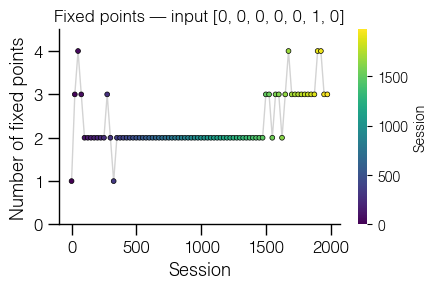

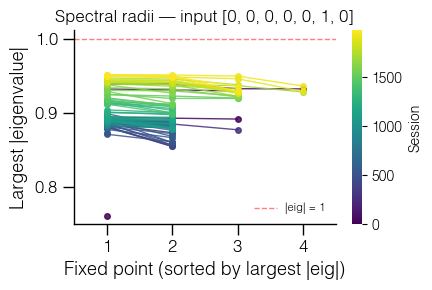

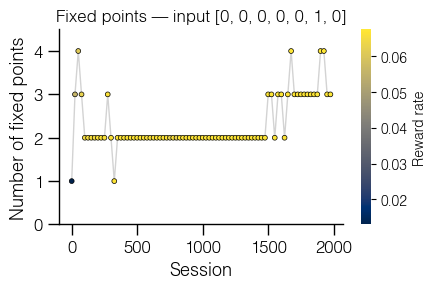

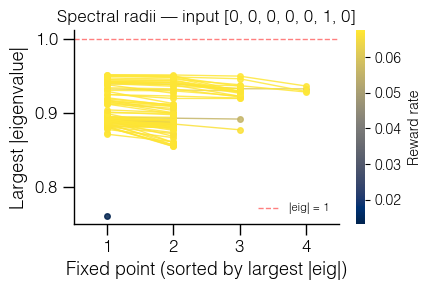

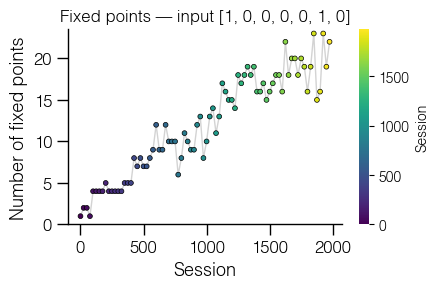

...

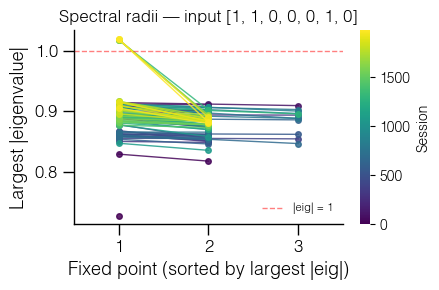

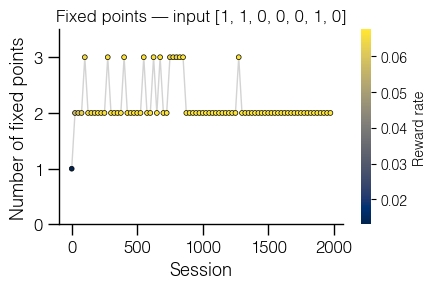

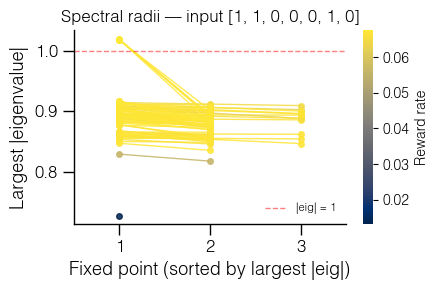

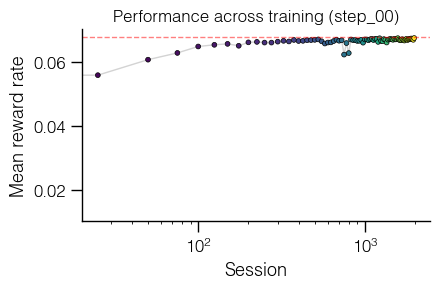

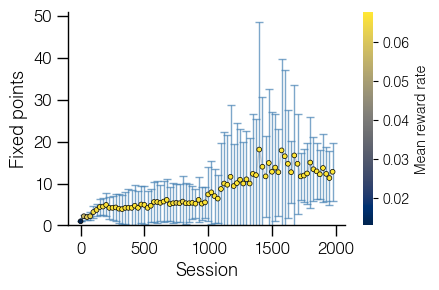

: 

In [ ]:
# Downstream: load the saved one-pass fixed-point computation and MAKE THE PLOTS.
import pickle

STRUCT_EVO_RESULTS_DIR = Path('../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed')
FP_EVO_SAVE_PATH = STRUCT_EVO_RESULTS_DIR / 'fixed_point_evolution.pkl'

with open(FP_EVO_SAVE_PATH, 'rb') as _f:
    _fp_evo_all = pickle.load(_f)

# per-input panels (a) count vs session, (b) eigenvalue spectrum, and (c) performance
_fp_evo_reduced = plot_fixed_point_evolution(_fp_evo_all, perf_threshold=0.068)


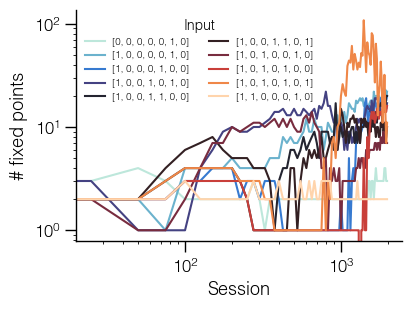

In [29]:
# Final summary: number of fixed points vs session for ALL inputs, each trajectory
# normalized to a FRACTION of that input's own maximum count over training.
_sessions   = np.asarray(_fp_evo_all['sessions'])
_counts_all = _fp_evo_all['counts']          # [input][session] -> n unique fixed points
_labels_all = _fp_evo_all['input_labels']

scale = 0.6
fig, ax = plt.subplots(figsize=(7 * scale, 5 * scale))
_cmap = sns.color_palette(palette='icefire', n_colors=max(len(_counts_all), 1), as_cmap=True)
for _i, (_counts, _lbl) in enumerate(zip(_counts_all, _labels_all)):
    _c = np.asarray(_counts, dtype=float)
    _cmax = np.nanmax(_c) if _c.size else 0.0
    if _cmax <= 0:                            # input never had a fixed point -> nothing to normalize
        continue
    _frac = _c # / _cmax                        # fraction of this input's max #FPs over time
    ax.plot(_sessions[:len(_frac)], _frac, lw=1.5,
            color=_cmap(_i/(len(_counts_all)-1) if len(_counts_all) > 1 else 0), alpha=1, label=_lbl)
    # ax.scatter(_sessions[:len(_frac)], _frac, marker='o', s=20,
    #            color=_cmap(_i), label=_lbl)

ax.set_xlabel('Session')
ax.set_ylabel('# fixed points')
# ax.set_ylim(0, 1.05)
# ax.set_title('Fixed points number across training (all inputs)')
ax.legend(fontsize=7, ncol=2, frameon=False, title='Input')
ax.set_yscale('log')
ax.set_xscale('log')
format_plot(ax)
# fig.tight_layout()
plt.show()


In [19]:
import pickle
import numpy as np
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import make_pipeline as imb_make_pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.decomposition import PCA as skPCA

# ── config ──────────────────────────────────────────────────────────────────
TARGET_INPUT   = jnp.array([1., 0., 0., 0., 0., 1., 0.])
_FP_ATTEMPTS   = 400
_FP_TOL        = 1e-3
_FP_UNIQUENESS = 0.2
_FP_MAX_STEPS  = 10000

STRUCT_EVO_RESULTS_DIR = Path('../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed')
STRUCT_EVO_CKPT_DIR = Path('../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_reward_normed')

FP_EVO_SAVE_PATH = STRUCT_EVO_RESULTS_DIR / 'fixed_point_evolution.pkl'
with open(FP_EVO_SAVE_PATH, 'rb') as _f:
    _fp_evo = pickle.load(_f)
sessions_to_run = _fp_evo['sessions']
perf_by_session = dict(zip(_fp_evo['sessions'].tolist(), _fp_evo['performance'].tolist()))

# results[patch_type] -> list of (session_abs, auc_dist, auc_pc1, perf, part_ratio)
_results = {1: [], 2: []}
_rng_key = jax.random.PRNGKey(42)

for session_abs in sessions_to_run:
    traj_path = STRUCT_EVO_RESULTS_DIR / 'step_00' / f'traj_{session_abs:06d}.pkl'
    ckpt_path = STRUCT_EVO_CKPT_DIR    / 'step_00' / f'checkpoint_{session_abs}'
    if not traj_path.exists() or not ckpt_path.exists():
        print(f'  [skip] session {session_abs}: missing file')
        continue

    traj_raw  = load_trajectory_data(str(traj_path))
    traj_data = parse_behavioral_data(traj_raw[0])
    _T = traj_data['actor_hidden'].shape[0]

    restored   = checkpoints.restore_checkpoint(ckpt_dir=ckpt_path.resolve(), target=train_state)
    net_params = restored.params

    _rng_key, subkey = jax.random.split(_rng_key)
    idx    = jax.random.randint(subkey, (_FP_ATTEMPTS,), 0, _T)
    h_init = jnp.array(traj_data['actor_hidden'][idx])

    fps_raw, converged, _ = find_fixed_points_batch(
        params=net_params, network=network, input_vec=TARGET_INPUT,
        h_inits=h_init, max_steps=_FP_MAX_STEPS, learning_rate=0.001,
        tolerance=_FP_TOL, verbose=False,
    )
    fps = np.array(filter_unique_fixed_points(fps_raw, converged, uniqueness_threshold=_FP_UNIQUENESS))

    if len(fps) == 0:
        print(f'  [skip] session {session_abs}: no fixed points')
        continue

    _pca_full  = skPCA().fit(fps)
    _eigs      = _pca_full.explained_variance_
    part_ratio = float(_eigs.sum()**2 / (_eigs**2).sum())
    pc1_axis   = _pca_full.components_[0]

    rsi_2d = traj_data['reward_site_idx'].reshape(1, _T).T
    att_2d = traj_data['current_reward_site_attempted'].reshape(1, _T).T

    pre_odor   = find_pre_odor_onset_states(traj_data, max_lookahead=1, include_first=True)
    hidden_pre = pre_odor['hidden'][:, 0, :]

    stopped_labels, patch_types = [], []
    for i in range(len(pre_odor['trial_idx'])):
        trial   = pre_odor['trial_idx'][i]
        onset_t = pre_odor['pre_t_idx'][i] + 1
        t = onset_t
        while t < _T and rsi_2d[t, trial] >= 0:
            t += 1
        stopped_labels.append(int(np.any(att_2d[onset_t:t, trial])))
        patch_types.append(int(traj_data['current_patch_num'][onset_t]))
    stopped_labels = np.array(stopped_labels)
    patch_types    = np.array(patch_types)

    diffs    = hidden_pre[:, np.newaxis, :] - fps[np.newaxis, :, :]
    min_dist = np.sqrt((diffs**2).sum(axis=-1)).min(axis=1)
    pc1_proj = hidden_pre @ pc1_axis

    perf = perf_by_session.get(int(session_abs), np.nan)
    cv   = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    pipe = imb_make_pipeline(
        RandomUnderSampler(random_state=0),
        StandardScaler(),
        LogisticRegression(max_iter=500),
    )

    for pt in (1, 2):
        mask     = patch_types == pt
        leave_pt = (stopped_labels[mask] == 0).astype(int)
        if leave_pt.sum() < 5 or (leave_pt == 0).sum() < 5:
            continue
        auc_dist = cross_val_score(pipe, min_dist[mask].reshape(-1, 1), leave_pt, cv=cv, scoring='roc_auc').mean()
        auc_pc1  = cross_val_score(pipe, pc1_proj[mask].reshape(-1, 1), leave_pt, cv=cv, scoring='roc_auc').mean()
        _results[pt].append((int(session_abs), auc_dist, auc_pc1, perf, part_ratio))
    print(f'  session {session_abs:4d}  dim={part_ratio:.2f}  perf={perf:.4f}')

fp_leave_results = {pt: np.array(v) for pt, v in _results.items()}

CACHE_PATH = STRUCT_EVO_RESULTS_DIR / 'fp_leave_predict_results.pkl'
with open(CACHE_PATH, 'wb') as _f:
    pickle.dump(fp_leave_results, _f)
print(f'Saved -> {CACHE_PATH}')


/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/sklearn/decomposition/_pca.py:586: RuntimeWarning: invalid value encountered in divide
  explained_variance_ = (S**2) / (n_samples - 1)


  session    0  dim=nan  perf=0.0130


  session   25  dim=1.00  perf=0.0559


  session   50  dim=1.00  perf=0.0608


/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/sklearn/decomposition/_pca.py:586: RuntimeWarning: invalid value encountered in divide
  explained_variance_ = (S**2) / (n_samples - 1)


  session   75  dim=nan  perf=0.0629


... (72 outputs left out)

  session 1900  dim=1.62  perf=0.0674


  session 1925  dim=1.59  perf=0.0673


  session 1950  dim=1.55  perf=0.0670


  session 1975  dim=1.35  perf=0.0676
Saved -> ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/fp_leave_predict_results.pkl


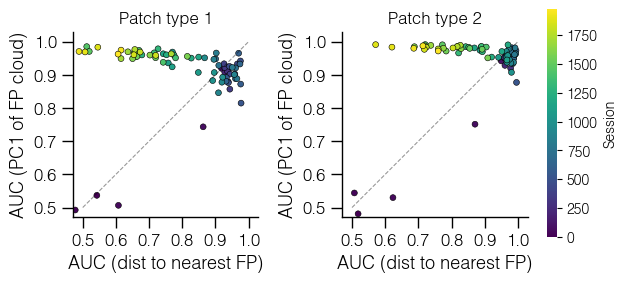

In [20]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

STRUCT_EVO_RESULTS_DIR = Path('../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed')
CACHE_PATH = STRUCT_EVO_RESULTS_DIR / 'fp_leave_predict_results.pkl'

with open(CACHE_PATH, 'rb') as _f:
    fp_leave_results = pickle.load(_f)

# fp_leave_results[patch_type] -> array (N, 5): session, auc_dist, auc_pc1, perf, part_ratio

all_sess  = np.concatenate([fp_leave_results[pt][:, 0] for pt in (1, 2)])
norm_sess = Normalize(vmin=all_sess.min(), vmax=all_sess.max())
perf_cmap = plt.cm.viridis

scale = 0.65
fig, axes = plt.subplots(1, 2, figsize=(10 * scale, 5 * scale))
fig.subplots_adjust(left=0.1, right=0.80, wspace=0.45)

for ax, pt in zip(axes, (1, 2)):
    r = fp_leave_results[pt]
    ax.scatter(r[:, 1], r[:, 2],
               c=r[:, 0], cmap=perf_cmap, norm=norm_sess,
               s=18, edgecolors='k', linewidths=0.4, zorder=2)
    ax.plot([0.5, 1], [0.5, 1], lw=0.8, ls='--', color='k', alpha=0.4)
    ticks = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    ax.set_xlim(0.47, 1.03); ax.set_ylim(0.47, 1.03)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_aspect('equal')
    ax.set_xlabel('AUC (dist to nearest FP)')
    ax.set_ylabel('AUC (PC1 of FP cloud)')
    ax.set_title(f'Patch type {pt}')
    format_plot(ax)

cax = fig.add_axes([0.83, 0.15, 0.015, 0.7])
cb  = fig.colorbar(ScalarMappable(cmap=perf_cmap, norm=norm_sess), cax=cax, label='Session')
cb.outline.set_visible(False)
plt.show()


In [14]:
# Leave-one-out FP analysis for full_net0..4 (compute + save)
import re, pickle
import numpy as np
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import make_pipeline as imb_make_pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.decomposition import PCA as skPCA

_TARGET_INPUT   = jnp.array([1., 0., 0., 0., 0., 1., 0.])
_FP_ATTEMPTS_FN = 400
_FP_TOL_FN      = 1e-3
_FP_UNIQUENESS_FN = 0.2
_FP_MAX_STEPS_FN  = 10000

for _net_idx in range(5):
    _name     = f'structure_evo_exp_gru_initial_prob_offset_full_net{_net_idx}'
    _res_dir  = Path(f'../../../results/{_name}')
    _ckpt_dir = Path(f'../../../checkpoints/{_name}')
    print(f'\n{"="*70}')
    print(f'Network: {_name}')
    print(f'{"="*70}')

    # Collect all available (session_abs, traj_path, ckpt_path) triples
    _pairs_fn = []
    for _tp in sorted(_res_dir.rglob('traj_*.pkl')):
        _m = re.search(r'traj_(\d+)\.pkl$', _tp.name)
        if not _m:
            continue
        _s = int(_m.group(1))
        _step = _tp.parent.name
        _cp = _ckpt_dir / _step / f'checkpoint_{_s}'
        if _cp.exists():
            _pairs_fn.append((_s, _tp, _cp))
    _pairs_fn.sort(key=lambda x: x[0])
    _sessions_fn = [s for s, _, _ in _pairs_fn]

    # Performance: try to load from reward_rates dir, fall back to NaN
    _perf_by_sess_fn = {}
    _rr_dir_fn = _ckpt_dir / '_reward_rates' / 'step_00'
    if _rr_dir_fn.exists():
        for _rr_file in _rr_dir_fn.iterdir():
            try:
                with open(_rr_file, 'rb') as _f:
                    _rr = np.load(_f)
                _perf_by_sess_fn[int(_rr_file.name)] = float(np.mean(_rr))
            except Exception:
                pass

    _results_fn = {1: [], 2: []}
    _rng_key_fn = jax.random.PRNGKey(42)

    for _s, _tp, _cp in _pairs_fn:
        _traj_raw  = load_trajectory_data(str(_tp))
        _traj_data = parse_behavioral_data(_traj_raw[0])
        _T_fn = _traj_data['actor_hidden'].shape[0]

        _restored_fn   = checkpoints.restore_checkpoint(ckpt_dir=_cp.resolve(), target=train_state)
        _net_params_fn = _restored_fn.params

        _rng_key_fn, _subkey_fn = jax.random.split(_rng_key_fn)
        _idx_fn    = jax.random.randint(_subkey_fn, (_FP_ATTEMPTS_FN,), 0, _T_fn)
        _h_init_fn = jnp.array(_traj_data['actor_hidden'][_idx_fn])

        _fps_raw_fn, _conv_fn, _ = find_fixed_points_batch(
            params=_net_params_fn, network=network, input_vec=_TARGET_INPUT,
            h_inits=_h_init_fn, max_steps=_FP_MAX_STEPS_FN, learning_rate=0.001,
            tolerance=_FP_TOL_FN, verbose=False,
        )
        _fps_fn = np.array(filter_unique_fixed_points(_fps_raw_fn, _conv_fn,
                                                       uniqueness_threshold=_FP_UNIQUENESS_FN))
        if len(_fps_fn) == 0:
            print(f'  [skip] session {_s}: no fixed points')
            continue

        _pca_fn    = skPCA().fit(_fps_fn)
        _eigs_fn   = _pca_fn.explained_variance_
        _pr_fn     = float(_eigs_fn.sum()**2 / (_eigs_fn**2).sum())
        _pc1_fn    = _pca_fn.components_[0]

        _rsi2d_fn  = _traj_data['reward_site_idx'].reshape(1, _T_fn).T
        _att2d_fn  = _traj_data['current_reward_site_attempted'].reshape(1, _T_fn).T
        _pre_fn    = find_pre_odor_onset_states(_traj_data, max_lookahead=1, include_first=True)
        _hpre_fn   = _pre_fn['hidden'][:, 0, :]

        _stopped_fn, _ptypes_fn = [], []
        for _i in range(len(_pre_fn['trial_idx'])):
            _trial   = _pre_fn['trial_idx'][_i]
            _onset_t = _pre_fn['pre_t_idx'][_i] + 1
            _t = _onset_t
            while _t < _T_fn and _rsi2d_fn[_t, _trial] >= 0:
                _t += 1
            _stopped_fn.append(int(np.any(_att2d_fn[_onset_t:_t, _trial])))
            _ptypes_fn.append(int(_traj_data['current_patch_num'][_onset_t]))
        _stopped_fn = np.array(_stopped_fn)
        _ptypes_fn  = np.array(_ptypes_fn)

        _diffs_fn    = _hpre_fn[:, np.newaxis, :] - _fps_fn[np.newaxis, :, :]
        _min_dist_fn = np.sqrt((_diffs_fn**2).sum(axis=-1)).min(axis=1)
        _pc1_proj_fn = _hpre_fn @ _pc1_fn

        _perf_fn = _perf_by_sess_fn.get(int(_s), np.nan)
        _cv_fn   = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
        _pipe_fn = imb_make_pipeline(
            RandomUnderSampler(random_state=0),
            StandardScaler(),
            LogisticRegression(max_iter=500),
        )

        for _pt in (1, 2):
            _mask_fn   = _ptypes_fn == _pt
            _leave_fn  = (_stopped_fn[_mask_fn] == 0).astype(int)
            if _leave_fn.sum() < 5 or (_leave_fn == 0).sum() < 5:
                continue
            _auc_dist = cross_val_score(_pipe_fn, _min_dist_fn[_mask_fn].reshape(-1, 1),
                                        _leave_fn, cv=_cv_fn, scoring='roc_auc').mean()
            _auc_pc1  = cross_val_score(_pipe_fn, _pc1_proj_fn[_mask_fn].reshape(-1, 1),
                                        _leave_fn, cv=_cv_fn, scoring='roc_auc').mean()
            _results_fn[_pt].append((int(_s), _auc_dist, _auc_pc1, _perf_fn, _pr_fn))
        print(f'  session {_s:4d}  dim={_pr_fn:.2f}  perf={_perf_fn:.4f}')

    _fp_leave_fn = {pt: np.array(v) for pt, v in _results_fn.items()}
    _cache_fn = _res_dir / 'fp_leave_predict_results.pkl'
    with open(_cache_fn, 'wb') as _f:
        pickle.dump(_fp_leave_fn, _f)
    print(f'  Saved -> {_cache_fn}')



Network: structure_evo_exp_gru_initial_prob_offset_full_net0


/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/sklearn/decomposition/_pca.py:586: RuntimeWarning: invalid value encountered in divide
  explained_variance_ = (S**2) / (n_samples - 1)


  session    0  dim=nan  perf=0.0145


  session   25  dim=1.00  perf=0.0558


  session   50  dim=1.00  perf=0.0610


  session   75  dim=1.00  perf=0.0630


... (602 outputs left out)

  session 2900  dim=1.63  perf=0.0668


  session 2925  dim=1.39  perf=0.0671


  session 2950  dim=1.76  perf=0.0670


  session 2975  dim=1.92  perf=0.0673
  Saved -> ../../../results/structure_evo_exp_gru_initial_prob_offset_full_net4/fp_leave_predict_results.pkl



structure_evo_exp_gru_initial_prob_offset_full_net0


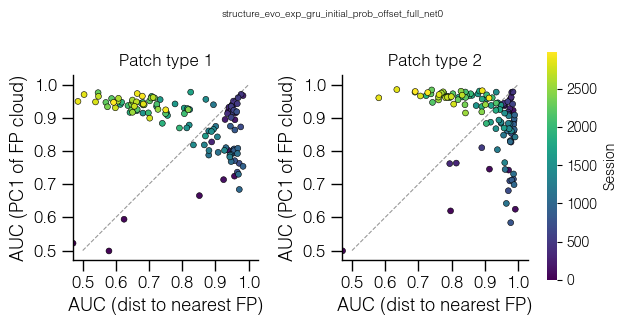


structure_evo_exp_gru_initial_prob_offset_full_net1


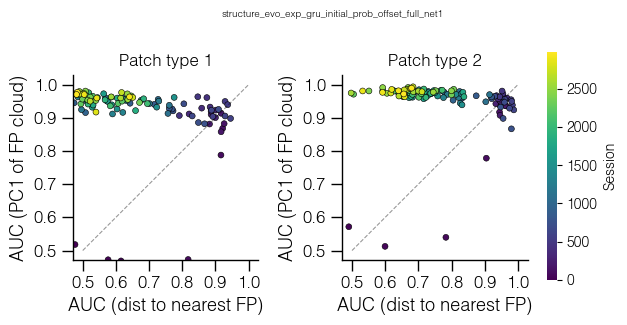


structure_evo_exp_gru_initial_prob_offset_full_net2


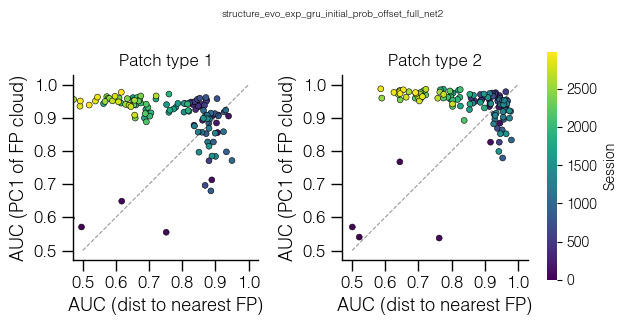


structure_evo_exp_gru_initial_prob_offset_full_net3


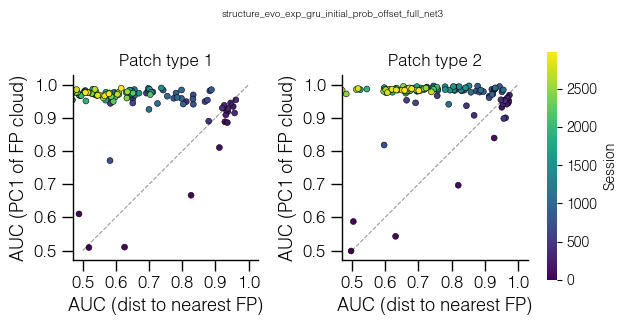


structure_evo_exp_gru_initial_prob_offset_full_net4


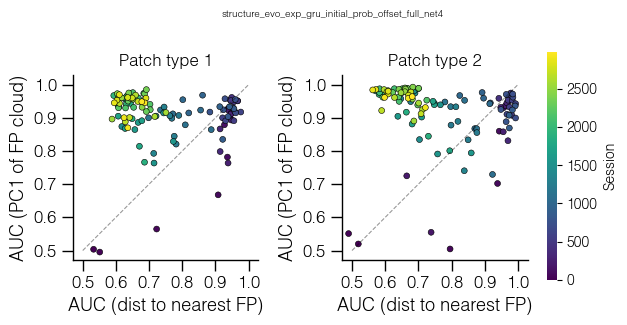

In [15]:
# Leave-one-out FP analysis for full_net0..4 (plot)
import pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

for _net_idx in range(5):
    _name    = f'structure_evo_exp_gru_initial_prob_offset_full_net{_net_idx}'
    _res_dir = Path(f'../../../results/{_name}')
    _cache   = _res_dir / 'fp_leave_predict_results.pkl'
    if not _cache.exists():
        print(f'[skip] {_name}: no cached results')
        continue
    with open(_cache, 'rb') as _f:
        _fp_lr = pickle.load(_f)

    print(f'\n{_name}')
    _all_sess_fn  = np.concatenate([_fp_lr[pt][:, 0] for pt in (1, 2) if len(_fp_lr.get(pt, [])) > 0])
    if len(_all_sess_fn) == 0:
        print('  no data')
        continue
    _norm_fn  = Normalize(vmin=_all_sess_fn.min(), vmax=_all_sess_fn.max())
    _pcmap_fn = plt.cm.viridis

    _scale = 0.65
    _fig, _axes = plt.subplots(1, 2, figsize=(10 * _scale, 5 * _scale))
    _fig.subplots_adjust(left=0.1, right=0.80, wspace=0.45)
    _fig.suptitle(_name, fontsize=7)

    for _ax, _pt in zip(_axes, (1, 2)):
        if _pt not in _fp_lr or len(_fp_lr[_pt]) == 0:
            _ax.set_visible(False)
            continue
        _r = _fp_lr[_pt]
        _ax.scatter(_r[:, 1], _r[:, 2],
                    c=_r[:, 0], cmap=_pcmap_fn, norm=_norm_fn,
                    s=18, edgecolors='k', linewidths=0.4, zorder=2)
        _ax.plot([0.5, 1], [0.5, 1], lw=0.8, ls='--', color='k', alpha=0.4)
        _ticks = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
        _ax.set_xlim(0.47, 1.03); _ax.set_ylim(0.47, 1.03)
        _ax.set_xticks(_ticks); _ax.set_yticks(_ticks)
        _ax.set_aspect('equal')
        _ax.set_xlabel('AUC (dist to nearest FP)')
        _ax.set_ylabel('AUC (PC1 of FP cloud)')
        _ax.set_title(f'Patch type {_pt}')
        format_plot(_ax)

    _cax = _fig.add_axes([0.83, 0.15, 0.015, 0.7])
    _cb  = _fig.colorbar(ScalarMappable(cmap=_pcmap_fn, norm=_norm_fn), cax=_cax, label='Session')
    _cb.outline.set_visible(False)
    plt.show()


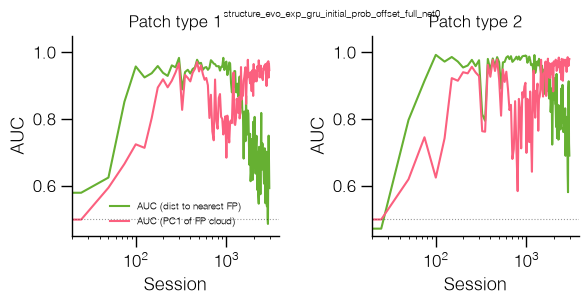

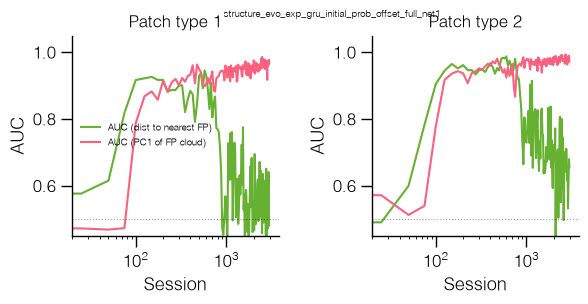

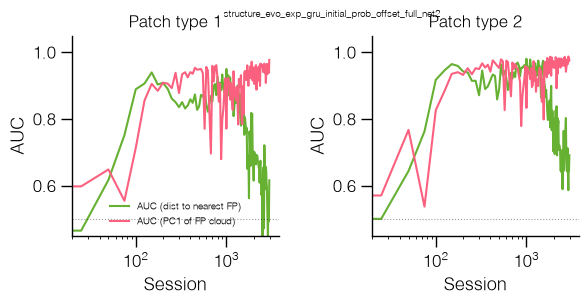

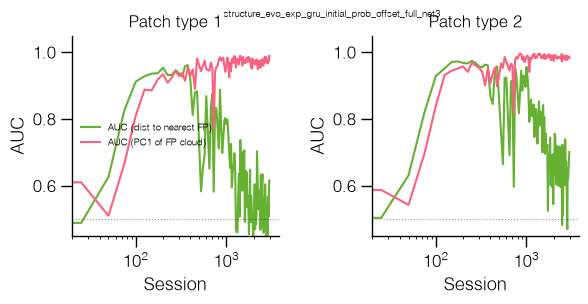

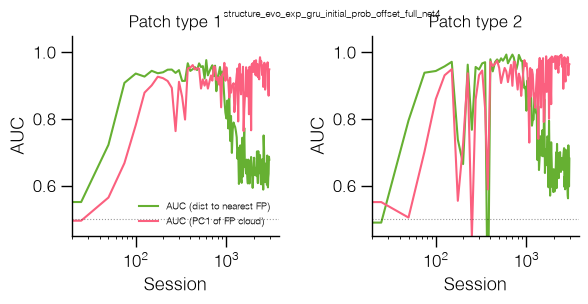

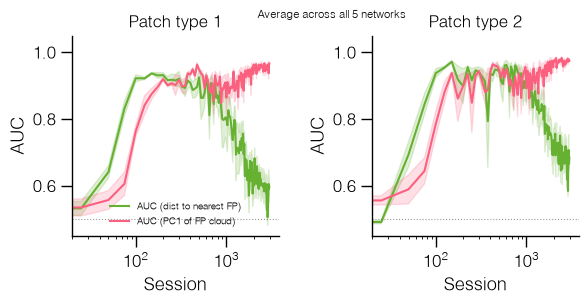

In [20]:
# ── Same data as above: each AUC metric vs session ───────────────────────────
import pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

colors = ['#66B032', '#FB607F']  # C0, C1

for _net_idx in range(5):
    _name    = f'structure_evo_exp_gru_initial_prob_offset_full_net{_net_idx}'
    _res_dir = Path(f'../../../results/{_name}')
    _cache   = _res_dir / 'fp_leave_predict_results.pkl'
    if not _cache.exists():
        print(f'[skip] {_name}: no cached results')
        continue
    with open(_cache, 'rb') as _f:
        _fp_lr = pickle.load(_f)

    _scale = 0.65
    _fig, _axes = plt.subplots(1, 2, figsize=(10 * _scale, 4 * _scale))
    _fig.subplots_adjust(left=0.1, right=0.88, wspace=0.45)
    _fig.suptitle(_name, fontsize=7)

    for _ax, _pt in zip(_axes, (1, 2)):
        if _pt not in _fp_lr or len(_fp_lr[_pt]) == 0:
            _ax.set_visible(False)
            continue
        _r    = _fp_lr[_pt]          # (N, 5): session, auc_dist, auc_pc1, perf, part_ratio
        _sess = _r[:, 0]
        _order = np.argsort(_sess)
        _s    = _sess[_order]
        _auc_dist = _r[_order, 1]
        _auc_pc1  = _r[_order, 2]

        _ax.plot(_s, _auc_dist, lw=1.5, color=colors[0], label='AUC (dist to nearest FP)')
        # _ax.scatter(_s, _auc_dist, s=12, color=colors[0], edgecolors='k', linewidths=0.3, zorder=3)
        _ax.plot(_s, _auc_pc1,  lw=1.5, color=colors[1], label='AUC (PC1 of FP cloud)')
        # _ax.scatter(_s, _auc_pc1,  s=12, color=colors[1], edgecolors='k', linewidths=0.3, zorder=3, marker='s')

        _ax.axhline(0.5, lw=0.8, ls=':', color='k', alpha=0.4)
        _ax.set_ylim(0.45, 1.05)
        _ax.set_xlabel('Session')
        _ax.set_ylabel('AUC')
        _ax.set_title(f'Patch type {_pt}')
        if _pt == 1:
            _ax.legend(fontsize=7, frameon=False)
        format_plot(_ax)
        _ax.set_xscale('log')

    os.makedirs('../../../figures', exist_ok=True)
    _fig.savefig(f'../../../figures/auc_vs_session_net{_net_idx}.svg', format='svg')
    plt.show()

# ── Averaged across all 5 networks (nanmean ± SEM) ───────────────────────────
_all_sessions = sorted(set(
    int(s)
    for _ni in range(5)
    for _name in [f'structure_evo_exp_gru_initial_prob_offset_full_net{_ni}']
    for _cache in [Path(f'../../../results/{_name}/fp_leave_predict_results.pkl')]
    if _cache.exists()
    for _fp_lr in [pickle.load(open(_cache, 'rb'))]
    for _pt in (1, 2)
    if _pt in _fp_lr and len(_fp_lr[_pt]) > 0
    for s in _fp_lr[_pt][:, 0]
))
_sess_arr = np.array(_all_sessions)

_scale = 0.65
_fig_avg, _axes_avg = plt.subplots(1, 2, figsize=(10 * _scale, 4 * _scale))
_fig_avg.subplots_adjust(left=0.1, right=0.88, wspace=0.45)
_fig_avg.suptitle('Average across all 5 networks', fontsize=8)

for _ax, _pt in zip(_axes_avg, (1, 2)):
    _dist_mat = np.full((5, len(_sess_arr)), np.nan)
    _pc1_mat  = np.full((5, len(_sess_arr)), np.nan)

    for _ni in range(5):
        _name  = f'structure_evo_exp_gru_initial_prob_offset_full_net{_ni}'
        _cache = Path(f'../../../results/{_name}/fp_leave_predict_results.pkl')
        if not _cache.exists():
            continue
        with open(_cache, 'rb') as _f:
            _fp_lr = pickle.load(_f)
        if _pt not in _fp_lr or len(_fp_lr[_pt]) == 0:
            continue
        _r = _fp_lr[_pt]
        for _row in _r:
            _j = np.searchsorted(_sess_arr, int(_row[0]))
            if _j < len(_sess_arr) and _sess_arr[_j] == int(_row[0]):
                _dist_mat[_ni, _j] = _row[1]
                _pc1_mat[_ni, _j]  = _row[2]

    for _mat, _color, _ls, _marker, _label in [
        (_dist_mat, colors[0], '-',  'o', 'AUC (dist to nearest FP)'),
        (_pc1_mat,  colors[1], '-', 's', 'AUC (PC1 of FP cloud)'),
    ]:
        _n   = np.sum(np.isfinite(_mat), axis=0).clip(1, None)
        _mu  = np.nanmean(_mat, axis=0)
        _sem = np.nanstd(_mat, axis=0) / np.sqrt(_n)
        _mask = _n > 0
        _ax.fill_between(_sess_arr[_mask], (_mu - _sem)[_mask], (_mu + _sem)[_mask],
                         color=_color, alpha=0.2)
        _ax.plot(_sess_arr[_mask], _mu[_mask], lw=1.5, color=_color, ls=_ls, label=_label)
        # _ax.scatter(_sess_arr[_mask], _mu[_mask], s=12, color=_color,
        #             edgecolors='k', linewidths=0.3, zorder=3, marker=_marker)

    _ax.axhline(0.5, lw=0.8, ls=':', color='k', alpha=0.4)
    _ax.set_ylim(0.45, 1.05)
    _ax.set_xlabel('Session')
    _ax.set_ylabel('AUC')
    _ax.set_title(f'Patch type {_pt}')
    if _pt == 1:
        _ax.legend(fontsize=7, frameon=False)
    _ax.set_xscale('log')
    format_plot(_ax)

os.makedirs('../../../figures', exist_ok=True)
_fig_avg.savefig('../../../figures/auc_vs_session_average.svg', format='svg')
plt.show()


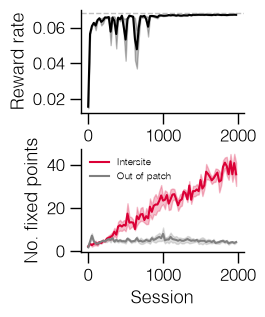

In [21]:
import numpy as np
import matplotlib.pyplot as plt

colors = ['#db0036', 'grey']

# ── Align all 5 networks onto a common session grid ──────────────────────────
_all_sess = set()
for _d in _full_net_fp_evos.values():
    _all_sess.update(_d['sessions'].tolist())
_common_sess = np.array(sorted(_all_sess))

def _align(sessions, values, common):
    m = dict(zip(sessions.tolist(), np.asarray(values).tolist()))
    return np.array([m.get(s, np.nan) for s in common])

_net_keys = sorted(_full_net_fp_evos.keys())
_n_nets   = len(_net_keys)

# Performance: (n_nets, n_sessions)
_perf_mat = np.array([
    _align(_full_net_fp_evos[k]['sessions'],
           _full_net_fp_evos[k]['performance'], _common_sess)
    for k in _net_keys
])

# Fixed-point counts: [inp_idx] -> (n_nets, n_sessions)
_n_inputs  = len(_full_net_fp_evos[_net_keys[0]]['counts'])
_fp_mats   = [
    np.array([
        _align(_full_net_fp_evos[k]['sessions'],
               np.array(_full_net_fp_evos[k]['counts'][i], dtype=float),
               _common_sess)
        for k in _net_keys
    ])
    for i in range(_n_inputs)
]
_inp_labels = [
    'Intersite',
    'Out of patch',
]

def _mean_sem(mat):
    n   = np.sum(np.isfinite(mat), axis=0).clip(1, None)
    mu  = np.nanmean(mat, axis=0)
    sem = np.nanstd(mat, axis=0) / np.sqrt(n)
    return mu, sem

# ── Plot ──────────────────────────────────────────────────────────────────────
_scale = 0.7
_fig, _axes = plt.subplots(2, 1, figsize=(3 * _scale, 4.5 * _scale), sharex=True)
_fig.subplots_adjust(hspace=0.35)

# Row 0: performance
_ax = _axes[0]
_mu_p, _sem_p = _mean_sem(_perf_mat)
_ax.fill_between(_common_sess, _mu_p - _sem_p, _mu_p + _sem_p,
                  color='black', alpha=0.25)
_ax.plot(_common_sess, _mu_p, color='black', lw=1.5)
_ax.axhline(0.068, color='grey', ls='--', lw=1, alpha=0.5)
_ax.set_ylabel('Reward rate')
format_plot(_ax)

# Row 1: fixed-point counts for both inputs
_ax = _axes[1]
for _i in range(_n_inputs):
    _mu_fp, _sem_fp = _mean_sem(_fp_mats[_i])
    _ax.fill_between(_common_sess, _mu_fp - _sem_fp, _mu_fp + _sem_fp,
                      color=colors[_i], alpha=0.25)
    _ax.plot(_common_sess, _mu_fp, color=colors[_i], lw=1.5, label=_inp_labels[_i])
_ax.set_xlabel('Session')
_ax.set_ylabel('No. fixed points')
_ax.legend(fontsize=7, frameon=False)
format_plot(_ax)

os.makedirs('../../../figures', exist_ok=True)
_fig.savefig('../../../figures/reward_rate_and_fixed_points.svg', format='svg')
plt.show()


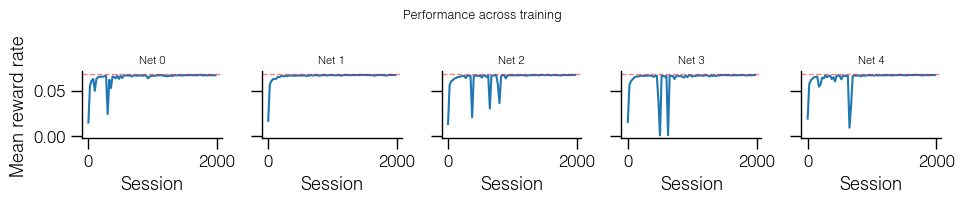

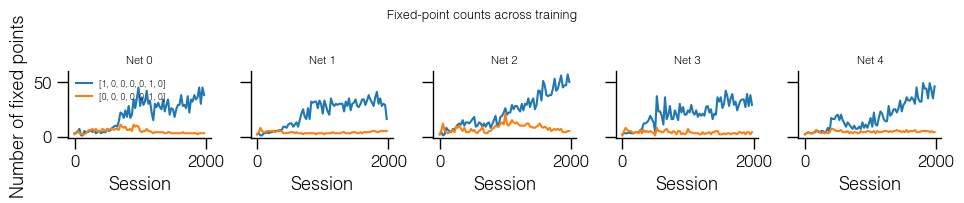

In [11]:
# ── Same as above but each network in its own subplot ────────────────────────
import numpy as np
import matplotlib.pyplot as plt

_net_keys = sorted(_full_net_fp_evos.keys())
_n_nets   = len(_net_keys)

# Performance: (n_nets, n_sessions)
_perf_mat2 = np.array([
    _align(_full_net_fp_evos[k]['sessions'],
           _full_net_fp_evos[k]['performance'], _common_sess)
    for k in _net_keys
])

_fp_mats2 = [
    np.array([
        _align(_full_net_fp_evos[k]['sessions'],
               np.array(_full_net_fp_evos[k]['counts'][i], dtype=float),
               _common_sess)
        for k in _net_keys
    ])
    for i in range(_n_inputs)
]

# ── Performance: one subplot per network ─────────────────────────────────────
_scale = 0.65
_fig, _axes = plt.subplots(1, _n_nets, figsize=(3 * _n_nets * _scale, 3 * _scale),
                            sharey=True, sharex=True)
_fig.subplots_adjust(wspace=0.15)
for _j, (_ax, _k) in enumerate(zip(_axes, _net_keys)):
    _perf = _perf_mat2[_j]
    _ax.plot(_common_sess, _perf, color='C0', lw=1.5)
    _ax.axhline(0.068, color='red', ls='--', lw=1, alpha=0.5)
    _ax.set_title(f'Net {_k}', fontsize=8)
    _ax.set_xlabel('Session')
    if _j == 0:
        _ax.set_ylabel('Mean reward rate')
    format_plot(_ax)
_fig.suptitle('Performance across training', fontsize=9, y=1.02)
_fig.tight_layout()
plt.show()

# ── Fixed-point counts: one subplot per network ───────────────────────────────
_fig2, _axes2 = plt.subplots(1, _n_nets, figsize=(3 * _n_nets * _scale, 3 * _scale),
                              sharey=True, sharex=True)
_fig2.subplots_adjust(wspace=0.15)
for _j, (_ax, _k) in enumerate(zip(_axes2, _net_keys)):
    for _i in range(_n_inputs):
        _fp = _fp_mats2[_i][_j]
        _ax.plot(_common_sess, _fp, color=f'C{_i}', lw=1.5,
                 label=_inp_labels[_i] if _j == 0 else None)
    _ax.set_title(f'Net {_k}', fontsize=8)
    _ax.set_xlabel('Session')
    if _j == 0:
        _ax.set_ylabel('Number of fixed points')
        _ax.legend(fontsize=6, frameon=False)
    format_plot(_ax)
_fig2.suptitle('Fixed-point counts across training', fontsize=9, y=1.02)
_fig2.tight_layout()
plt.show()


Net 0: patch1=672 segs, patch2=1557 segs
Net 1: patch1=695 segs, patch2=1540 segs
Net 2: patch1=672 segs, patch2=1543 segs
Net 3: patch1=808 segs, patch2=1358 segs
Net 4: patch1=808 segs, patch2=1398 segs


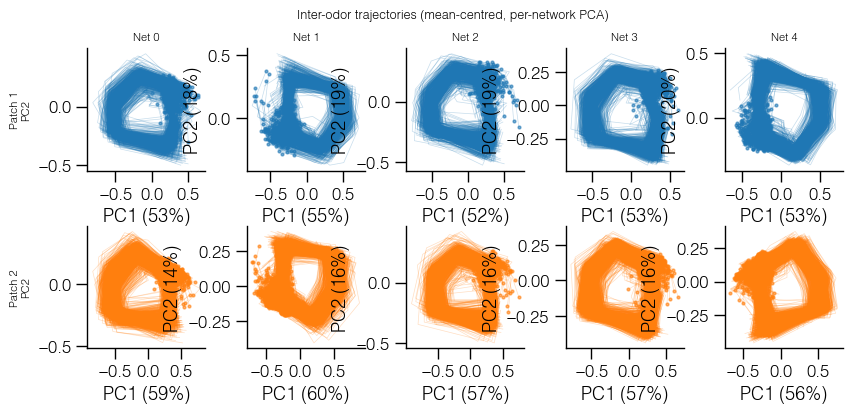

In [24]:
# ── Inter-odor trajectories: each network in its own PC space ────────────────
import re
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA

_SPE = 20000

# Collect segments per network per patch type
_net_patch_segs = {}   # net_idx -> {1: [...], 2: [...]}
_net_traj_pca   = {}   # (net_idx, patch_type) -> fitted PCA

for _ni in range(5):
    _name    = f'structure_evo_exp_gru_initial_prob_offset_full_net{_ni}'
    _res_dir = Path(f'../../../results/{_name}')

    _traj_files = sorted(
        _res_dir.rglob('traj_*.pkl'),
        key=lambda p: int(re.search(r'traj_(\d+)\.pkl', p.name).group(1)),
    )
    if not _traj_files:
        print(f'[skip] net {_ni}')
        continue

    _td      = parse_behavioral_data(load_trajectory_data(str(_traj_files[-1]))[0])
    _ne      = max(1, _td['actor_hidden'].shape[0] // _SPE)
    _hidden  = _td['actor_hidden'].reshape(_ne, _SPE, -1).transpose(1, 0, 2)
    _rsi     = _td['reward_site_idx'].reshape(_ne, _SPE).T
    _pnums   = _td['current_patch_num'].reshape(_ne, _SPE, -1).transpose(1, 0, 2)[:, :, 0]
    _ip      = (_td['agent_in_patch'].reshape(_ne, _SPE).T > 0)
    T, n_trials, H = _hidden.shape

    _segs = {1: [], 2: []}
    for _tr in range(n_trials):
        _rsi_tr  = _rsi[:, _tr]
        _pnum_tr = _pnums[:, _tr]
        _ip_tr   = _ip[:, _tr]
        _onsets  = (np.where(np.diff(_rsi_tr) > 0)[0] + 1).tolist()
        for _k in range(len(_onsets) - 1):
            _t0, _t1 = _onsets[_k], _onsets[_k + 1]
            _pt = int(_pnum_tr[_t0])
            if _pt not in (1, 2):
                continue
            if _pnum_tr[_t1] != _pt or not np.all(_ip_tr[_t0:_t1]):
                continue
            _seg = _hidden[_t0:_t1, _tr]
            if len(_seg) >= 2:
                _segs[_pt].append(_seg)
    _net_patch_segs[_ni] = _segs
    print(f'Net {_ni}: patch1={len(_segs[1])} segs, patch2={len(_segs[2])} segs')

# ── Plot: 2 rows (patch type) × 5 cols (network) ─────────────────────────────
_scale = 0.65
_fig, _axes = plt.subplots(2, 5, figsize=(3 * 5 * _scale, 3 * 2 * _scale),
                            sharex=False, sharey=False)
_fig.subplots_adjust(hspace=0.45, wspace=0.35)

for _row, _pt in enumerate([1, 2]):
    for _col, _ni in enumerate(range(5)):
        _ax   = _axes[_row, _col]
        _segs = _net_patch_segs.get(_ni, {}).get(_pt, [])
        if not _segs:
            _ax.set_visible(False)
            continue

        # Subtract per-segment mean before pooling
        _segs_c = [_seg - _seg.mean(axis=0) for _seg in _segs]
        _all_h  = np.concatenate(_segs_c, axis=0)
        _pca2   = PCA(n_components=2)
        _pca2.fit(_all_h)
        _net_traj_pca[(_ni, _pt)] = _pca2

        for _seg_c in _segs_c:
            _proj = _seg_c @ _pca2.components_.T
            _ax.plot(_proj[:, 0], _proj[:, 1], color=f'C{_pt - 1}',
                     lw=0.5, alpha=0.25)
            _ax.plot(_proj[0, 0], _proj[0, 1], 'o', ms=2,
                     color=f'C{_pt - 1}', alpha=0.6, zorder=3)

        _ev = _pca2.explained_variance_ratio_
        _ax.set_xlabel(f'PC1 ({_ev[0]*100:.0f}%)', fontsize=7)
        _ax.set_ylabel(f'PC2 ({_ev[1]*100:.0f}%)', fontsize=7)
        if _row == 0:
            _ax.set_title(f'Net {_ni}', fontsize=8)
        format_plot(_ax)

for _row, _pt in enumerate([1, 2]):
    _axes[_row, 0].set_ylabel(f'Patch {_pt}\nPC2', fontsize=8)

_fig.suptitle('Inter-odor trajectories (mean-centred, per-network PCA)', fontsize=9)
plt.show()


Net 0: 36 unique FPs
  patch 1: alignment = 0.566
  patch 2: alignment = 0.275


Net 1: 38 unique FPs
  patch 1: alignment = 0.600
  patch 2: alignment = 0.401


Net 2: 68 unique FPs
  patch 1: alignment = 0.609
  patch 2: alignment = 0.384


Net 3: 47 unique FPs
  patch 1: alignment = 0.583
  patch 2: alignment = 0.435


Net 4: 60 unique FPs
  patch 1: alignment = 0.620
  patch 2: alignment = 0.423


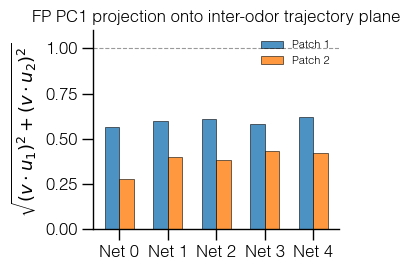

In [25]:
# ── Alignment: FP PC1 projected onto inter-odor trajectory plane ─────────────
# For each network and patch type, find fixed points for [1,0,0,0,0,1,0],
# compute their first PC, then measure how much it lies in the trajectory
# PC1-PC2 plane:  alignment = sqrt( (v·u1)^2 + (v·u2)^2 )  for unit v, u1, u2.
import re
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA

_TARGET_INPUT = jnp.array([1., 0., 0., 0., 0., 1., 0.])
_FP_ATTEMPTS  = 400
_FP_TOL       = 1e-3
_FP_UNIQUE    = 0.1
_SPE          = 20000

_alignments = {}   # (net_idx, patch_type) -> alignment scalar

for _ni in range(5):
    _name     = f'structure_evo_exp_gru_initial_prob_offset_full_net{_ni}'
    _res_dir  = Path(f'../../../results/{_name}')
    _ckpt_dir = Path(f'../../../checkpoints/{_name}')

    # Final checkpoint
    _traj_files = sorted(
        _res_dir.rglob('traj_*.pkl'),
        key=lambda p: int(re.search(r'traj_(\d+)\.pkl', p.name).group(1)),
    )
    if not _traj_files:
        continue
    _traj_path = _traj_files[-1]
    _sess      = int(re.search(r'traj_(\d+)\.pkl', _traj_path.name).group(1))
    _step_dir  = _traj_path.parent.name
    _ckpt_path = _ckpt_dir / _step_dir / f'checkpoint_{_sess}'
    if not _ckpt_path.exists():
        print(f'Net {_ni}: checkpoint not found')
        continue

    _traj_raw  = load_trajectory_data(str(_traj_path))
    _td        = parse_behavioral_data(_traj_raw[0])
    _restored  = checkpoints.restore_checkpoint(ckpt_dir=_ckpt_path.resolve(), target=train_state)
    _net_params = _restored.params

    # Seed FP search from recorded hidden states
    _h_all   = jnp.array(_td['actor_hidden'])
    _rng     = jax.random.PRNGKey(42)
    _idx     = jax.random.randint(_rng, (_FP_ATTEMPTS,), 0, _h_all.shape[0])
    _h_inits = _h_all[_idx]

    _fps, _conv, _ = find_fixed_points_batch(
        params=_net_params, network=network,
        input_vec=_TARGET_INPUT, h_inits=_h_inits,
        max_steps=10000, learning_rate=0.001,
        tolerance=_FP_TOL, verbose=False,
    )
    _ufps = filter_unique_fixed_points(_fps, _conv, uniqueness_threshold=_FP_UNIQUE)
    print(f'Net {_ni}: {len(_ufps)} unique FPs')

    if len(_ufps) < 2:
        print(f'  [skip] fewer than 2 FPs — cannot compute PC')
        continue

    # First PC of FP cloud (unit vector in hidden-state space)
    _fp_arr  = np.array(_ufps)   # (n_fps, H)
    _fp_pca  = PCA(n_components=1)
    _fp_pca.fit(_fp_arr - _fp_arr.mean(axis=0))
    _v       = _fp_pca.components_[0]           # (H,) already unit norm
    _v      /= np.linalg.norm(_v)               # ensure unit

    # Alignment with trajectory plane for each patch type
    for _pt in [1, 2]:
        _key = (_ni, _pt)
        if _key not in _net_traj_pca:
            continue
        _u1 = _net_traj_pca[_key].components_[0]
        _u2 = _net_traj_pca[_key].components_[1]
        _u1 /= np.linalg.norm(_u1)
        _u2 /= np.linalg.norm(_u2)
        _d1 = float(_v @ _u1)
        _d2 = float(_v @ _u2)
        _alignments[_key] = np.sqrt(_d1**2 + _d2**2)
        print(f'  patch {_pt}: alignment = {_alignments[_key]:.3f}')

# ── Plot ──────────────────────────────────────────────────────────────────────
_scale = 0.7
_fig, _ax = plt.subplots(figsize=(5 * _scale, 4 * _scale))

_x      = np.arange(5)
_width  = 0.3
for _offset, _pt, _label in [(-_width/2, 1, 'Patch 1'), (_width/2, 2, 'Patch 2')]:
    _vals = [_alignments.get((_ni, _pt), np.nan) for _ni in range(5)]
    _ax.bar(_x + _offset, _vals, _width, label=_label,
            color=f'C{_pt - 1}', alpha=0.8, edgecolor='k', linewidth=0.5)

_ax.axhline(1.0, ls='--', lw=0.8, color='k', alpha=0.4)
_ax.set_xticks(_x)
_ax.set_xticklabels([f'Net {i}' for i in range(5)])
_ax.set_ylabel(r'$\sqrt{(v \cdot u_1)^2 + (v \cdot u_2)^2}$')
_ax.set_ylim(0, 1.1)
_ax.set_title('FP PC1 projection onto inter-odor trajectory plane')
_ax.legend(fontsize=8, frameon=False)
format_plot(_ax)
_fig.tight_layout()
plt.show()


Loaded cache: 135 entries
Saved cache (135 entries)
Saved cache (135 entries)
Saved cache (135 entries)
Saved cache (135 entries)
Saved cache (135 entries)


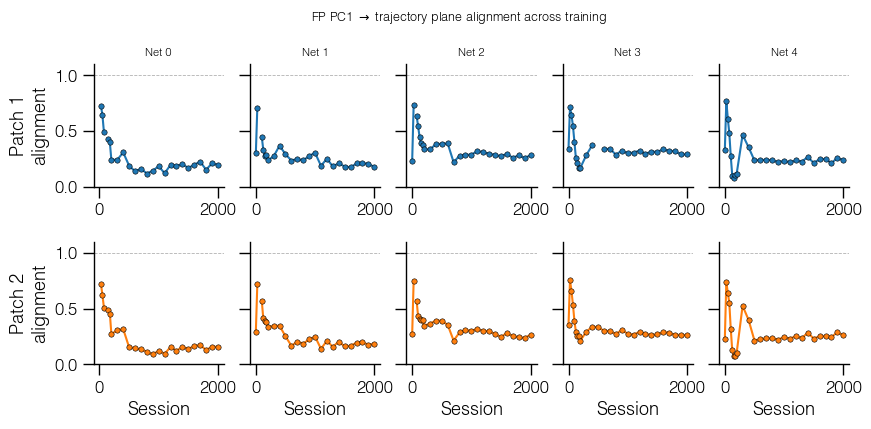

/tmp/ipykernel_3849374/2030352783.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Light.
  _fig2.tight_layout()
/home/david.bell/anaconda3/envs/favorably_connected/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Light.
  fig.canvas.print_figure(bytes_io, **kw)


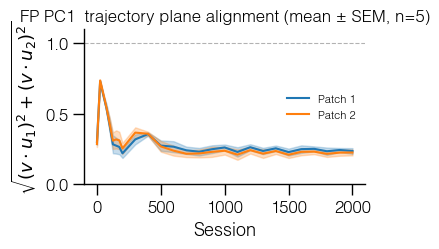

In [29]:
# ── FP PC1 / trajectory-plane alignment across training (every 100 sessions) ─
import re, pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA

_TARGET_INPUT  = jnp.array([1., 0., 0., 0., 0., 1., 0.])
_FP_ATTEMPTS   = 400
_FP_TOL        = 1e-3
_FP_UNIQUE     = 0.1
_SPE           = 20000
_TARGET_SESS   = np.concatenate([
    np.arange(0, 200, 25),
    np.arange(200, 2001, 100),
])
_CACHE_PATH    = Path('../../../results/fp_traj_plane_alignment_across_training_first3.pkl')


def _compute_alignment(td, net_params, target_input, h_inits):
    """Returns (alignment_patch1, alignment_patch2, n_fps) for one checkpoint."""
    # ── Fixed-point PC1 ──────────────────────────────────────────────────────
    fps, conv, _ = find_fixed_points_batch(
        params=net_params, network=network,
        input_vec=target_input, h_inits=h_inits,
        max_steps=10000, learning_rate=0.001,
        tolerance=_FP_TOL, verbose=False,
    )
    ufps = filter_unique_fixed_points(fps, conv, uniqueness_threshold=_FP_UNIQUE)
    if len(ufps) < 2:
        return {1: np.nan, 2: np.nan}, len(ufps)

    fp_arr = np.array(ufps)
    fp_pca = PCA(n_components=1)
    fp_pca.fit(fp_arr - fp_arr.mean(axis=0))
    v = fp_pca.components_[0]
    v = v / np.linalg.norm(v)

    # ── Trajectory plane PCA (per patch type) ────────────────────────────────
    ne      = max(1, td['actor_hidden'].shape[0] // _SPE)
    hidden  = td['actor_hidden'].reshape(ne, _SPE, -1).transpose(1, 0, 2)
    rsi     = td['reward_site_idx'].reshape(ne, _SPE).T
    pnums   = td['current_patch_num'].reshape(ne, _SPE, -1).transpose(1, 0, 2)[:, :, 0]
    ip      = (td['agent_in_patch'].reshape(ne, _SPE).T > 0)
    T, n_trials, H = hidden.shape

    segs = {1: [], 2: []}
    for tr in range(n_trials):
        rsi_tr  = rsi[:, tr]
        pnum_tr = pnums[:, tr]
        ip_tr   = ip[:, tr]
        onsets  = (np.where(np.diff(rsi_tr) > 0)[0] + 1).tolist()
        for k in range(len(onsets) - 1):
            t0, t1 = onsets[k], onsets[k + 1]
            pt = int(pnum_tr[t0])
            if pt not in (1, 2): continue
            if pnum_tr[t1] != pt or not np.all(ip_tr[t0:t1]): continue
            seg = hidden[t0:min(t0+3, t1), tr]   # first 3 timesteps only
            if len(seg) >= 2:
                segs[pt].append(seg - seg.mean(axis=0))

    aligns = {}
    for pt in [1, 2]:
        if len(segs[pt]) < 2:
            aligns[pt] = np.nan
            continue
        all_h = np.concatenate(segs[pt], axis=0)
        tpca  = PCA(n_components=2).fit(all_h)
        u1 = tpca.components_[0] / np.linalg.norm(tpca.components_[0])
        u2 = tpca.components_[1] / np.linalg.norm(tpca.components_[1])
        aligns[pt] = float(np.sqrt((v @ u1)**2 + (v @ u2)**2))

    return aligns, len(ufps)


# ── Main loop (load cache if available) ──────────────────────────────────────
if _CACHE_PATH.exists():
    with open(_CACHE_PATH, 'rb') as _f:
        _results = pickle.load(_f)
    print(f'Loaded cache: {len(_results)} entries')
else:
    _results = {}

for _ni in range(5):
    _name     = f'structure_evo_exp_gru_initial_prob_offset_full_net{_ni}'
    _res_dir  = Path(f'../../../results/{_name}')
    _ckpt_dir = Path(f'../../../checkpoints/{_name}')

    for _sess in _TARGET_SESS:
        _key = (_ni, int(_sess))
        if _key in _results:
            continue   # already computed

        _traj_path = _res_dir / 'step_00' / f'traj_{_sess:06d}.pkl'
        _ckpt_path = _ckpt_dir / 'step_00' / f'checkpoint_{_sess}'
        if not _traj_path.exists() or not _ckpt_path.exists():
            print(f'[skip] net {_ni} sess {_sess}: missing file')
            continue

        print(f'Net {_ni} sess {_sess}...', end=' ', flush=True)
        _td        = parse_behavioral_data(load_trajectory_data(str(_traj_path))[0])
        _restored  = checkpoints.restore_checkpoint(ckpt_dir=_ckpt_path.resolve(), target=train_state)
        _net_params = _restored.params

        _rng    = jax.random.PRNGKey(_sess + _ni * 10000)
        _h_all  = jnp.array(_td['actor_hidden'])
        _idx    = jax.random.randint(_rng, (_FP_ATTEMPTS,), 0, _h_all.shape[0])
        _hinits = _h_all[_idx]

        _aligns, _nfps = _compute_alignment(_td, _net_params, _TARGET_INPUT, _hinits)
        _results[_key] = {'aligns': _aligns, 'n_fps': _nfps}
        print(f'n_fps={_nfps}, p1={_aligns[1]:.3f}, p2={_aligns[2]:.3f}')

    # Save after each network
    with open(_CACHE_PATH, 'wb') as _f:
        pickle.dump(_results, _f)
    print(f'Saved cache ({len(_results)} entries)')

# ── Plot: 2 rows × 5 cols ─────────────────────────────────────────────────────
_scale = 0.65
_fig, _axes = plt.subplots(2, 5, figsize=(3*5*_scale, 3*2*_scale),
                            sharey=True, sharex=True)
_fig.subplots_adjust(hspace=0.45, wspace=0.2)

for _row, _pt in enumerate([1, 2]):
    for _col, _ni in enumerate(range(5)):
        _ax    = _axes[_row, _col]
        _sess_vals = sorted(s for (n, s) in _results if n == _ni)
        _ys    = [_results[(_ni, s)]['aligns'][_pt] for s in _sess_vals]
        _ax.plot(_sess_vals, _ys, color=f'C{_pt-1}', lw=1.5)
        _ax.scatter(_sess_vals, _ys, s=15, color=f'C{_pt-1}',
                    edgecolors='k', linewidths=0.4, zorder=3)
        _ax.axhline(1.0, ls='--', lw=0.6, color='k', alpha=0.3)
        _ax.set_ylim(0, 1.1)
        if _row == 0: _ax.set_title(f'Net {_ni}', fontsize=8)
        if _col == 0: _ax.set_ylabel(f'Patch {_pt}\nalignment', fontsize=8)
        if _row == 1: _ax.set_xlabel('Session', fontsize=7)
        format_plot(_ax)

_fig.suptitle(r'FP PC1 $\rightarrow$ trajectory plane alignment across training',
              fontsize=9, y=1.02)
plt.show()


# ── Averaged across networks (nanmean ± SEM) ─────────────────────────────────
_sess_sorted = np.array(sorted(set(s for (_, s) in _results)))

_fig2, _ax2 = plt.subplots(figsize=(6 * _scale, 4 * _scale))

for _pt in [1, 2]:
    _mat = np.array([
        [_results.get((_ni, int(_s)), {'aligns': {_pt: np.nan}})['aligns'][_pt]
         for _s in _sess_sorted]
        for _ni in range(5)
    ])  # (5, n_sessions)
    _mu  = np.nanmean(_mat, axis=0)
    _n   = np.sum(np.isfinite(_mat), axis=0).clip(1, None)
    _sem = np.nanstd(_mat, axis=0) / np.sqrt(_n)
    _ax2.fill_between(_sess_sorted, _mu - _sem, _mu + _sem,
                      color=f'C{_pt-1}', alpha=0.25)
    _ax2.plot(_sess_sorted, _mu, color=f'C{_pt-1}', lw=1.5, label=f'Patch {_pt}')

_ax2.axhline(1.0, ls='--', lw=0.8, color='k', alpha=0.3)
_ax2.set_ylim(0, 1.1)
_ax2.set_xlabel('Session')
_ax2.set_ylabel(r'$\sqrt{(v\cdot u_1)^2+(v\cdot u_2)^2}$')
_ax2.set_title('FP PC1 → trajectory plane alignment (mean ± SEM, n=5)')
_ax2.legend(fontsize=8, frameon=False)
format_plot(_ax2)
_fig2.tight_layout()
plt.show()


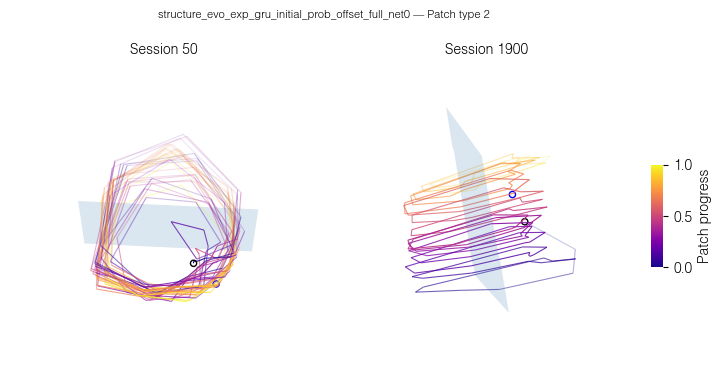

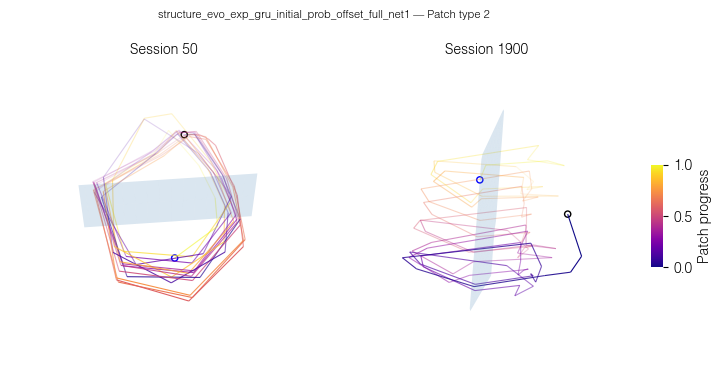

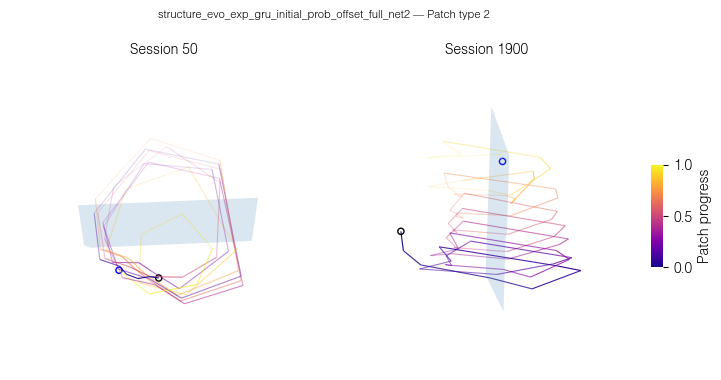

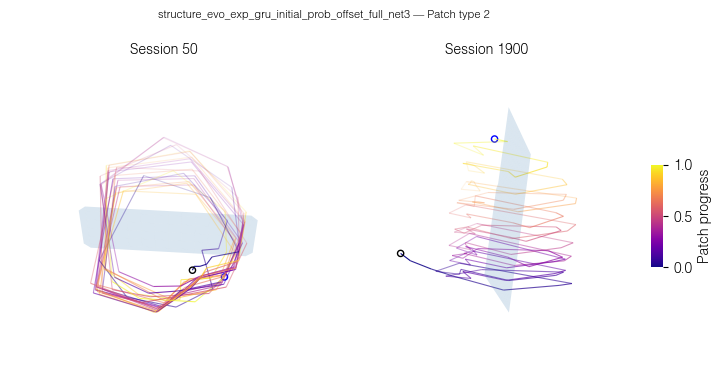

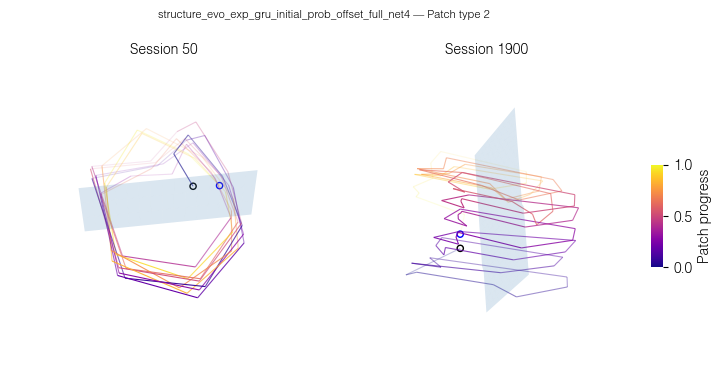

In [44]:
# ── Patch type 2 trajectory at sessions 100 & 1900, colored by patch_progress ─
import re
from nb_dynamics_plotting import _depth_alpha_lc3d, patch_progress, collect_pre_odor_time_to_exit

_SESSIONS_TO_PLOT = [50, 1900]
_PATCH_TYPE   = 2
_PATCH_IDX    = 2
_TRIAL_IDX    = 0
_THRESHOLD    = 0.5
_N_STEPS      = 20000
_AZIM         = 180
_ELEV         = -110
_LW           = 0.8
_traj_cmap    = sns.color_palette('plasma', as_cmap=True)

for _ni in range(5):
    _name     = f'structure_evo_exp_gru_initial_prob_offset_full_net{_ni}'
    _res_dir  = Path(f'../../../results/{_name}')
    _ckpt_dir = Path(f'../../../checkpoints/{_name}')

    _sess_recs = {}
    for _sess in _SESSIONS_TO_PLOT:
        _tp = _res_dir  / 'step_00' / f'traj_{_sess:06d}.pkl'
        _cp = _ckpt_dir / 'step_00' / f'checkpoint_{_sess}'
        if not _tp.exists() or not _cp.exists():
            print(f'[skip] net {_ni} sess {_sess}')
            continue

        _td        = parse_behavioral_data(load_trajectory_data(str(_tp))[0])
        _restored  = checkpoints.restore_checkpoint(ckpt_dir=_cp.resolve(), target=train_state)
        _net_p     = _restored.params

        # Per-session PCA
        _pca_s = PCA(n_components=3)
        _pca_s.fit(_td['actor_hidden'])

        # tte_data for patch type 2
        _tte_p2 = collect_pre_odor_time_to_exit(_td, patch_num=2)

        # Find a patch type 2 visit
        _ne       = max(1, _td['actor_hidden'].shape[0] // _N_STEPS)
        _obs_all  = _td['observations'].reshape(_ne, _N_STEPS, -1)[_TRIAL_IDX]
        _hid_all  = _td['actor_hidden'].reshape(_ne, _N_STEPS, -1)[_TRIAL_IDX]
        _pnum_all = _td['current_patch_num'].reshape(_ne, _N_STEPS)[_TRIAL_IDX]

        _padded = np.concatenate([[False], _obs_all[:, 0] > _THRESHOLD, [False]])
        _diff   = np.diff(_padded.astype(int))
        _starts = np.where(_diff ==  1)[0]
        _stops  = np.where(_diff == -1)[0]
        _mask   = np.array([_pnum_all[s] == _PATCH_TYPE for s in _starts])
        _pss, _pes = _starts[_mask], _stops[_mask]

        if _PATCH_IDX >= len(_pss):
            print(f'net {_ni} sess {_sess}: only {len(_pss)} type-{_PATCH_TYPE} patches')
            continue

        _p0, _p1 = _pss[_PATCH_IDX], _pes[_PATCH_IDX]
        _h       = _hid_all[max(0, _p0-1):_p1]
        _pp_3d   = _pca_s.transform(_h)[:, :3]

        _n_nbrs = min(10, max(1, len(_tte_p2['time_to_exit'])))
        _pp_val = (patch_progress(_h, _tte_p2, n_neighbors=_n_nbrs).astype(float)
                   if len(_tte_p2['time_to_exit']) >= 5
                   else np.linspace(0, 1, len(_h)))

        _sess_recs[_sess] = ('_pp_3d', _pp_3d, _pp_val, _net_p, _pca_s)

    _avail = [s for s in _SESSIONS_TO_PLOT if s in _sess_recs]
    if len(_avail) < 1:
        continue

    _all_pp = np.concatenate([_sess_recs[s][2] for s in _avail])
    _gnorm  = Normalize(vmin=float(np.nanmin(_all_pp)), vmax=float(np.nanmax(_all_pp)))

    _fig = plt.figure(figsize=(4 * len(_avail) + 0.5, 4))
    _gs  = _fig.add_gridspec(1, len(_avail) + 1,
                              width_ratios=[1] * len(_avail) + [0.04], wspace=0.02)
    _ax_list = [_fig.add_subplot(_gs[0, i], projection='3d') for i in range(len(_avail))]
    _ax_cb   = _fig.add_subplot(_gs[0, len(_avail)])
    _active  = []

    for _ax, _sess in zip(_ax_list, _avail):
        _, _pp_3d, _pp_val, _net_p, _pca_s = _sess_recs[_sess]
        _active.append((_ax, _net_p, _pca_s))

        _segs   = np.concatenate([_pp_3d[:-1, None, :], _pp_3d[1:, None, :]], axis=1)
        _colors = _traj_cmap(_gnorm(_pp_val[:-1]))
        _lc     = _depth_alpha_lc3d(_segs, _colors, _ELEV, _AZIM, linewidth=_LW, zorder=1)
        _ax.add_collection3d(_lc)
        _ax.scatter(*_pp_3d[0],  s=20, marker='o', facecolors='none', edgecolors='black', zorder=7)
        _ax.scatter(*_pp_3d[-1], s=20, marker='o', facecolors='none', edgecolors='blue',  zorder=7)
        _ax.view_init(elev=_ELEV, azim=_AZIM)
        _ax.set_title(f'Session {_sess}', fontsize=10)
        _ax.set_axis_off()

    for _ax, _net_p, _pca_s in _active:
        add_separatrix_plane(_ax, _net_p, _pca_s)

    _sm = plt.cm.ScalarMappable(cmap=_traj_cmap, norm=_gnorm)
    _sm.set_array([])
    _pos = _ax_cb.get_position()
    _nh  = _pos.height / 3
    _ax_cb.set_position([_pos.x0, _pos.y0 + _pos.height/2 - _nh/2, _pos.width, _nh])
    _cbar = _fig.colorbar(_sm, cax=_ax_cb, label='Patch progress')
    _cbar.outline.set_visible(False)

    _fig.suptitle(f'{_name} — Patch type {_PATCH_TYPE}', fontsize=8, y=1.01)
    plt.show()
